In [1]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import os
import pandas as pd
import pytesseract
import re
from datetime import timedelta
from img2table.document import Image
from openpyxl.styles import Alignment
from openpyxl.utils import get_column_letter
from openpyxl.workbook import Workbook
from PIL import Image as PILImage
from textdistance import damerau_levenshtein
from time import time

pytesseract.pytesseract.tesseract_cmd = "C:/Program Files/Tesseract-OCR/tesseract.exe"

tables_folder = "./tables"
screenshots_folder = "./screenshots"
results_folder = "./results_3"

image_paths = [f"{screenshots_folder}/{image_name}" for image_name in os.listdir(screenshots_folder)]

pd.set_option("display.max_colwidth", None)

In [ ]:
def show_image(image_path):
    print(f"Изображение: {image_path}")
    plt.figure(figsize=(12, 12))
    image = PILImage.open(image_path)
    plt.imshow(image)
    plt.axis("off")
    plt.show()

def detect_table(image_path):
    image = Image(image_path)
    start_time = time()
    tables = image.extract_tables(
        ocr=None,
        implicit_rows=False,
        implicit_columns=False,
        borderless_tables=False,
    )
    end_time = time()
    elapsed_time = end_time - start_time
    if not tables:
        return None, elapsed_time
    return tables[0], elapsed_time

def show_extracted_table(image_path, table):
    image = PILImage.open(image_path)
    plt.figure(figsize=(12, 12))
    ax = plt.gca()
    ax.axis("off")
    ax.imshow(image)
    for row_cells in table.content.values():
        for cell in row_cells:
            x1, y1, x2, y2 = cell.bbox.x1, cell.bbox.y1, cell.bbox.x2, cell.bbox.y2
            rect = patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                linewidth=1.5, edgecolor="red", facecolor="none"
            )
            ax.add_patch(rect)
    plt.show()

def show_bounding_boxes(image_path, tsv, draw_text=False):
    image = PILImage.open(image_path)
    plt.figure(figsize=(12, 12))
    ax = plt.gca()
    ax.axis("off")
    ax.imshow(image)

    words = tsv[tsv.level == 5]
    for _, row in words.iterrows():
        left, top, width, height = row.left, row.top, row.width, row.height
        rect = patches.Rectangle(
            (left, top), width, height,
            linewidth=1.5, edgecolor="red", facecolor="none",
        )
        ax.add_patch(rect)

        if draw_text:
            ax.text(
                left, top - 3, f"{row.text} ({row.conf:.1f}%)", fontsize=6, color="blue",
                bbox=dict(facecolor="white", alpha=0.75, pad=0.5, edgecolor="none"),
            )
            
    plt.show()

def get_df_from_tsv(tsv, table, threshold=0.5):
    rows = []
    for row_cells in table.content.values():
        row_texts = []
        for cell in row_cells:
            bbox_x1, bbox_y1, bbox_x2, bbox_y2 = cell.bbox.x1, cell.bbox.y1, cell.bbox.x2, cell.bbox.y2
            cell_words = []
            for _, word in tsv.iterrows():
                if word.conf == -1 or pd.isna(word.text) or word.text.strip() == '':
                    continue
                word_x1, word_y1 = word.left, word.top
                word_x2, word_y2 = word_x1 + word.width, word_y1 + word.height

                inter_x1 = max(bbox_x1, word_x1)
                inter_y1 = max(bbox_y1, word_y1)
                inter_x2 = min(bbox_x2, word_x2)
                inter_y2 = min(bbox_y2, word_y2)
                if inter_x2 > inter_x1 and inter_y2 > inter_y1:
                    inter_area = (inter_x2 - inter_x1) * (inter_y2 - inter_y1)
                    word_area = word.width * word.height
                    if inter_area / word_area >= threshold:
                        cell_words.append(word.text)

            row_texts.append(" ".join(cell_words).strip())

        rows.append(row_texts)

    return pd.DataFrame(rows)

def pad_to_same_size(df1, df2):
    max_rows = max(df1.shape[0], df2.shape[0])
    max_cols = max(df1.shape[1], df2.shape[1])
    
    df1_padded = pd.DataFrame("", index=range(max_rows), columns=range(max_cols))
    df2_padded = pd.DataFrame("", index=range(max_rows), columns=range(max_cols))
    
    df1_padded.iloc[:df1.shape[0], :df1.shape[1]] = df1.values
    df2_padded.iloc[:df2.shape[0], :df2.shape[1]] = df2.values
    
    return df1_padded, df2_padded

def evaluate(table_true_path, table_pred_path):
    df_true = pd.read_csv(table_true_path, sep=";", dtype=str, encoding="utf-8-sig").fillna("")
    df_pred = pd.read_excel(table_pred_path, header=None, dtype=str).fillna("")
    
    df_true, df_pred = pad_to_same_size(df_true, df_pred)
    
    total_true_chars = 0
    total_distance = 0
    
    for i in range(df_true.shape[0]):
        for j in range(df_true.shape[1]):
            s_true = df_true.iloc[i, j]
            s_pred = df_pred.iloc[i, j]
            
            s_true = re.sub(r"\s+", "", s_true)
            s_pred = re.sub(r"\s+", "", s_pred)
            
            total_true_chars += len(s_true)
            total_distance += damerau_levenshtein(s_true, s_pred)
    
    accuracy = 1 - total_distance / total_true_chars
    
    return total_distance, accuracy

def save_table_to_excel(df, filepath, column_width=30):
    wb = Workbook()
    ws = wb.active
    for _, row in df.iterrows():
        ws.append(row.to_list())
    
    for i in range(1, df.shape[1] + 1):
        ws.column_dimensions[get_column_letter(i)].width = column_width
    
    cell_alignment = Alignment(vertical="center", wrap_text=True)
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = cell_alignment
    
    if os.path.exists(filepath):
        os.remove(filepath)
    
    wb.save(filepath)
    print(f"Распознанная таблица сохранена в {filepath}")

def test_on_image(image_path, threshold=0.5, verbose=0, draw_text=False, save_to_excel=True):
    if verbose:
        show_image(image_path)

    table, detection_time = detect_table(image_path)
    detection_time_str = f"{detection_time:.3f}"
    if not table:
        print(f"На изображении {image_path} таблица не найдена (время: {detection_time_str} секунд)")
        return detection_time, 0

    if verbose:
        print(f"Изображение с обнаруженной таблицей (время: {detection_time_str} секунд):")
        show_extracted_table(image_path, table)
    else:
        print(f"На изображении {image_path} таблица размечена за {detection_time_str} секунд")

    start_time = time()
    tsv = pytesseract.image_to_data(
        image_path,
        lang="rus+eng",
        config="--psm 11",
        output_type=pytesseract.Output.DATAFRAME,
    )
    end_time = time()
    recognition_time = end_time - start_time

    if verbose:
        print("Изображение с найденными ограничивающими рамками:")
        show_bounding_boxes(image_path, tsv, draw_text=draw_text)

    start_time = time()
    df = get_df_from_tsv(tsv, table, threshold=threshold)
    end_time = time()
    recognition_time += end_time - start_time
    recognition_time_str = f"{recognition_time:.3f}"

    if save_to_excel:
        result_path = image_path.replace(screenshots_folder, results_folder).replace(".png", ".xlsx")

    if verbose:
        if save_to_excel:
            save_table_to_excel(df, result_path)
            table_true_name = re.search(r"(table_\d+)", image_path).group(1)
            total_distance, accuracy = evaluate(
                table_true_path=f"{tables_folder}/{table_true_name}.csv",
                table_pred_path=result_path,
            )
            print(
                f"Затраченное время: {recognition_time_str} секунд\n"
                f"Всего ошибок: {total_distance}\n"
                f"Точность распознавания: {accuracy:.3f}"
            )
        else:
            print(f"Распознанная таблица (время: {recognition_time_str} секунд):")
        display(df)
    else:
        print(f"На изображении {image_path} текст распознан за {recognition_time_str} секунд")
        if save_to_excel:
            save_table_to_excel(df, result_path)

    return detection_time, recognition_time

def test_on_grouped_images(
    image_paths, group_size=4, reverse=False, threshold=0.5,
    verbose=0, draw_text=False, save_to_excel=True,
):
    n = len(image_paths)
    if reverse:
        image_indices = []
        for start in range(0, n, group_size):
            group = list(range(start, min(start + group_size, n)))
            image_indices.extend(group[::-1])
    else:
        image_indices = list(range(n))

    total_time = 0
    for i in image_indices:
        detection_time, recognition_time = test_on_image(
            image_paths[i], threshold=threshold, verbose=verbose, draw_text=draw_text, save_to_excel=save_to_excel,
        )
        total_time += detection_time + recognition_time
        print("", "-" * 100, "", sep="\n")
    print(f"Суммарное время распознавания {n} таблиц: {str(timedelta(seconds=round(total_time)))}")

Изображение: ./screenshots/table_1_base_160.png


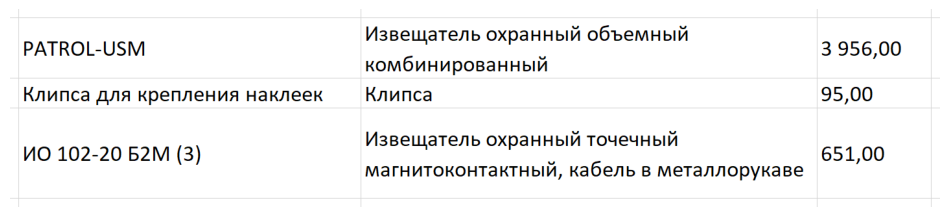

Изображение с обнаруженной таблицей (время: 0.059 секунд):


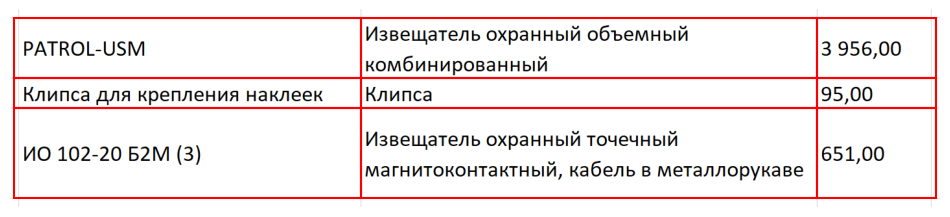

Изображение с найденными ограничивающими рамками:


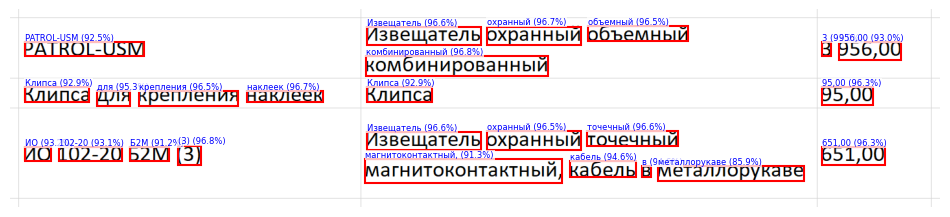

Распознанная таблица сохранена в ./results_3/table_1_base_160.xlsx
Затраченное время: 0.564 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_130.png


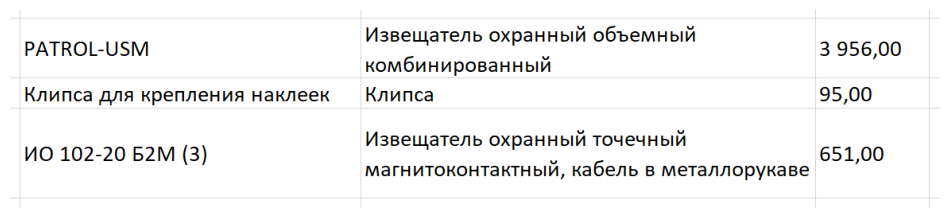

Изображение с обнаруженной таблицей (время: 0.033 секунд):


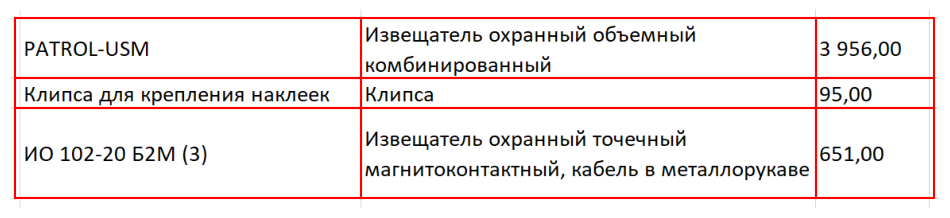

Изображение с найденными ограничивающими рамками:


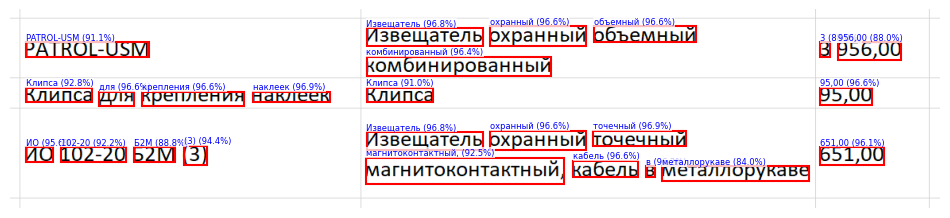

Распознанная таблица сохранена в ./results_3/table_1_base_130.xlsx
Затраченное время: 0.401 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_100.png


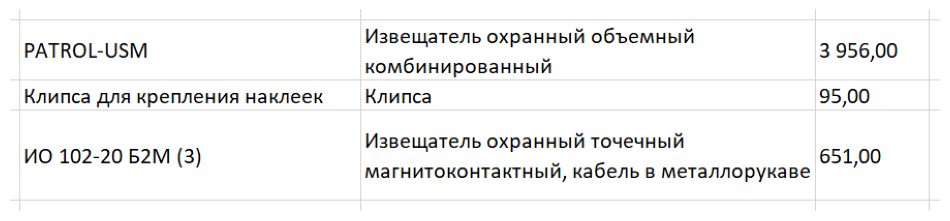

Изображение с обнаруженной таблицей (время: 0.025 секунд):


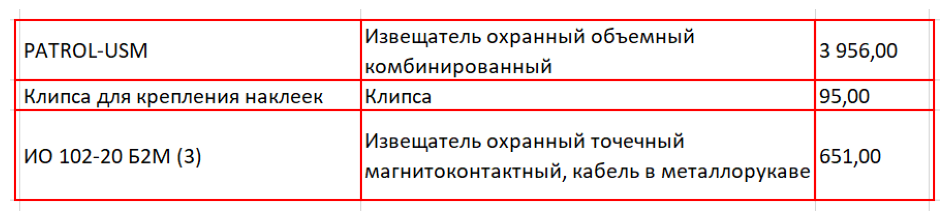

Изображение с найденными ограничивающими рамками:


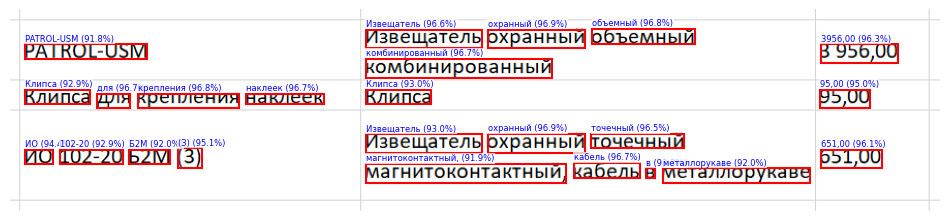

Распознанная таблица сохранена в ./results_3/table_1_base_100.xlsx
Затраченное время: 0.394 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_070.png


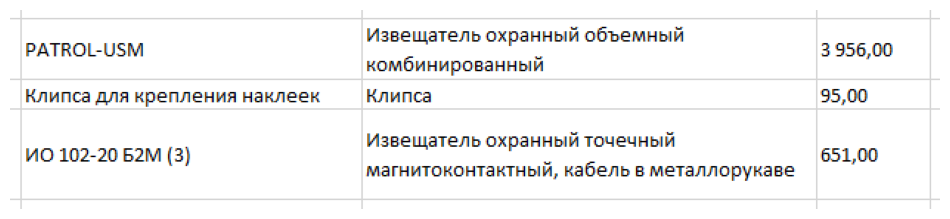

Изображение с обнаруженной таблицей (время: 0.016 секунд):


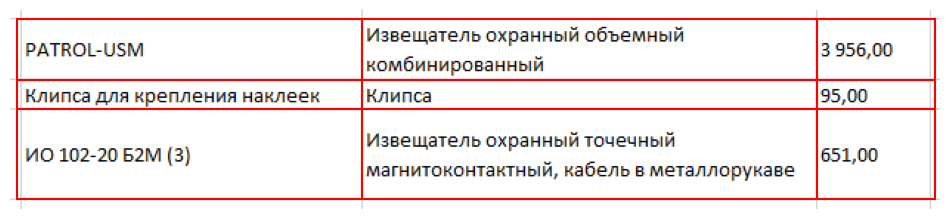

Изображение с найденными ограничивающими рамками:


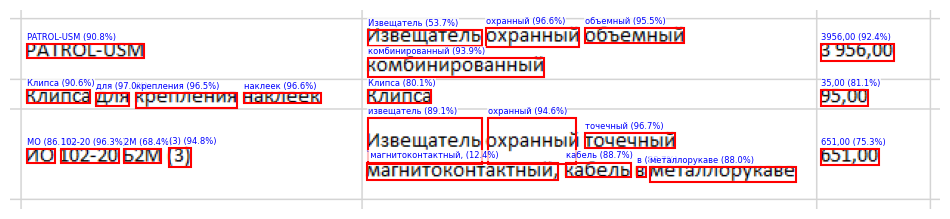

Распознанная таблица сохранена в ./results_3/table_1_base_070.xlsx
Затраченное время: 0.385 секунд
Всего ошибок: 7
Точность распознавания: 0.961


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"35,00"
2,MO 102-20 2M (3),"извещатель охранный точечный `магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_160.png


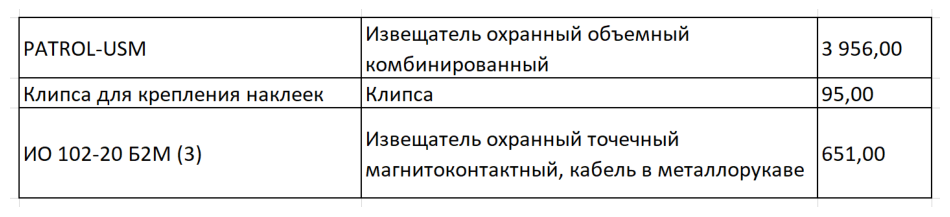

Изображение с обнаруженной таблицей (время: 0.050 секунд):


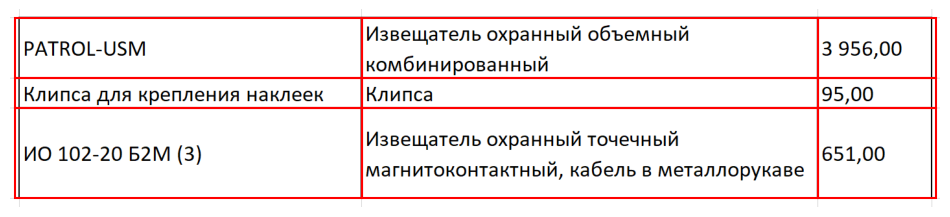

Изображение с найденными ограничивающими рамками:


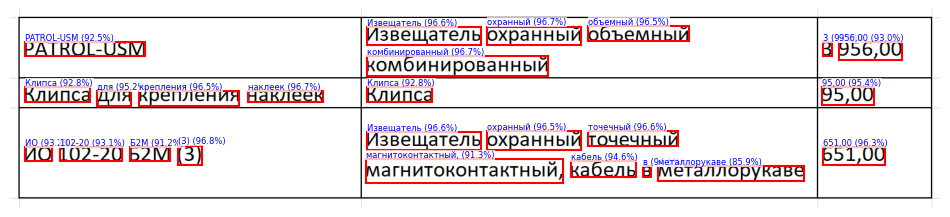

Распознанная таблица сохранена в ./results_3/table_1_base_contrast_160.xlsx
Затраченное время: 0.501 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_130.png


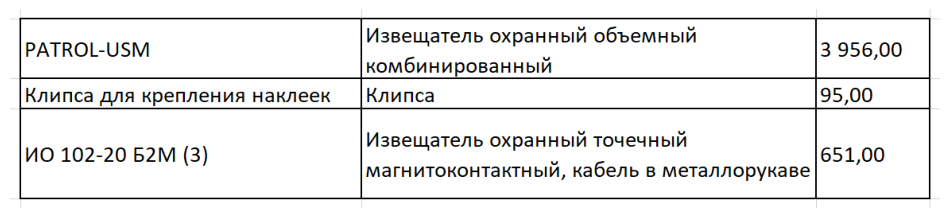

Изображение с обнаруженной таблицей (время: 0.033 секунд):


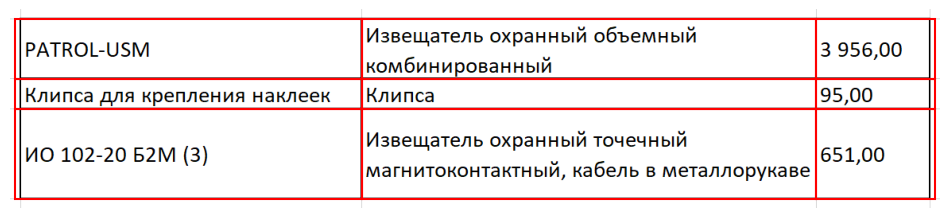

Изображение с найденными ограничивающими рамками:


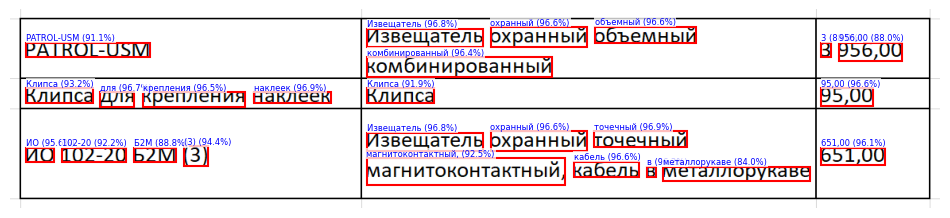

Распознанная таблица сохранена в ./results_3/table_1_base_contrast_130.xlsx
Затраченное время: 0.425 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_100.png


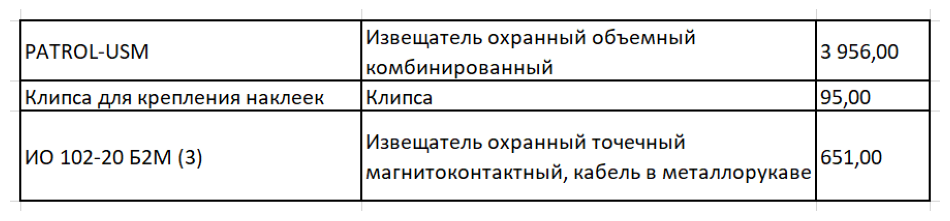

Изображение с обнаруженной таблицей (время: 0.028 секунд):


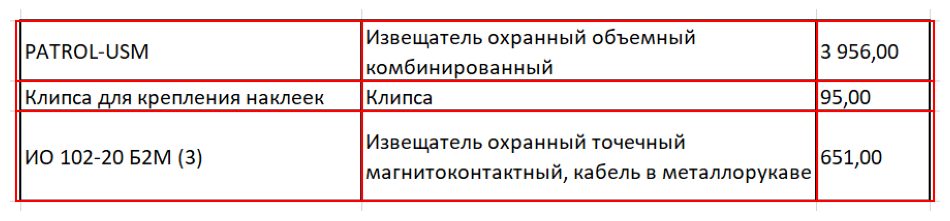

Изображение с найденными ограничивающими рамками:


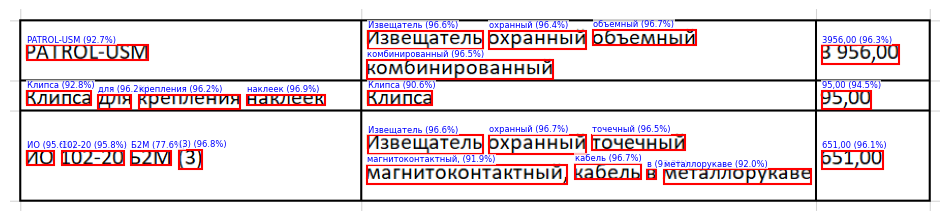

Распознанная таблица сохранена в ./results_3/table_1_base_contrast_100.xlsx
Затраченное время: 0.448 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_base_contrast_070.png


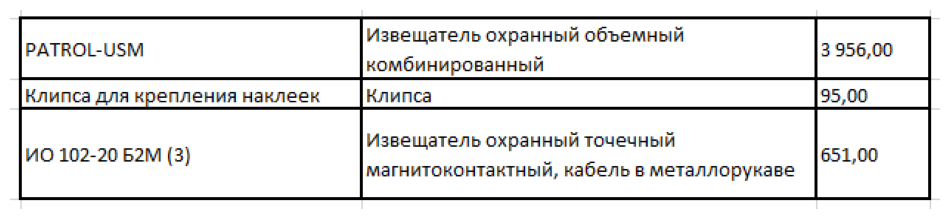

Изображение с обнаруженной таблицей (время: 0.010 секунд):


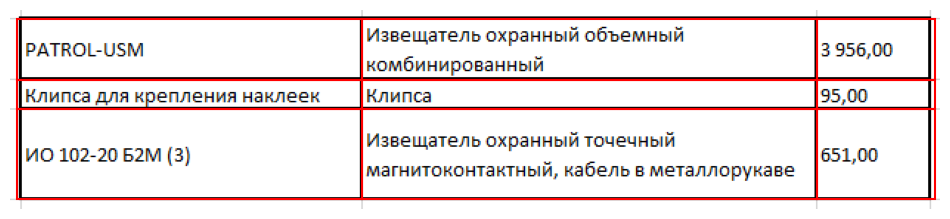

Изображение с найденными ограничивающими рамками:


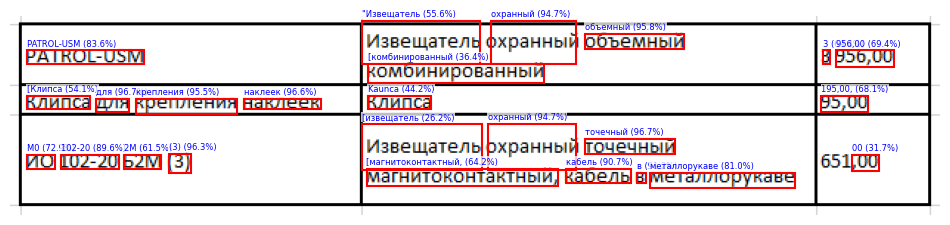

Распознанная таблица сохранена в ./results_3/table_1_base_contrast_070.xlsx
Затраченное время: 0.395 секунд
Всего ошибок: 22
Точность распознавания: 0.876


,0,1,2
0,PATROL-USM,"""Извещатель охранный объемный [комбинированный","3 956,00"
1,[Клипса для крепления наклеек,Kaunca,"195,00,"
2,M0 102-20 2M (3),"[извещатель охранный точечный [магнитоконтактный, кабель в металлорукаве",00



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_160.png


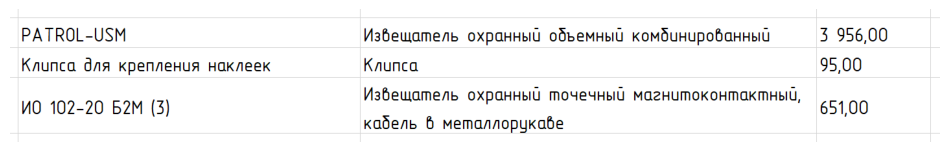

Изображение с обнаруженной таблицей (время: 0.051 секунд):


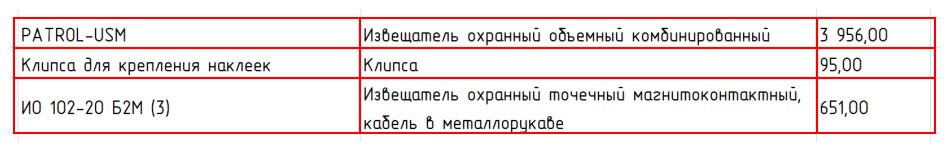

Изображение с найденными ограничивающими рамками:


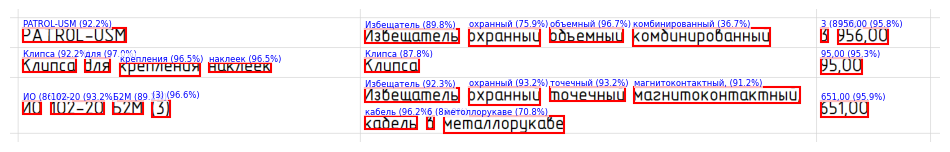

Распознанная таблица сохранена в ./results_3/table_1_gost_160.xlsx
Затраченное время: 0.390 секунд
Всего ошибок: 4
Точность распознавания: 0.978


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный, кабель 6 метоллорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_130.png


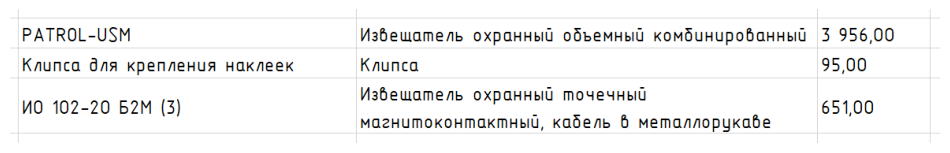

Изображение с обнаруженной таблицей (время: 0.046 секунд):


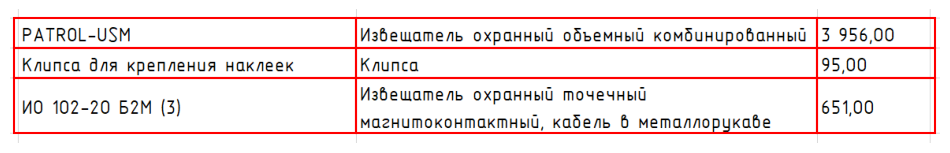

Изображение с найденными ограничивающими рамками:


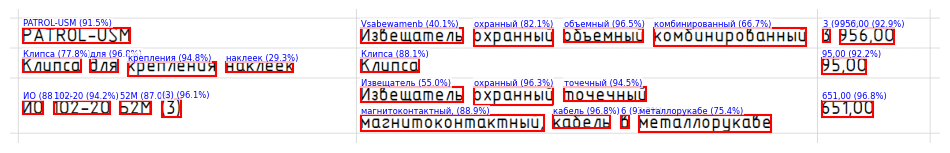

Распознанная таблица сохранена в ./results_3/table_1_gost_130.xlsx
Затраченное время: 0.443 секунд
Всего ошибок: 15
Точность распознавания: 0.916


,0,1,2
0,PATROL-USM,Vsabewamenb охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_100.png


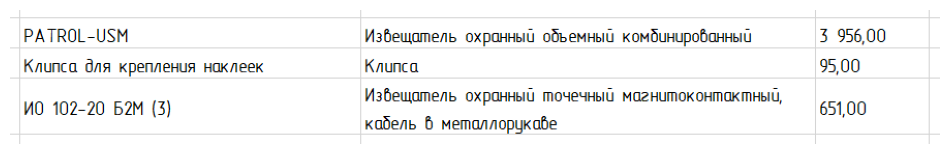

Изображение с обнаруженной таблицей (время: 0.027 секунд):


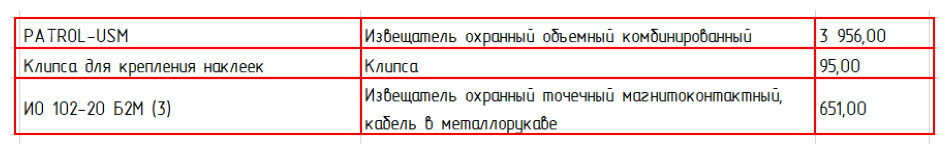

Изображение с найденными ограничивающими рамками:


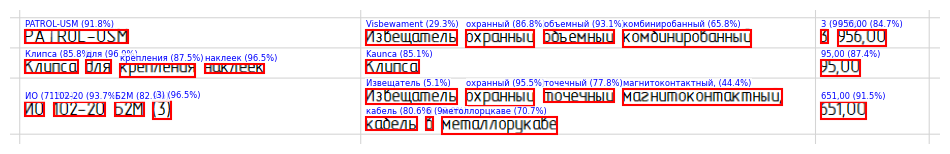

Распознанная таблица сохранена в ./results_3/table_1_gost_100.xlsx
Затраченное время: 0.407 секунд
Всего ошибок: 21
Точность распознавания: 0.882


,0,1,2
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 метоллорцкаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_070.png


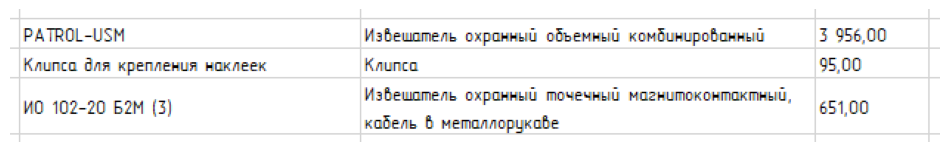

Изображение с обнаруженной таблицей (время: 0.014 секунд):


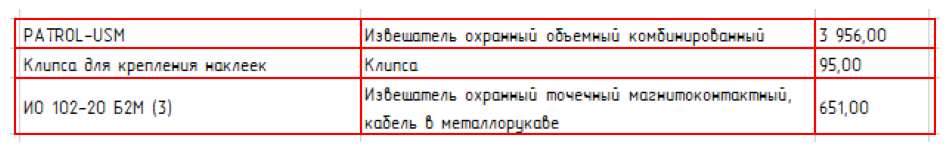

Изображение с найденными ограничивающими рамками:


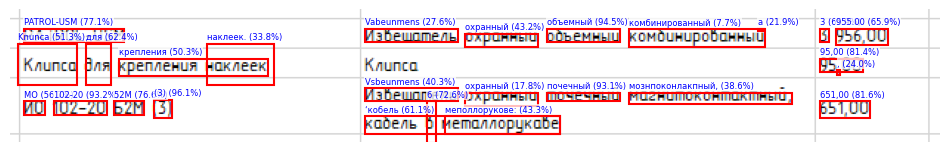

Распознанная таблица сохранена в ./results_3/table_1_gost_070.xlsx
Затраченное время: 0.464 секунд
Всего ошибок: 55
Точность распознавания: 0.691


,0,1,2
0,PATROL-USM,a Vabeunmens охранный объемный комбинированный,3 955.00
1,Knunca для крепления наклеек.,,"95,00 ,"
2,MO 102-20 52M (3),"Vsbeunmens охранный почечный мознпоконлакпный, ‘кобель 6 меполлорукове:","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_160.png


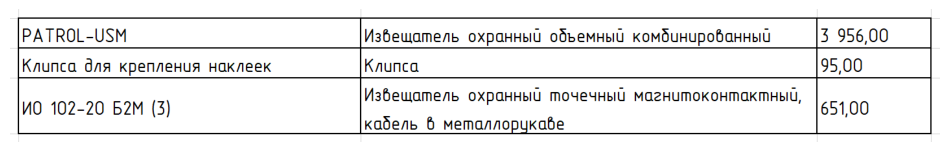

Изображение с обнаруженной таблицей (время: 0.046 секунд):


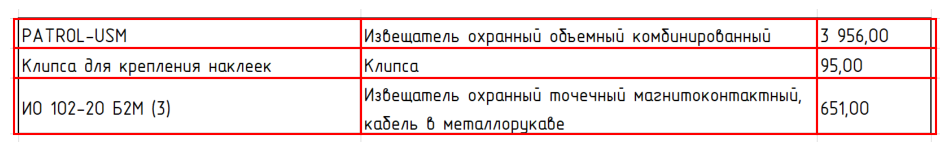

Изображение с найденными ограничивающими рамками:


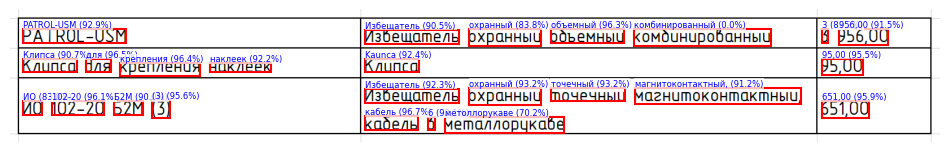

Распознанная таблица сохранена в ./results_3/table_1_gost_contrast_160.xlsx
Затраченное время: 0.571 секунд
Всего ошибок: 10
Точность распознавания: 0.944


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный, кабель 6 метоллорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_130.png


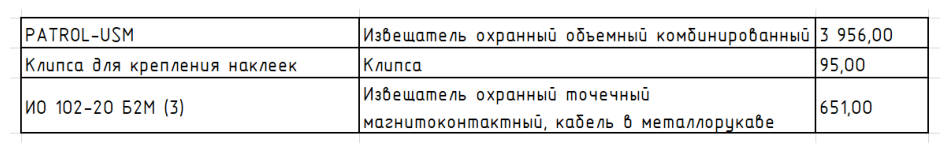

Изображение с обнаруженной таблицей (время: 0.031 секунд):


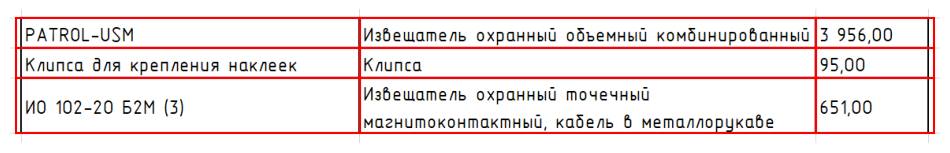

Изображение с найденными ограничивающими рамками:


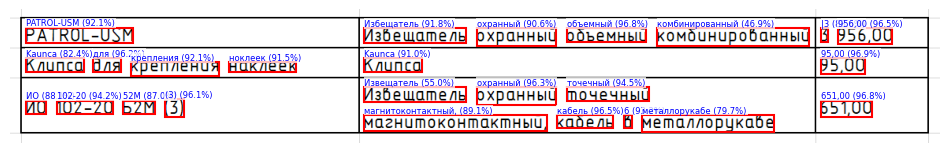

Распознанная таблица сохранена в ./results_3/table_1_gost_contrast_130.xlsx
Затраченное время: 0.480 секунд
Всего ошибок: 19
Точность распознавания: 0.893


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"|3 956,00"
1,Kaunca для крепления ноклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_100.png


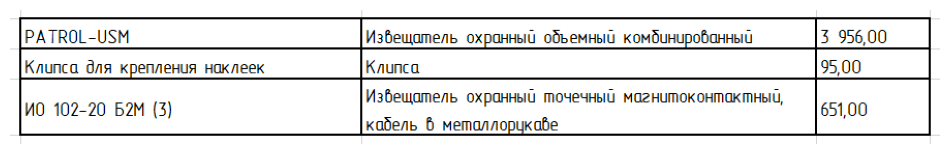

Изображение с обнаруженной таблицей (время: 0.032 секунд):


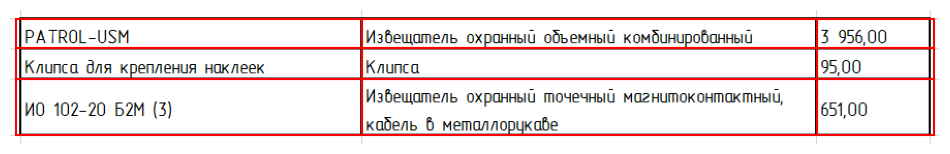

Изображение с найденными ограничивающими рамками:


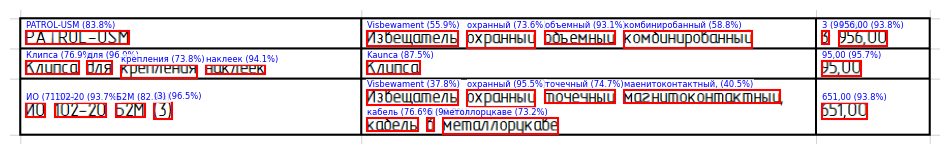

Распознанная таблица сохранена в ./results_3/table_1_gost_contrast_100.xlsx
Затраченное время: 0.426 секунд
Всего ошибок: 33
Точность распознавания: 0.815


,0,1,2
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Visbewament охранный точечный маенитоконтактный, кабель 6 метоллорцкаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_1_gost_contrast_070.png


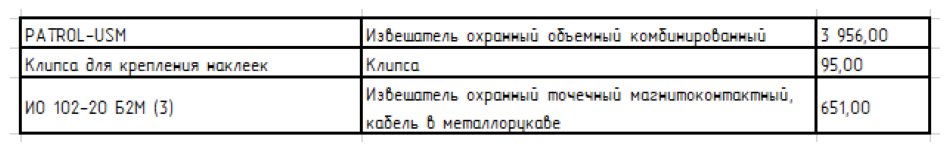

Изображение с обнаруженной таблицей (время: 0.015 секунд):


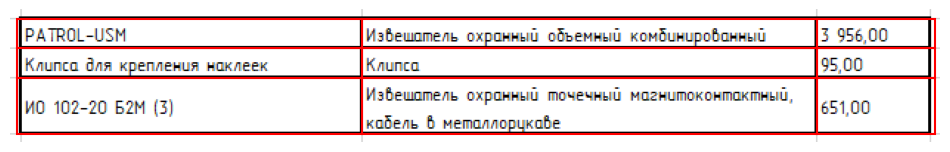

Изображение с найденными ограничивающими рамками:


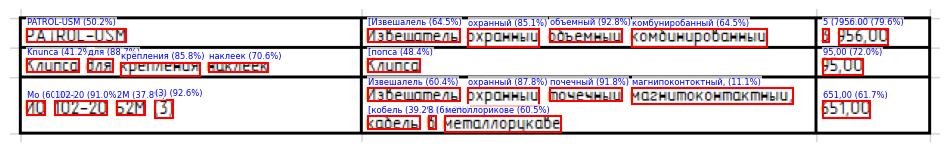

Распознанная таблица сохранена в ./results_3/table_1_gost_contrast_070.xlsx
Затраченное время: 0.360 секунд
Всего ошибок: 32
Точность распознавания: 0.820


,0,1,2
0,PATROL-USM,[Извешалель охранный объемный комбуниробанный,5 956.00
1,Knunca для крепления наклеек,[попса,"95,00"
2,Мо 102-20 2M (3),"Извешалель охранный почечный магнипоконтоктный, [кобель 8 меполлорикове","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_160.png


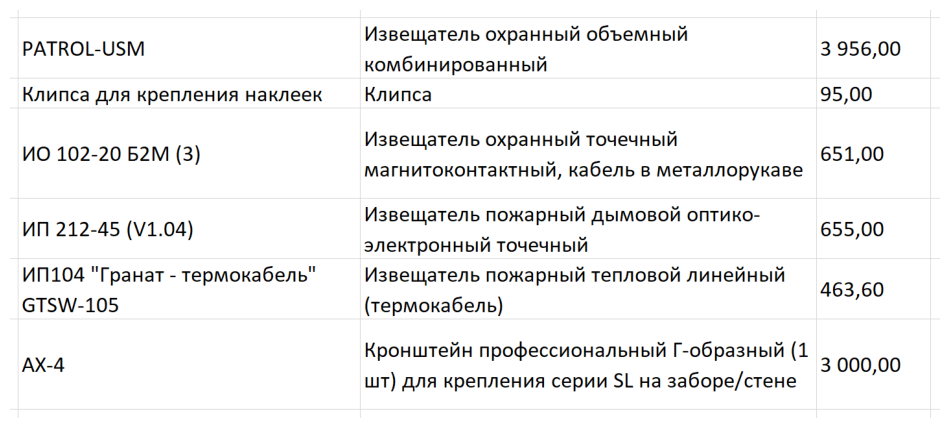

Изображение с обнаруженной таблицей (время: 0.166 секунд):


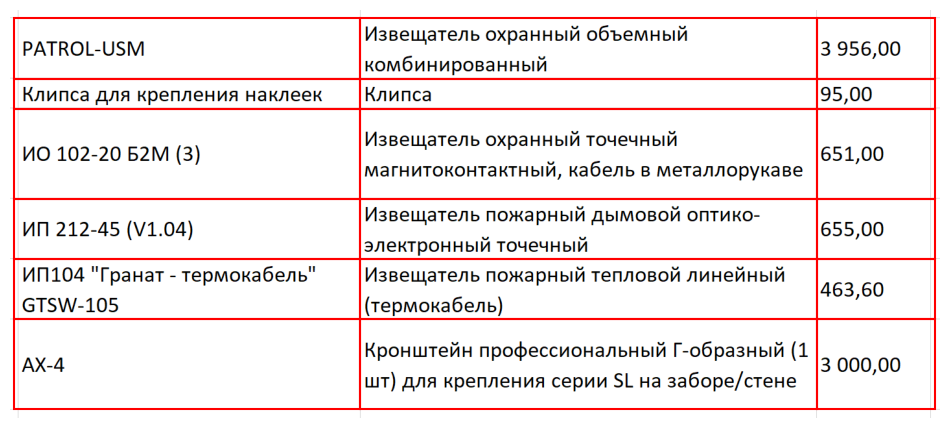

Изображение с найденными ограничивающими рамками:


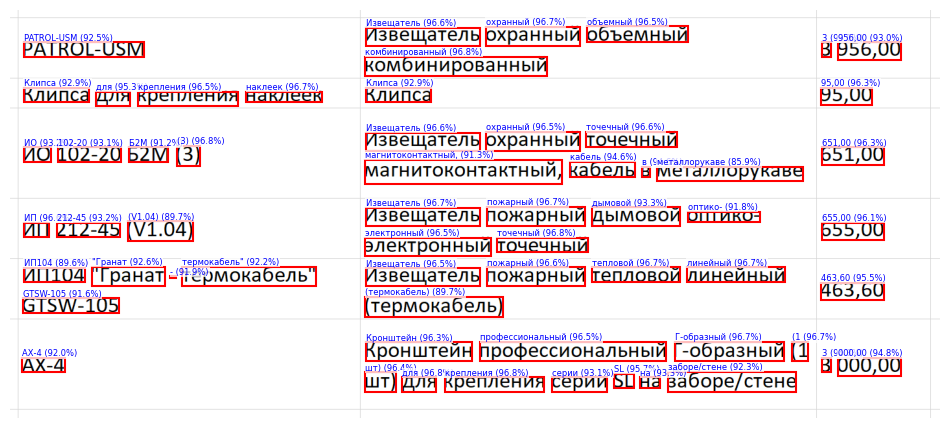

Распознанная таблица сохранена в ./results_3/table_2_base_160.xlsx
Затраченное время: 0.824 секунд
Всего ошибок: 2
Точность распознавания: 0.995


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_130.png


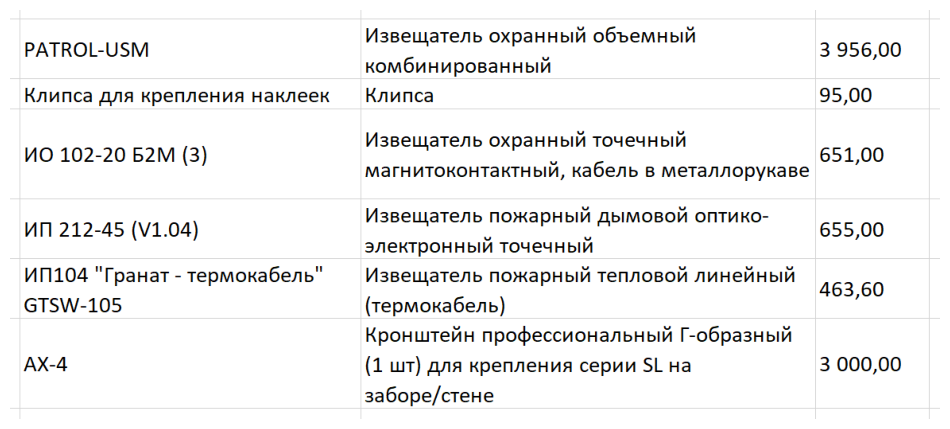

Изображение с обнаруженной таблицей (время: 0.074 секунд):


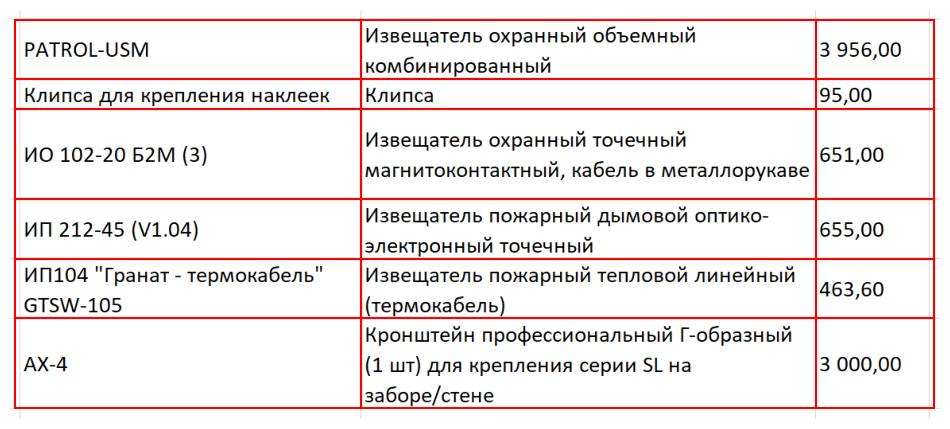

Изображение с найденными ограничивающими рамками:


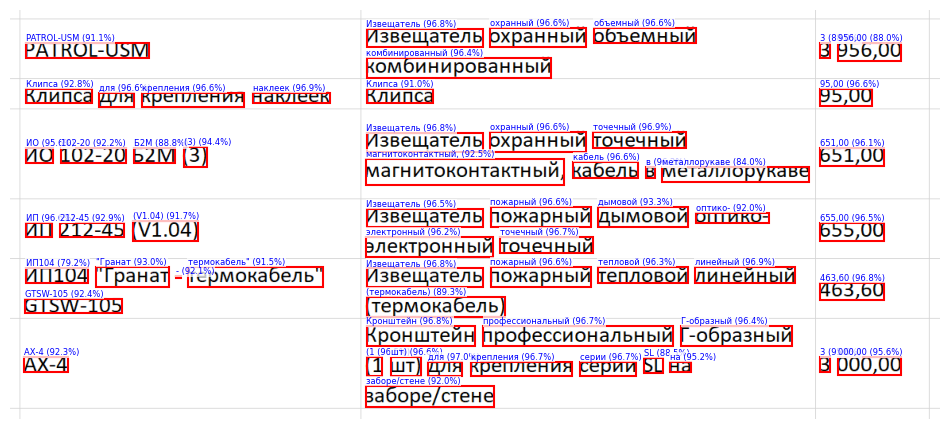

Распознанная таблица сохранена в ./results_3/table_2_base_130.xlsx
Затраченное время: 0.887 секунд
Всего ошибок: 2
Точность распознавания: 0.995


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_100.png


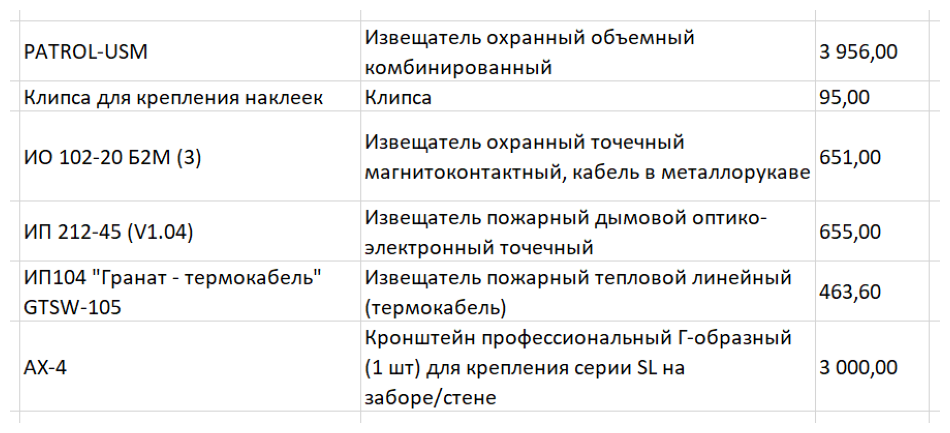

Изображение с обнаруженной таблицей (время: 0.054 секунд):


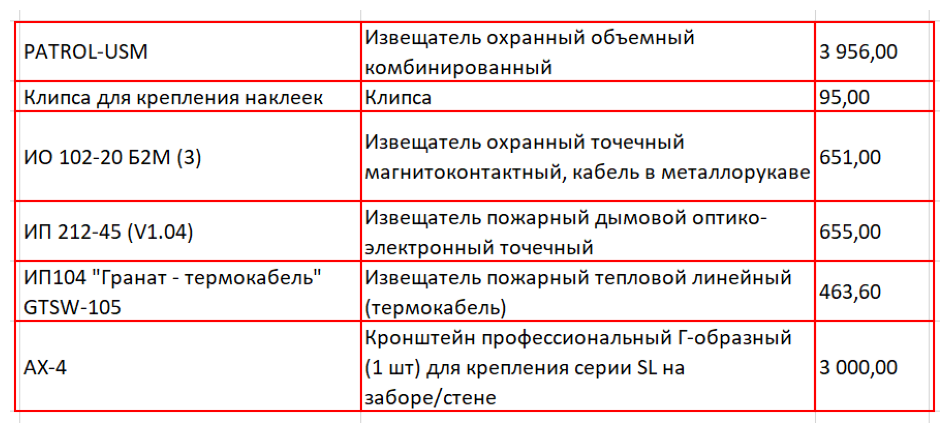

Изображение с найденными ограничивающими рамками:


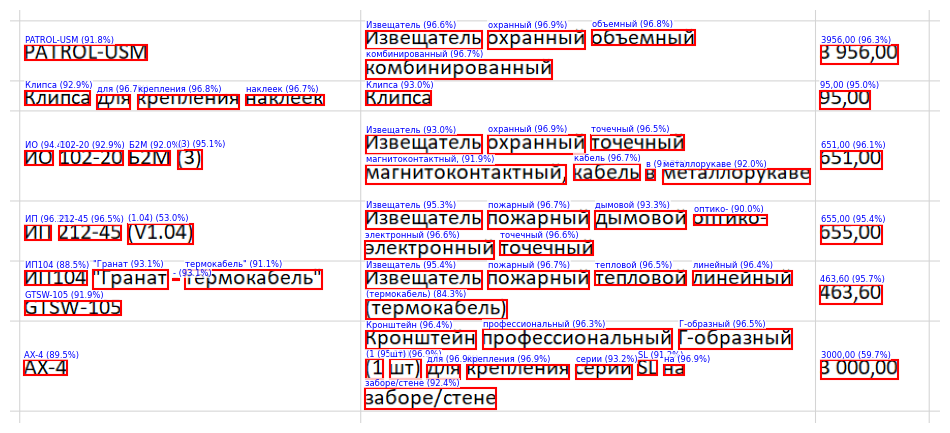

Распознанная таблица сохранена в ./results_3/table_2_base_100.xlsx
Затраченное время: 0.672 секунд
Всего ошибок: 1
Точность распознавания: 0.998


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
5,AX-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_070.png


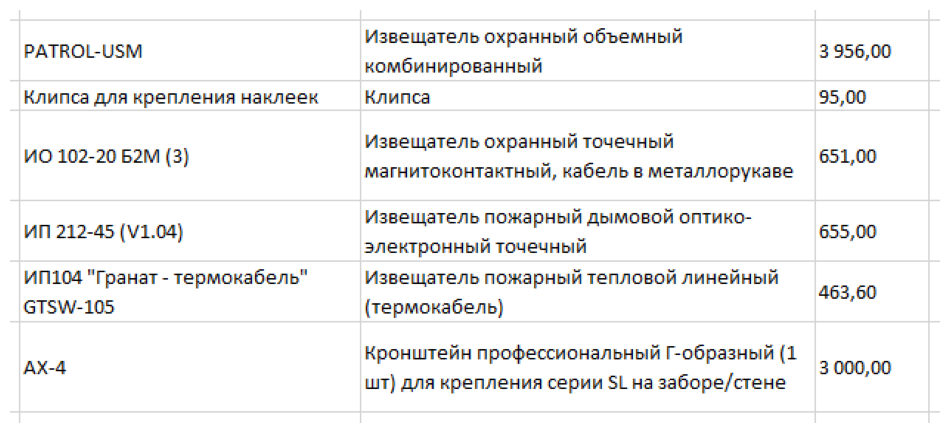

Изображение с обнаруженной таблицей (время: 0.030 секунд):


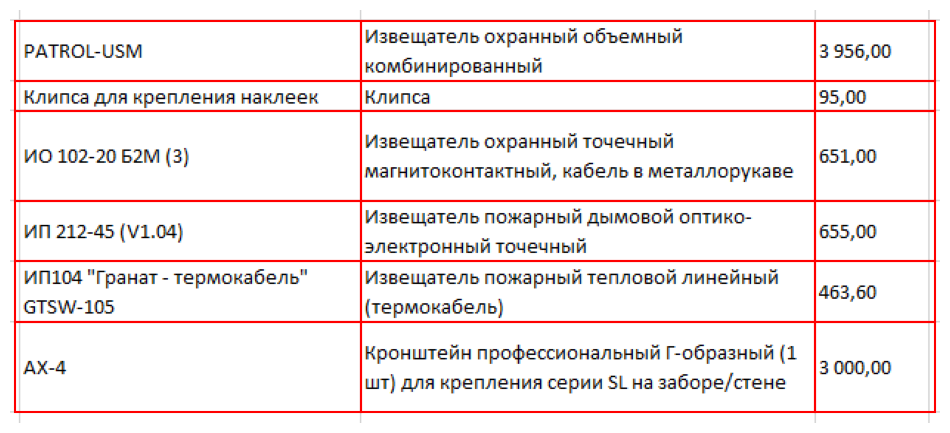

Изображение с найденными ограничивающими рамками:


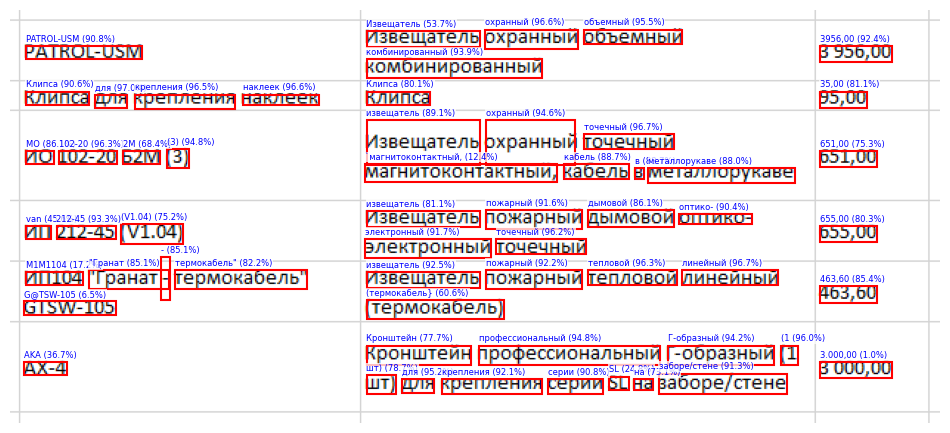

Распознанная таблица сохранена в ./results_3/table_2_base_070.xlsx
Затраченное время: 0.616 секунд
Всего ошибок: 22
Точность распознавания: 0.948


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"35,00"
2,MO 102-20 2M (3),"извещатель охранный точечный `магнитоконтактный, кабель в металлорукаве","651,00"
3,van 212-45 (V1.04),извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"M1M1104 ""Гранат - термокабель"" G@TSW-105",извещатель пожарный тепловой линейный (термокабель},"463,60"
5,AKA,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3.000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_160.png


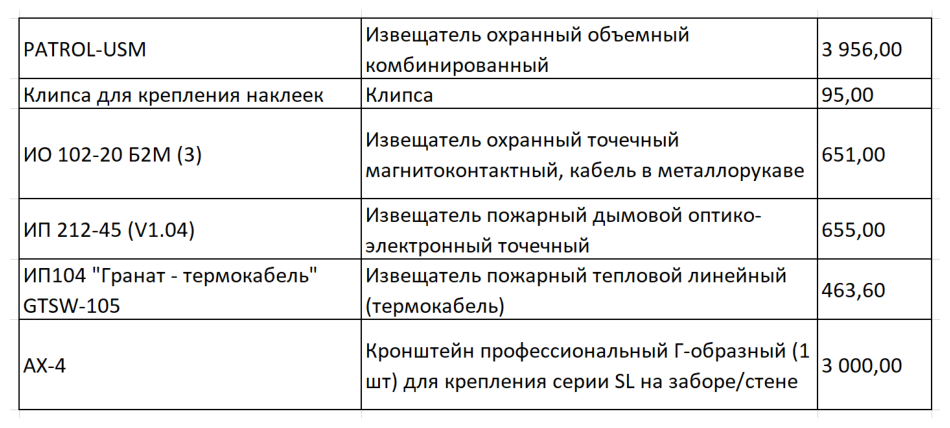

Изображение с обнаруженной таблицей (время: 0.119 секунд):


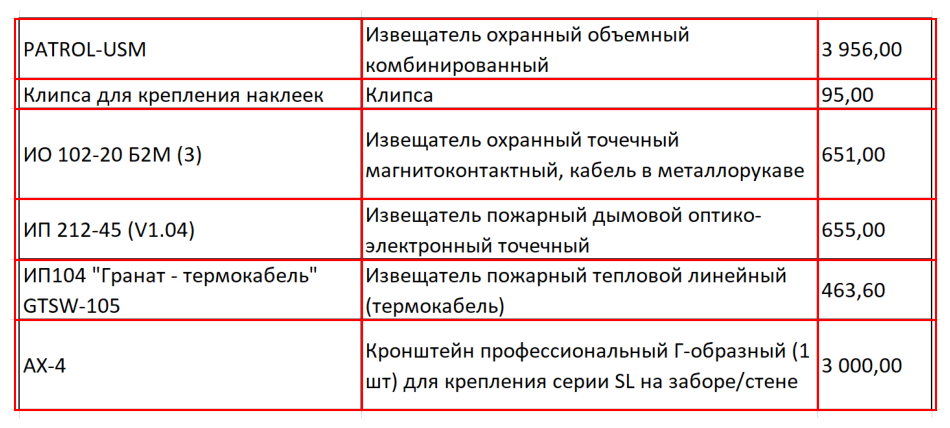

Изображение с найденными ограничивающими рамками:


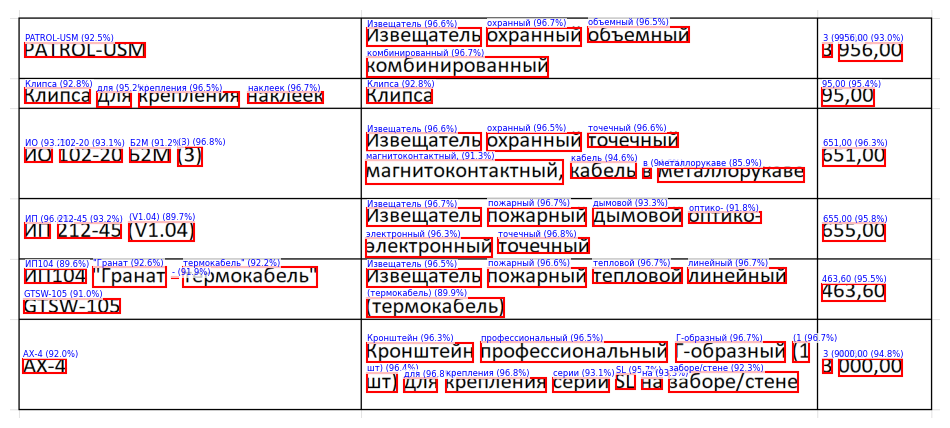

Распознанная таблица сохранена в ./results_3/table_2_base_contrast_160.xlsx
Затраченное время: 0.790 секунд
Всего ошибок: 2
Точность распознавания: 0.995


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_130.png


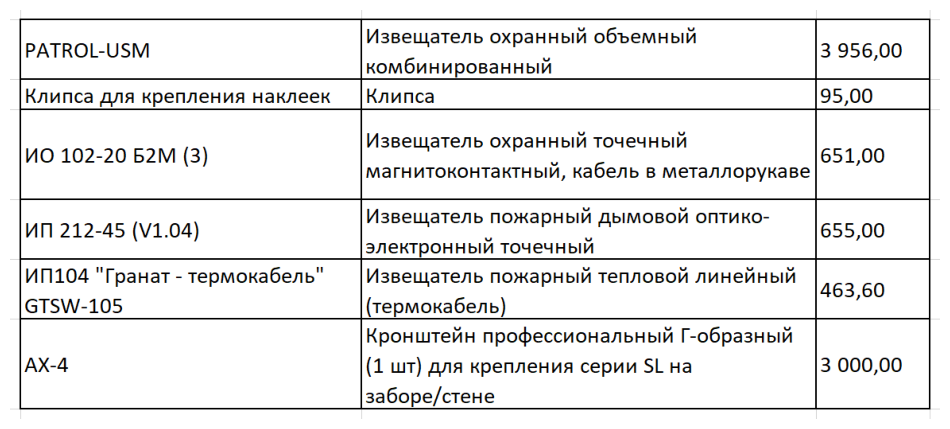

Изображение с обнаруженной таблицей (время: 0.121 секунд):


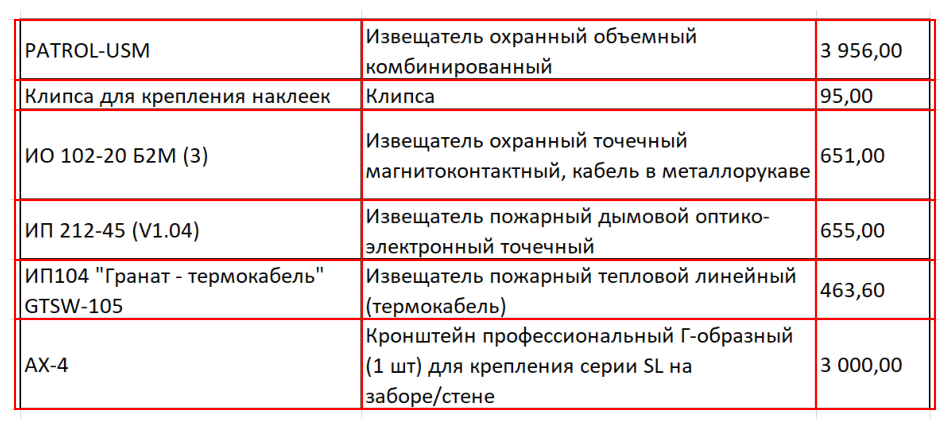

Изображение с найденными ограничивающими рамками:


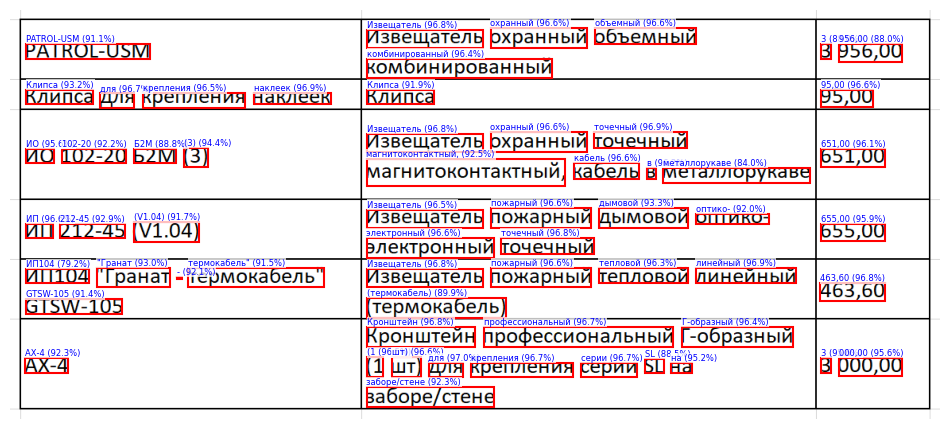

Распознанная таблица сохранена в ./results_3/table_2_base_contrast_130.xlsx
Затраченное время: 0.773 секунд
Всего ошибок: 2
Точность распознавания: 0.995


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_100.png


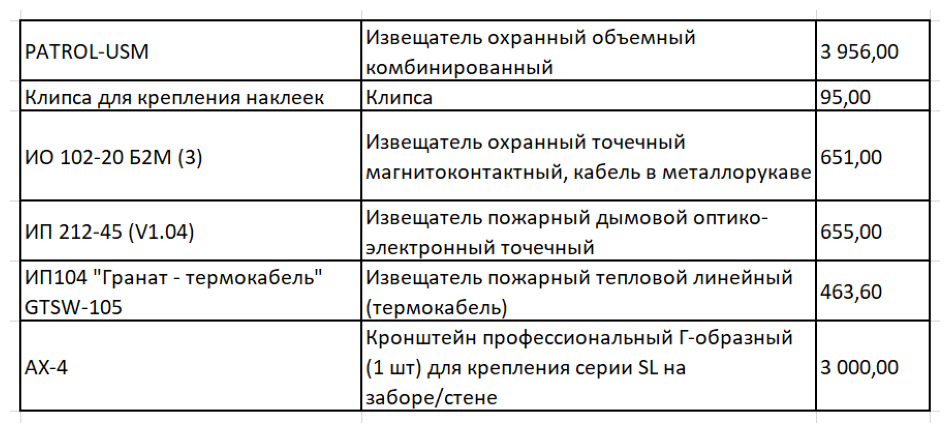

Изображение с обнаруженной таблицей (время: 0.064 секунд):


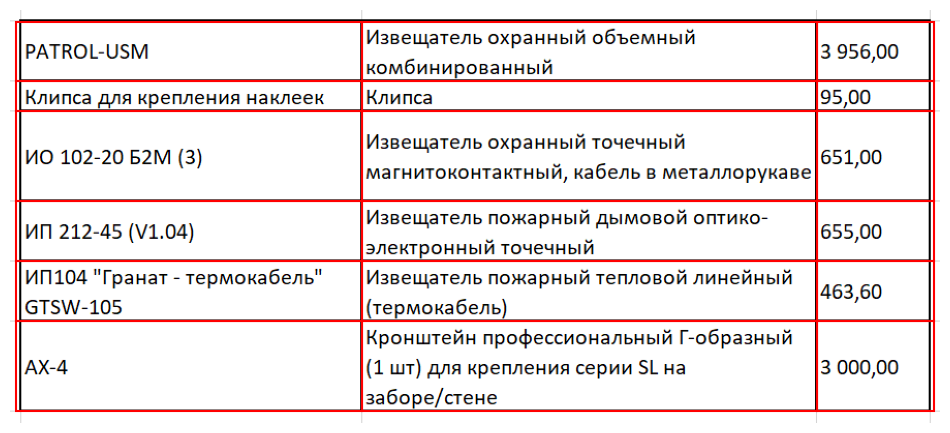

Изображение с найденными ограничивающими рамками:


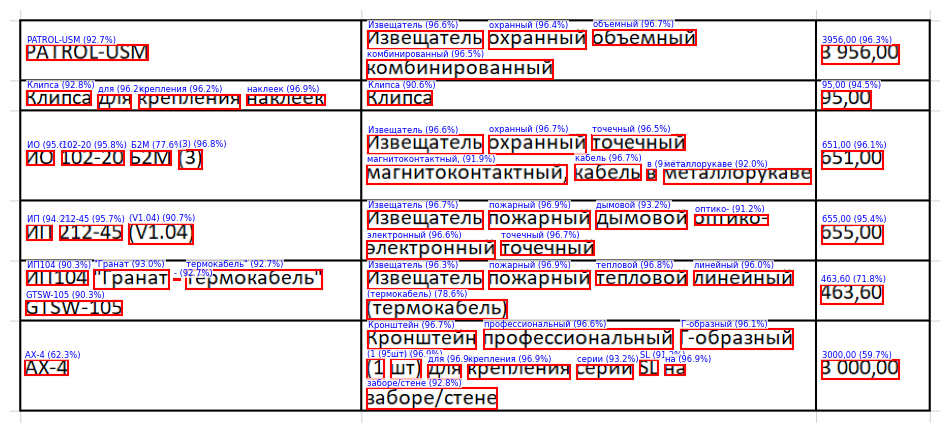

Распознанная таблица сохранена в ./results_3/table_2_base_contrast_100.xlsx
Затраченное время: 0.703 секунд
Всего ошибок: 2
Точность распознавания: 0.995


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_base_contrast_070.png


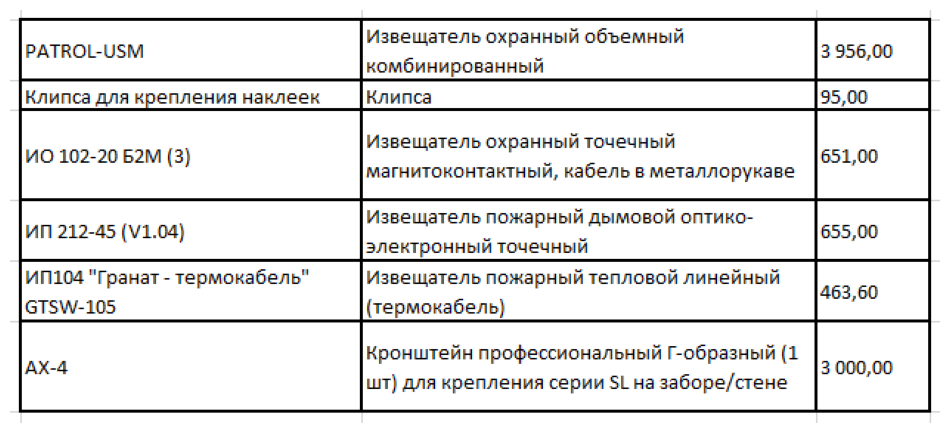

Изображение с обнаруженной таблицей (время: 0.034 секунд):


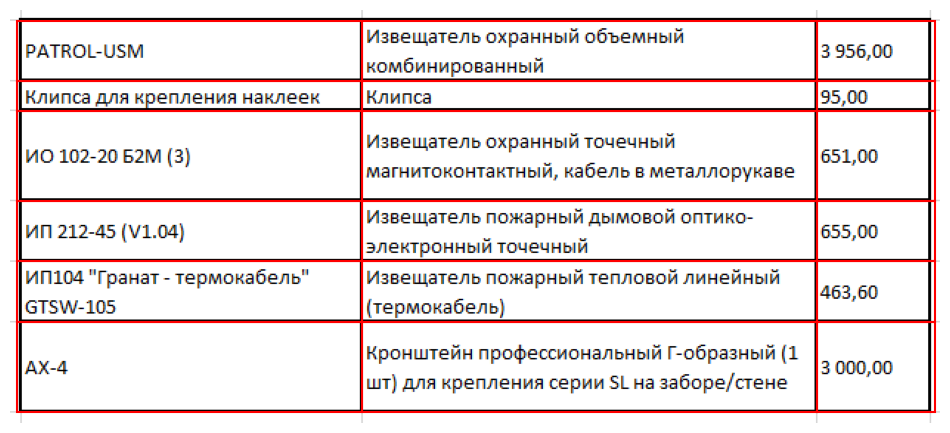

Изображение с найденными ограничивающими рамками:


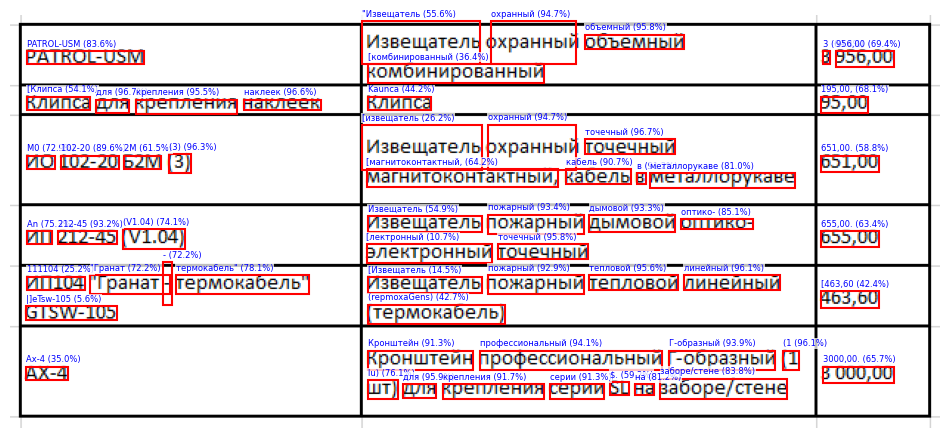

Распознанная таблица сохранена в ./results_3/table_2_base_contrast_070.xlsx
Затраченное время: 0.814 секунд
Всего ошибок: 50
Точность распознавания: 0.881


,0,1,2
0,PATROL-USM,"""Извещатель охранный объемный [комбинированный","3 956,00"
1,[Клипса для крепления наклеек,Kaunca,"195,00,"
2,M0 102-20 2M (3),"[извещатель охранный точечный [магнитоконтактный, кабель в металлорукаве","651,00."
3,An 212-45 (V1.04),Извещатель пожарный дымовой оптико- [лектронный точечный,"655,00."
4,"111104 ""Гранат - термокабель"" |]eTsw-105",[Извещатель пожарный тепловой линейный (repmoxaGens),"[463,60"
5,Ax-4,Кронштейн профессиональный Г-образный (1 lu) для крепления серии $. на заборе/стене,"3000,00."



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_160.png


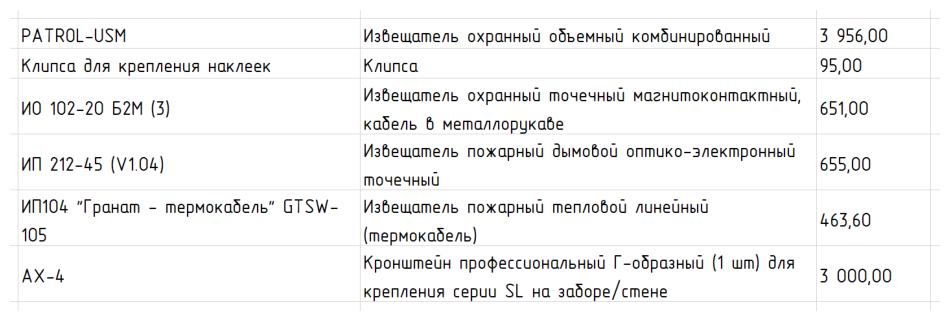

Изображение с обнаруженной таблицей (время: 0.110 секунд):


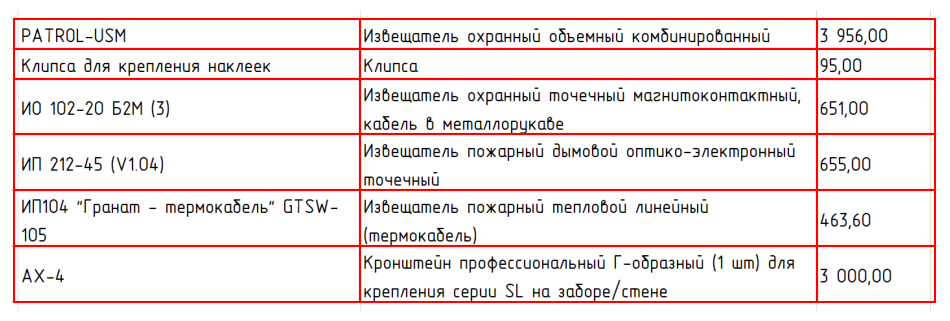

Изображение с найденными ограничивающими рамками:


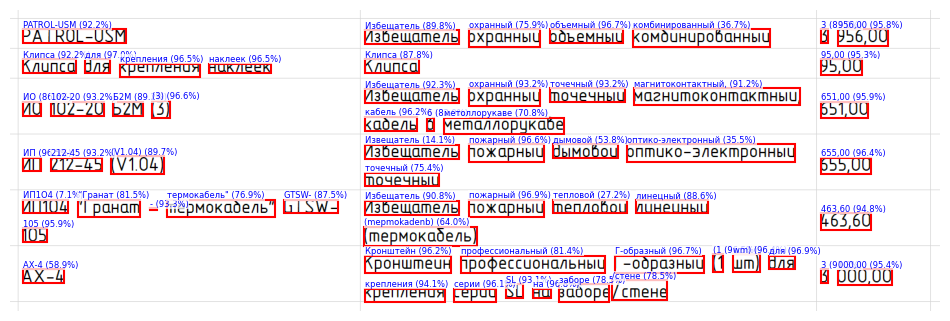

Распознанная таблица сохранена в ./results_3/table_2_gost_160.xlsx
Затраченное время: 0.808 секунд
Всего ошибок: 23
Точность распознавания: 0.945


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный, кабель 6 метоллорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00"
4,"ИП1О4 “Гранат - термокабель"" GTSW- 105",Избещатель пожарный тепловой линецный (mepmokadenb),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 wm) для крепления серии SL на заборе /стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_130.png


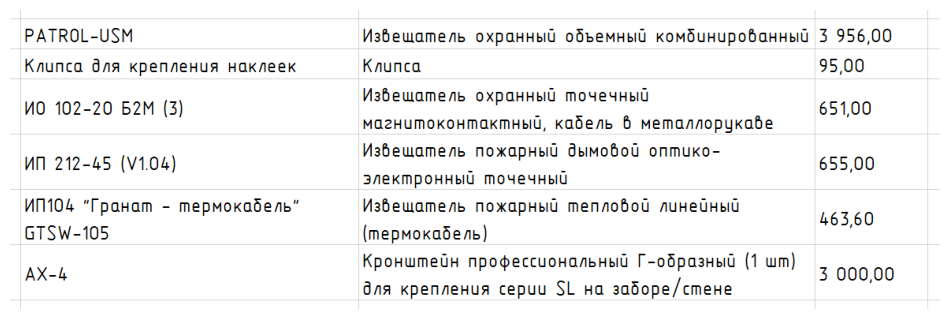

Изображение с обнаруженной таблицей (время: 0.131 секунд):


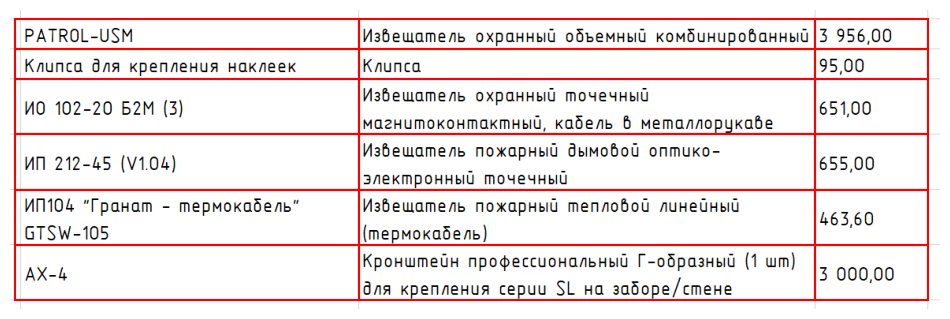

Изображение с найденными ограничивающими рамками:


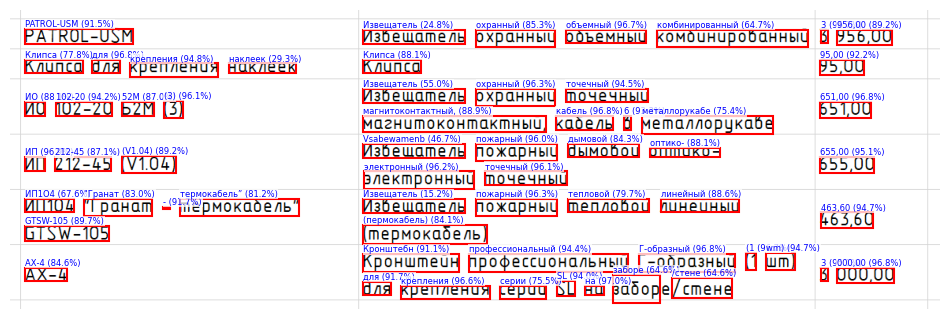

Распознанная таблица сохранена в ./results_3/table_2_gost_130.xlsx
Затраченное время: 0.916 секунд
Всего ошибок: 23
Точность распознавания: 0.945


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00"
3,ИП 212-45 (V1.04),Vsabewamenb пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП1О4 ""Гранат - термокабель” GTSW-105",Извещатель пожарный тепловой линейный (пермокабель),"463,60"
5,АХ-4,Кронштебн профессиональный Г-образный (1 wm) для крепления серии SL на заборе /стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_100.png


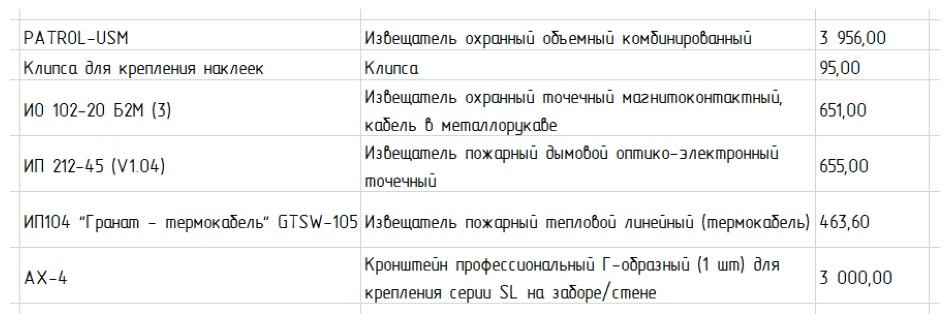

Изображение с обнаруженной таблицей (время: 0.105 секунд):


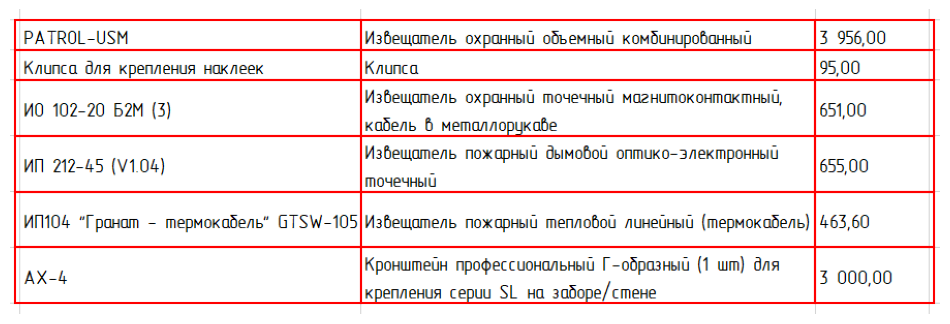

Изображение с найденными ограничивающими рамками:


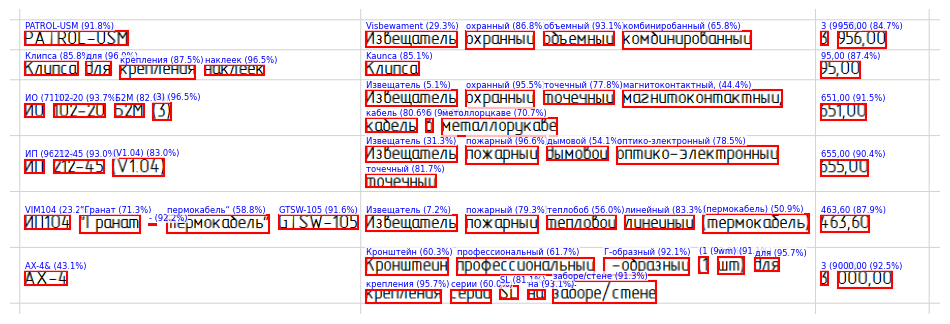

Распознанная таблица сохранена в ./results_3/table_2_gost_100.xlsx
Затраченное время: 0.781 секунд
Всего ошибок: 34
Точность распознавания: 0.919


,0,1,2
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 метоллорцкаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-злектронный точечный,"655,00"
4,VIM104 “Гранат - пермокабель“ GTSW-105,Извещатель пожарный теплобоб линейный (пермокабель),"463,60"
5,AX-4&,Кронштейн профессиональный Г-образный (1 wm) для крепления серии SL на заборе/стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_070.png


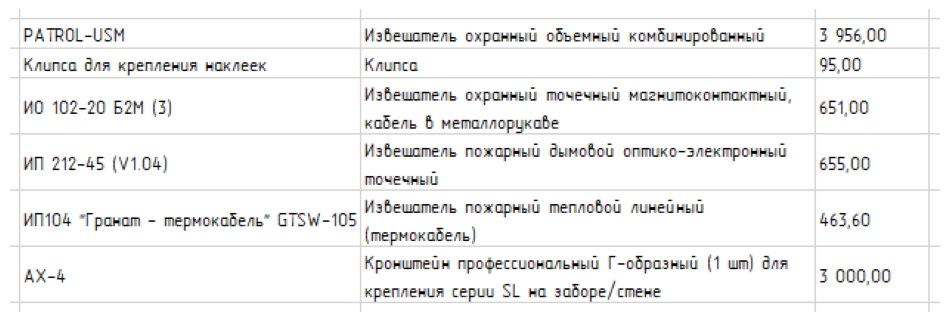

Изображение с обнаруженной таблицей (время: 0.051 секунд):


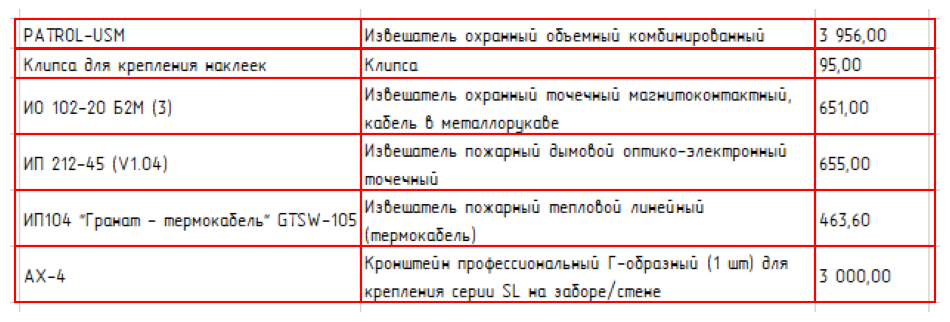

Изображение с найденными ограничивающими рамками:


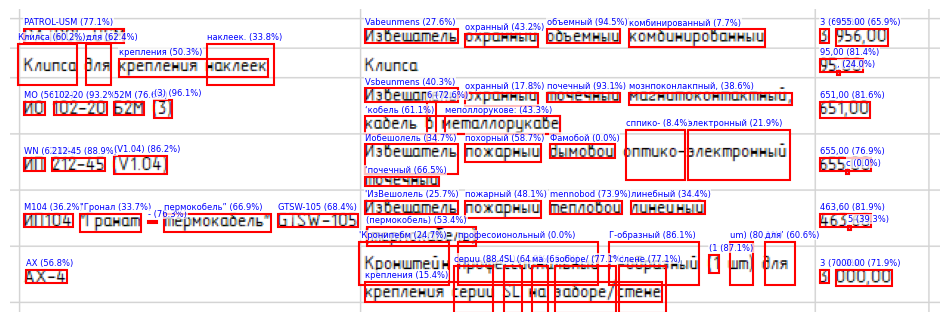

Распознанная таблица сохранена в ./results_3/table_2_gost_070.xlsx
Затраченное время: 0.887 секунд
Всего ошибок: 128
Точность распознавания: 0.695


,0,1,2
0,PATROL-USM,Vabeunmens охранный объемный комбинированный,3 955.00
1,Клилса для крепления наклеек.,,"95,00 ,"
2,MO 102-20 52M (3),"Vsbeunmens охранный почечный мознпоконлакпный, ‘кобель 6 меполлорукове:","651,00"
3,WN 212-45 (V1.04),‘почечный Иобешолель похорный Фамобой сппико- электронный,"655,00 с"
4,"M104 ""Гронал - пермокобель” GTSW-105",'ИзВешолель пожарный mennobod линебный (пермокобель),"463,60 5"
5,АХ,'Кронипебм професоионольный Г-образный (1 um) для’ крепления cepuu SL ма зоборе/ слене,3 000.00



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_160.png


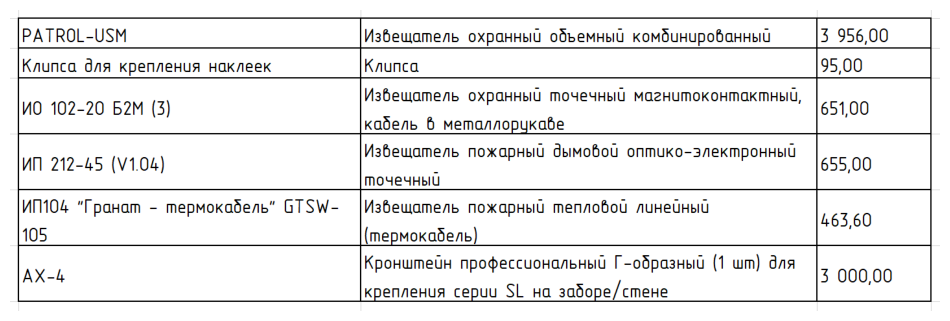

Изображение с обнаруженной таблицей (время: 0.153 секунд):


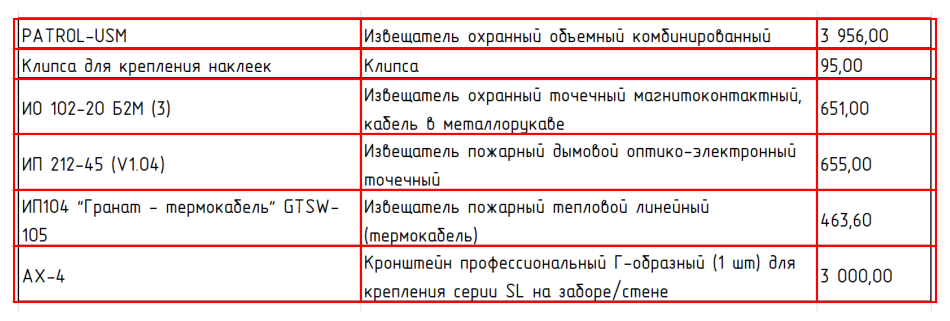

Изображение с найденными ограничивающими рамками:


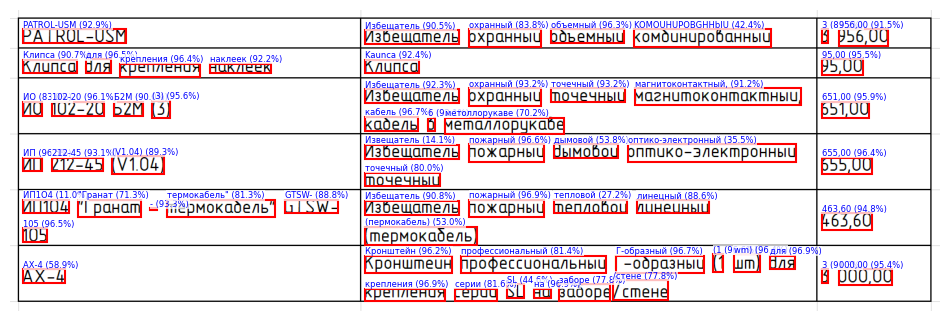

Распознанная таблица сохранена в ./results_3/table_2_gost_contrast_160.xlsx
Затраченное время: 0.934 секунд
Всего ошибок: 34
Точность распознавания: 0.919


,0,1,2
0,PATROL-USM,Избещатель охранный объемный KOMOUHUPOBGHHbIU,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Избещатель охранный точечный магнитоконтактный, кабель 6 метоллорукаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00"
4,"ИП1О4 ""Гранат - термокабель"" GTSW- 105",Избещатель пожарный тепловой линецный (пермокабель),"463,60"
5,АХ-4,Кронштейн профессиональный Г-образный (1 wm) для крепления серии SL на заборе /стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_130.png


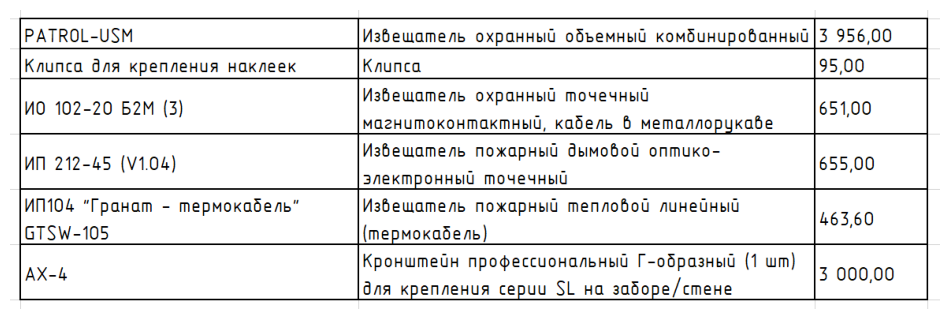

Изображение с обнаруженной таблицей (время: 0.103 секунд):


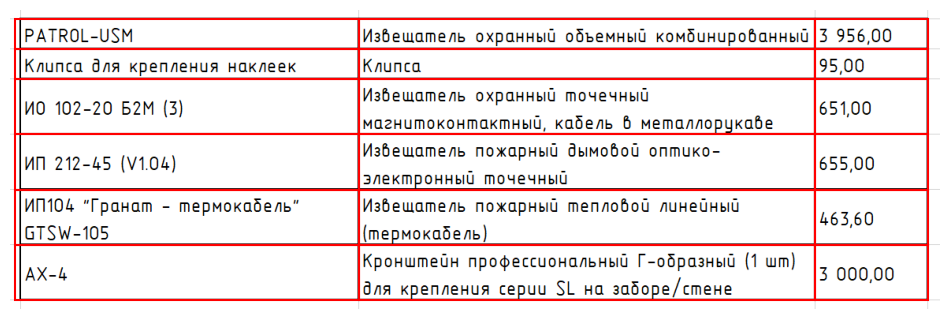

Изображение с найденными ограничивающими рамками:


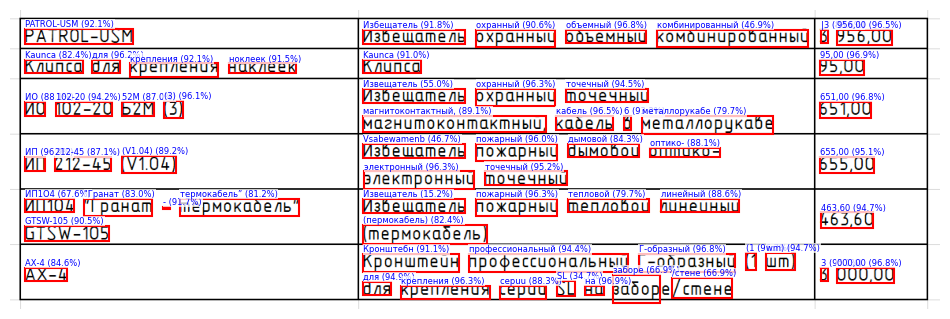

Распознанная таблица сохранена в ./results_3/table_2_gost_contrast_130.xlsx
Затраченное время: 1.041 секунд
Всего ошибок: 43
Точность распознавания: 0.898


,0,1,2
0,PATROL-USM,Избещатель охранный объемный комбинированный,"|3 956,00"
1,Kaunca для крепления ноклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00"
3,ИП 212-45 (V1.04),Vsabewamenb пожарный дымовой оптико- электронный точечный,"655,00"
4,"ИП1О4 ""Гранат - термокабель” GTSW-105",Извещатель пожарный тепловой линейный (пермокабель),"463,60"
5,АХ-4,Кронштебн профессиональный Г-образный (1 wm) для крепления cepuu SL на заборе /стене,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_100.png


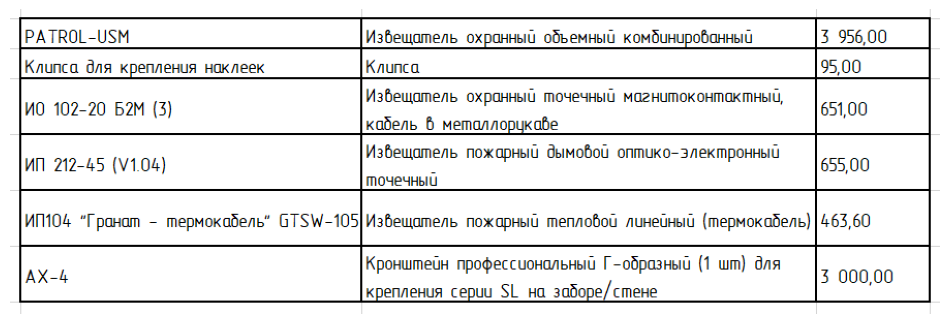

Изображение с обнаруженной таблицей (время: 0.266 секунд):


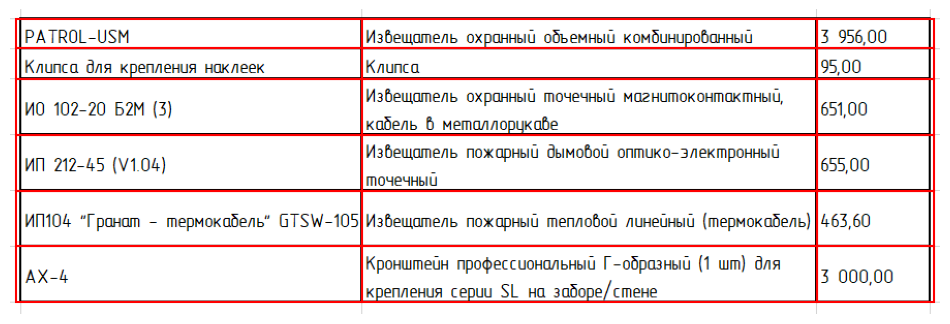

Изображение с найденными ограничивающими рамками:


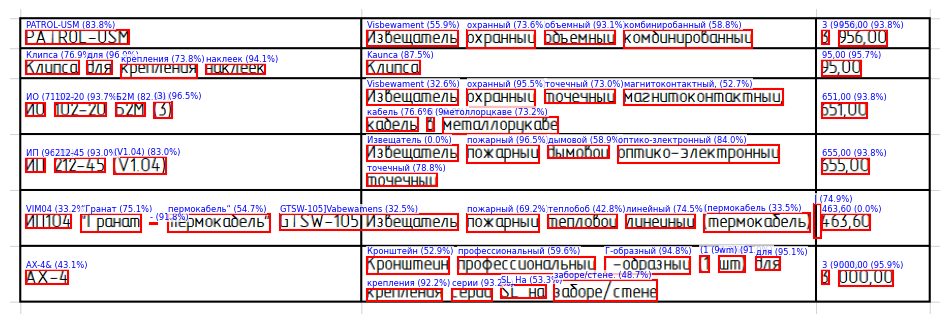

Распознанная таблица сохранена в ./results_3/table_2_gost_contrast_100.xlsx
Затраченное время: 0.769 секунд
Всего ошибок: 78
Точность распознавания: 0.814


,0,1,2
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Visbewament охранный точечный магнитоконтактный, кабель 6 метоллорцкаве","651,00"
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-злектронный точечный,"655,00"
4,VIM04 “Гранат - пермокабель“,GTSW-105]Vabewamens пожарный теплобоб линейный (пермокабель,"| 463,60"
5,AX-4&,Кронштейн профессиональный Г-образный (1 wm) для крепления серии SL_Ha заборе/стене.,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_2_gost_contrast_070.png


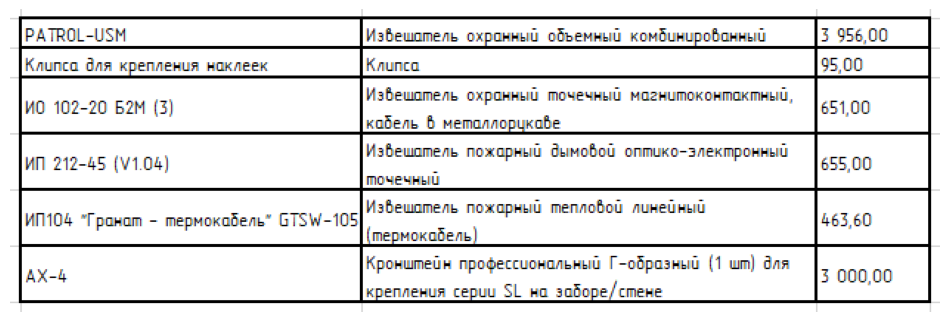

Изображение с обнаруженной таблицей (время: 0.040 секунд):


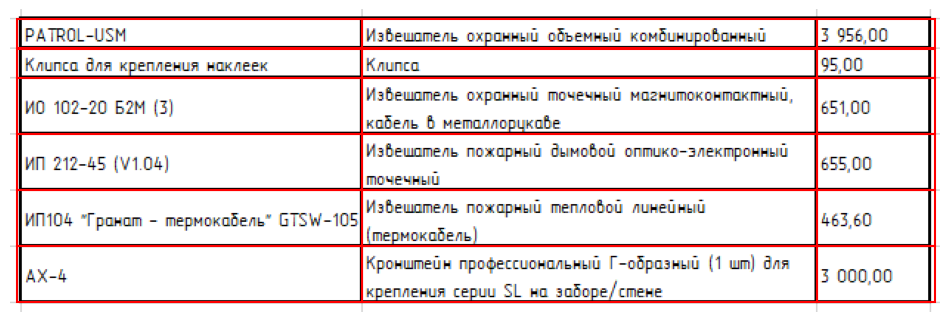

Изображение с найденными ограничивающими рамками:


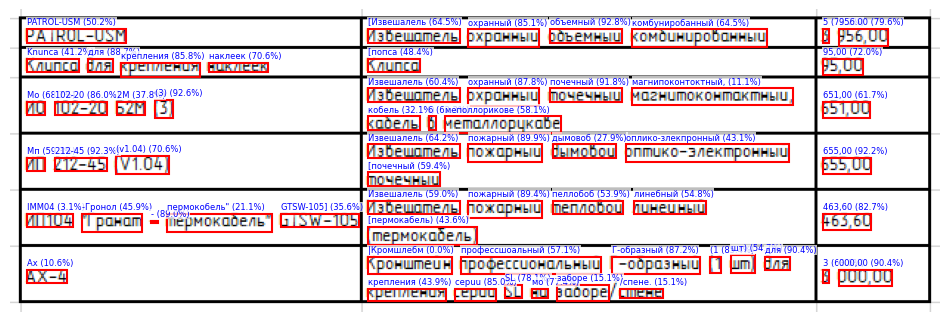

Распознанная таблица сохранена в ./results_3/table_2_gost_contrast_070.xlsx
Затраченное время: 0.709 секунд
Всего ошибок: 81
Точность распознавания: 0.807


,0,1,2
0,PATROL-USM,[Извешалель охранный объемный комбуниробанный,5 956.00
1,Knunca для крепления наклеек,[попса,"95,00"
2,Mo 102-20 2M (3),"Извешалель охранный почечный магнипоконтоктный, кобель 6 меполлорикове","651,00"
3,Мп 212-45 (v1.04),Извешалель пожарный дымовоб оплико-злекпронный [почечный,"655,00"
4,"IMM04 -Гронол - пермокобель"" GTSW-105]",Извешалель пожарный пеллобоб линебный [пермокабель),"463,60"
5,Ах,|Кромшлебм профессшоальный Г-образный (1 шт) для крепления cepuu SL мо заборе /спене.,"3 000,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_160.png


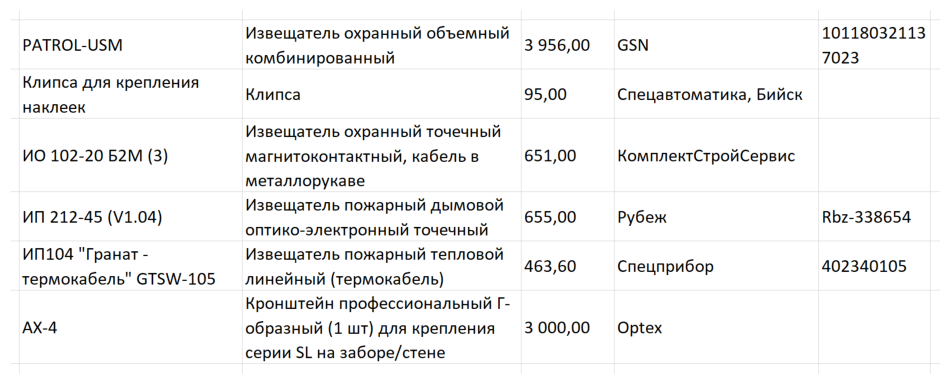

Изображение с обнаруженной таблицей (время: 0.125 секунд):


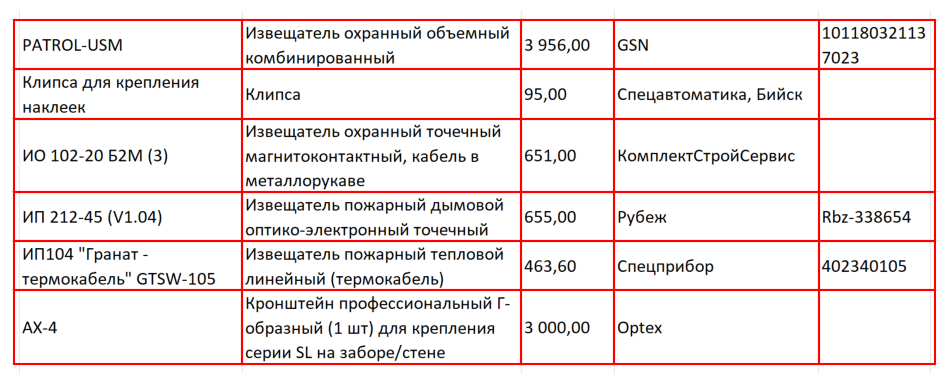

Изображение с найденными ограничивающими рамками:


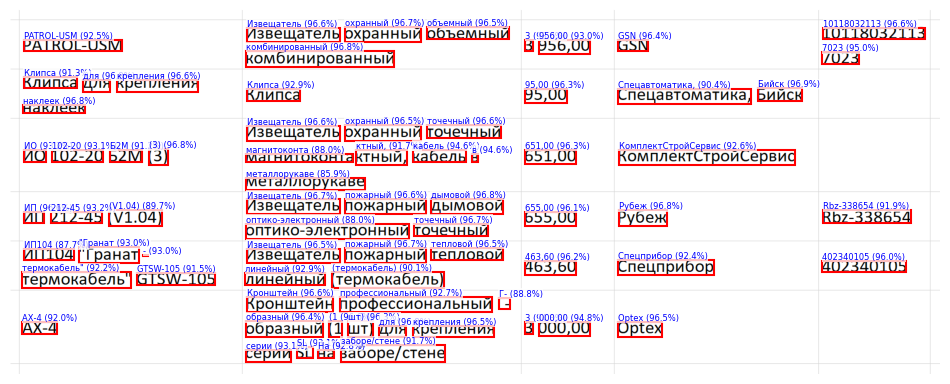

Распознанная таблица сохранена в ./results_3/table_3_base_160.xlsx
Затраченное время: 1.006 секунд
Всего ошибок: 4
Точность распознавания: 0.992


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,10118032113 7023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконта ктный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL Ha заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_130.png


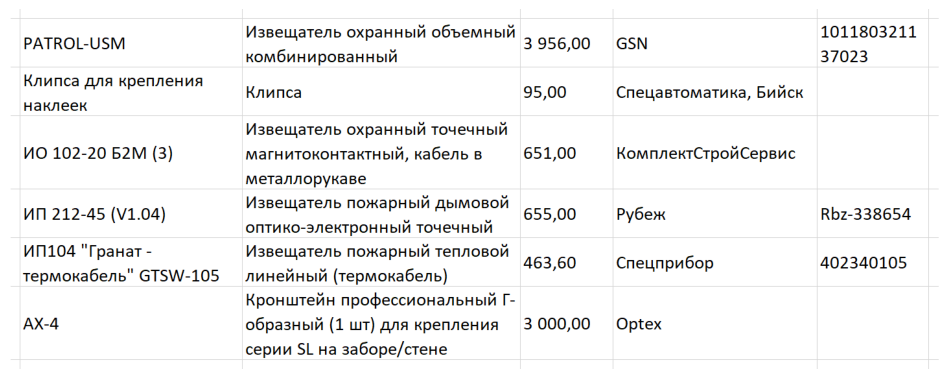

Изображение с обнаруженной таблицей (время: 0.089 секунд):


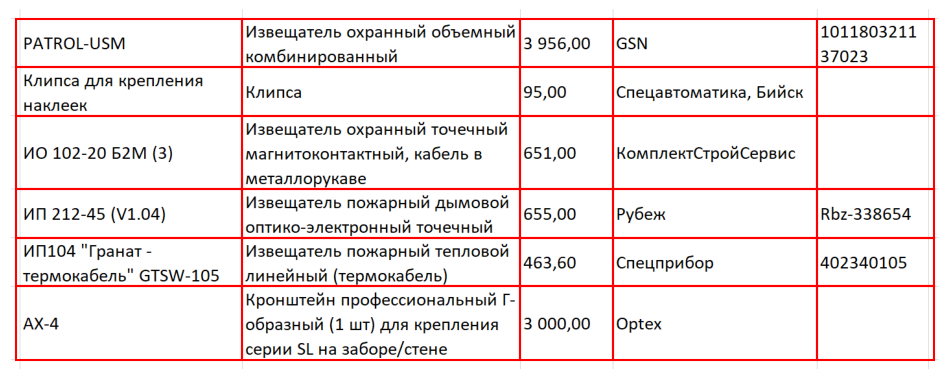

Изображение с найденными ограничивающими рамками:


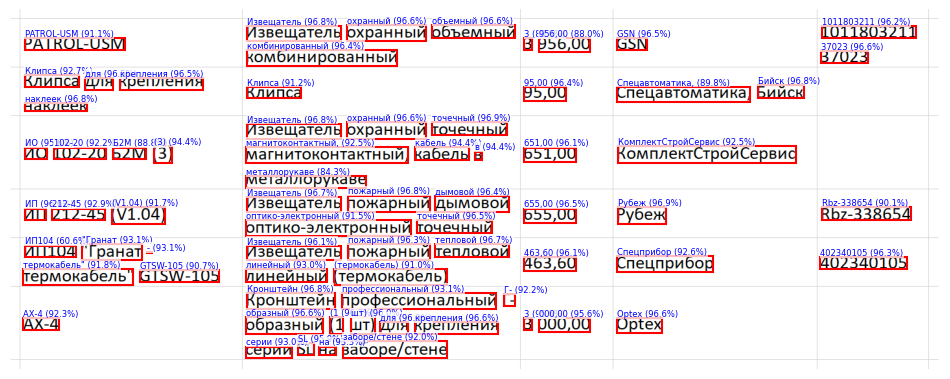

Распознанная таблица сохранена в ./results_3/table_3_base_130.xlsx
Затраченное время: 0.960 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,1011803211 37023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_100.png


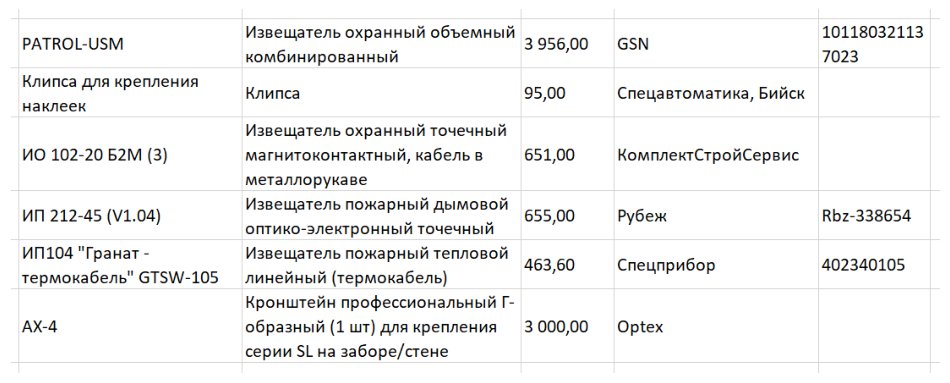

Изображение с обнаруженной таблицей (время: 0.058 секунд):


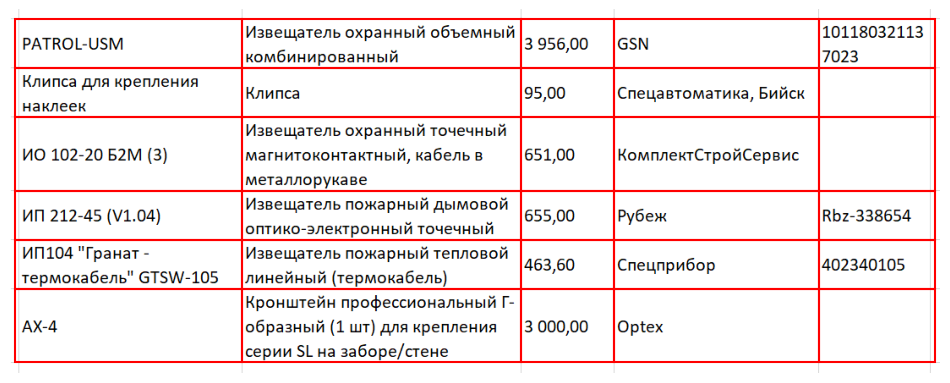

Изображение с найденными ограничивающими рамками:


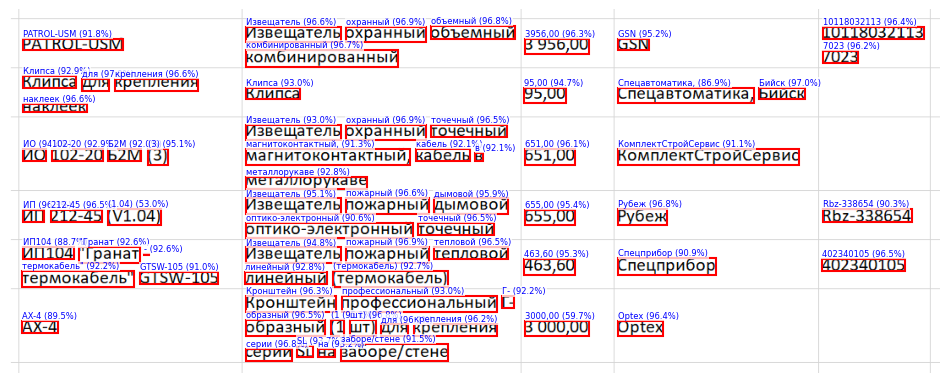

Распознанная таблица сохранена в ./results_3/table_3_base_100.xlsx
Затраченное время: 1.087 секунд
Всего ошибок: 1
Точность распознавания: 0.998


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00",GSN,10118032113 7023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,ИП 212-45 (1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
5,AX-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL на заборе/стене,"3000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_070.png


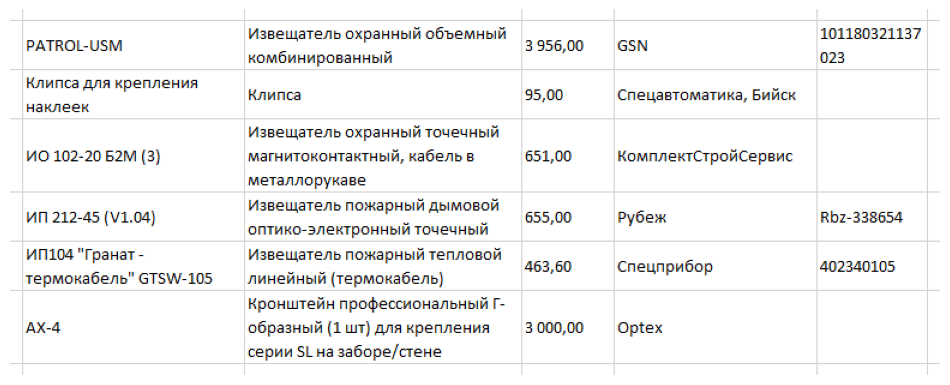

Изображение с обнаруженной таблицей (время: 0.025 секунд):


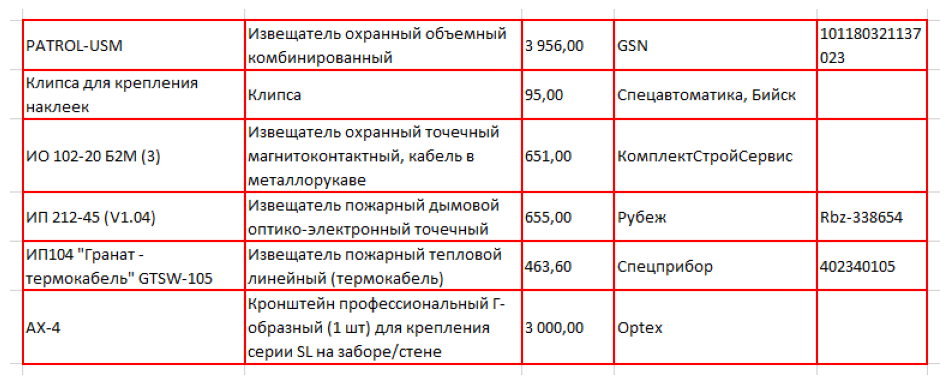

Изображение с найденными ограничивающими рамками:


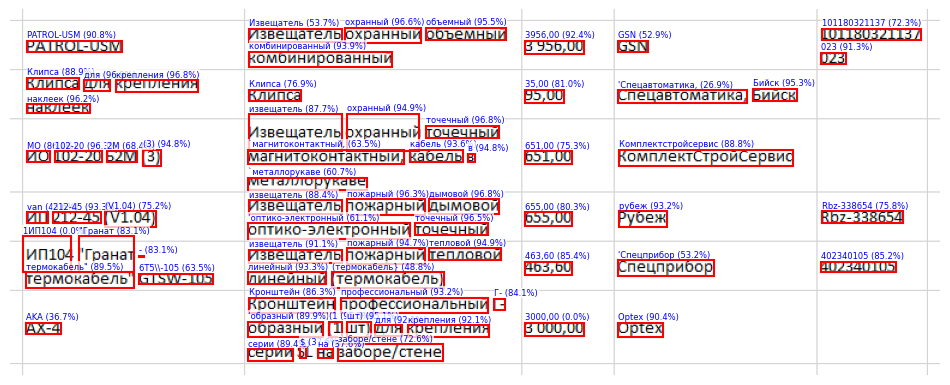

Распознанная таблица сохранена в ./results_3/table_3_base_070.xlsx
Затраченное время: 0.916 секунд
Всего ошибок: 32
Точность распознавания: 0.938


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00",GSN,101180321137 023
1,Клипса для крепления наклеек,Клипса,"35,00","'Спецавтоматика, Бийск",
2,MO 102-20 2M (3),"извещатель охранный точечный `магнитоконтактный, кабель в `металлорукаве","651,00",Комплектстройсервис,
3,van 212-45 (V1.04),извещатель пожарный дымовой ‘оптико-электронный точечный,"655,00",рубеж,Rbz-338654
4,"1ИП104 ""Гранат - термокабель"" 6Т5\\-105",извещатель пожарный тепловой линейный (термокабель},"463,60",'Спецприбор,402340105
5,AKA,Кронштейн профессиональный Г- ‘образный (1 шт) для крепления серии $ на заборе/стене,"3000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_160.png


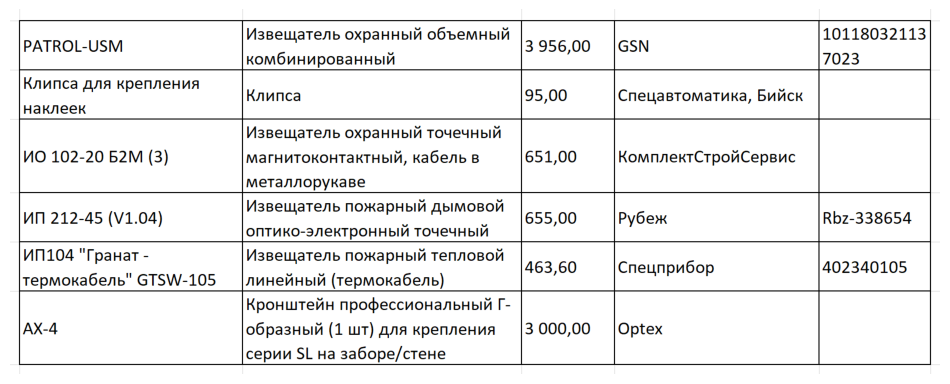

Изображение с обнаруженной таблицей (время: 0.155 секунд):


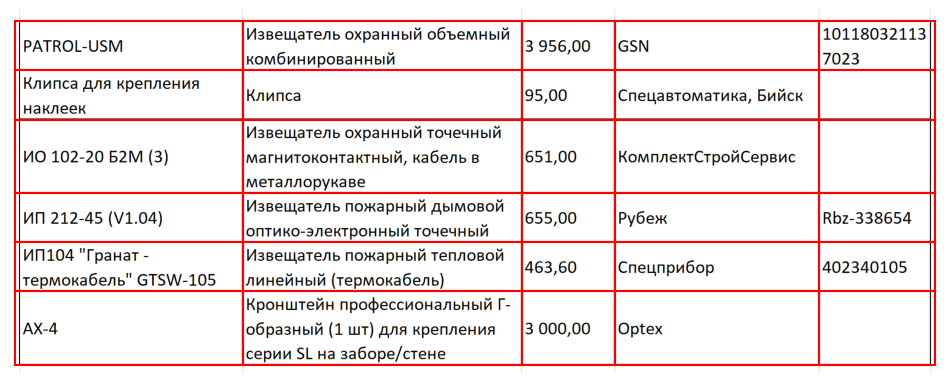

Изображение с найденными ограничивающими рамками:


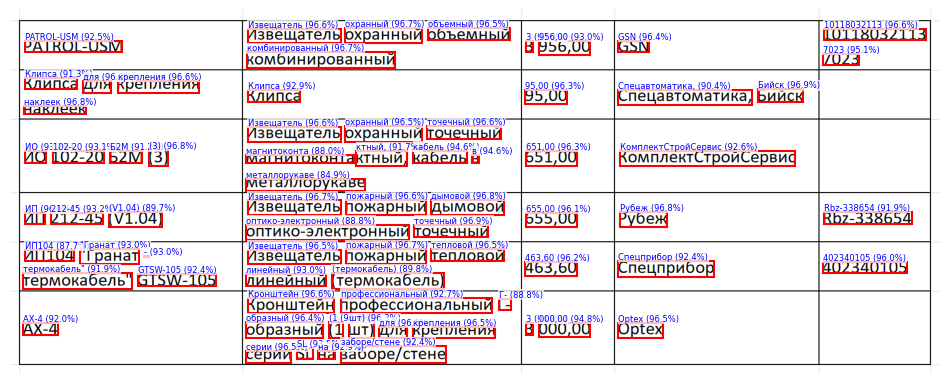

Распознанная таблица сохранена в ./results_3/table_3_base_contrast_160.xlsx
Затраченное время: 1.149 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,10118032113 7023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконта ктный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_130.png


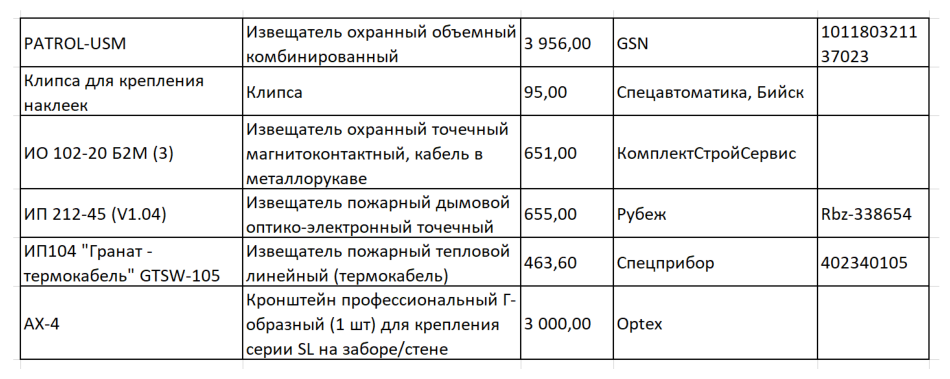

Изображение с обнаруженной таблицей (время: 0.090 секунд):


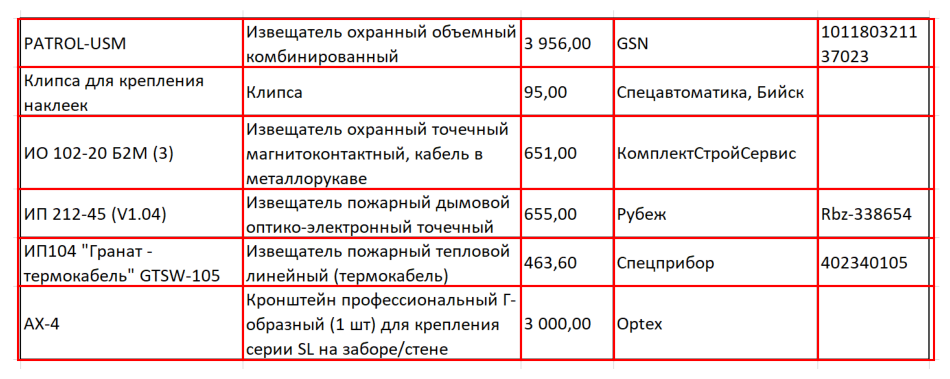

Изображение с найденными ограничивающими рамками:


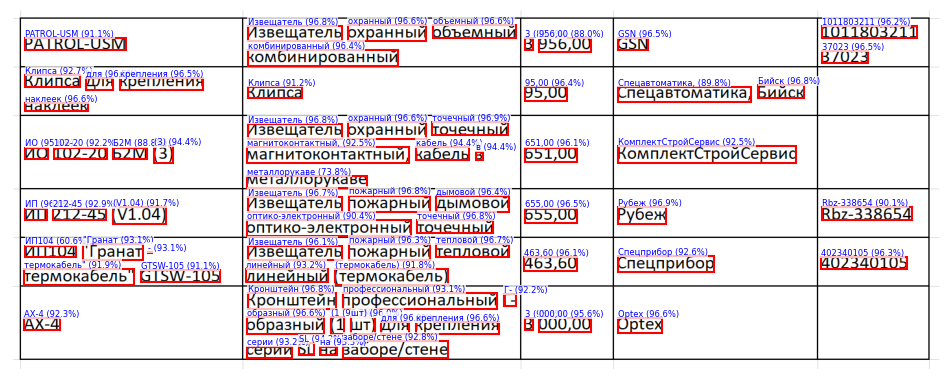

Распознанная таблица сохранена в ./results_3/table_3_base_contrast_130.xlsx
Затраченное время: 1.113 секунд
Всего ошибок: 2
Точность распознавания: 0.996


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,1011803211 37023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_100.png


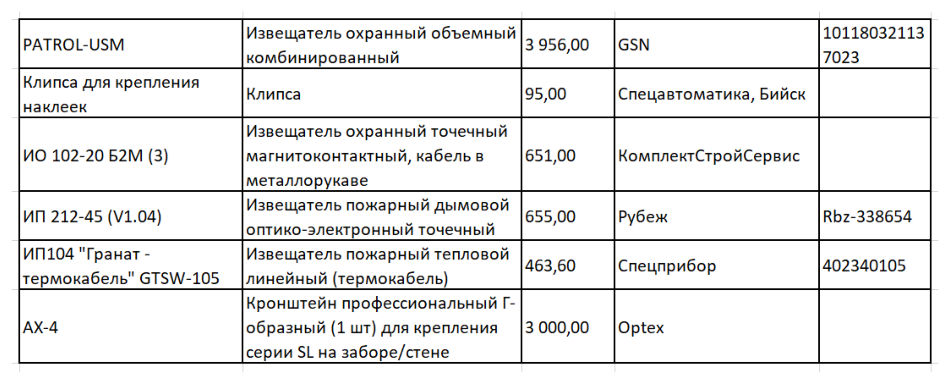

Изображение с обнаруженной таблицей (время: 0.056 секунд):


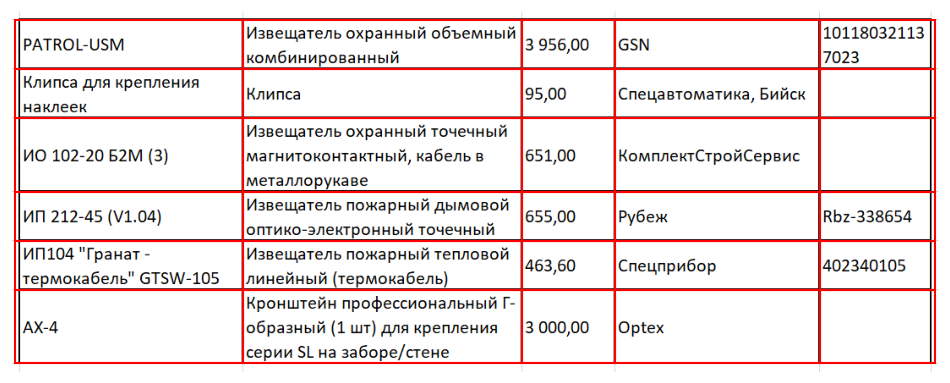

Изображение с найденными ограничивающими рамками:


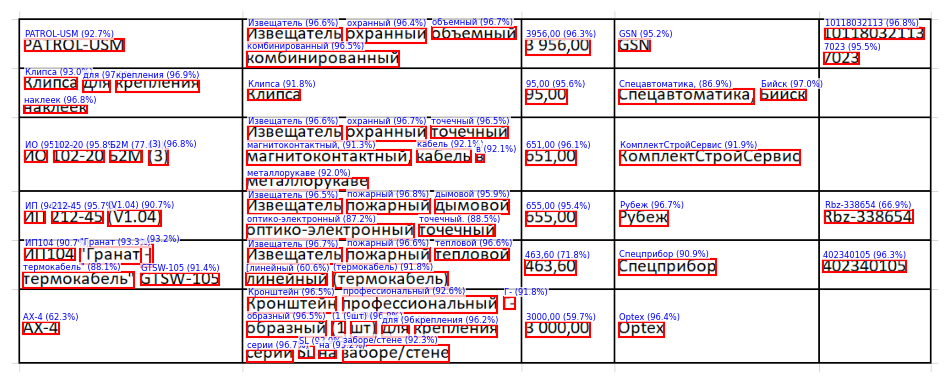

Распознанная таблица сохранена в ./results_3/table_3_base_contrast_100.xlsx
Затраченное время: 0.956 секунд
Всего ошибок: 4
Точность распознавания: 0.992


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00",GSN,10118032113 7023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный.,"655,00",Рубеж,Rbz-338654
4,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой [линейный (термокабель),"463,60",Спецприбор,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL на заборе/стене,"3000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_base_contrast_070.png


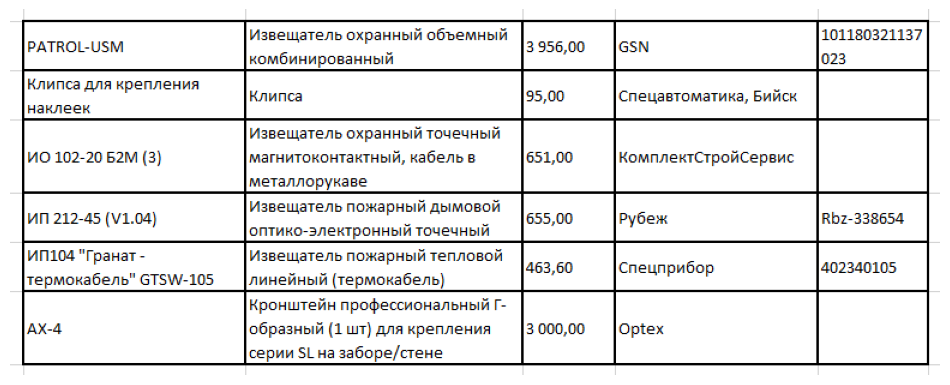

Изображение с обнаруженной таблицей (время: 0.039 секунд):


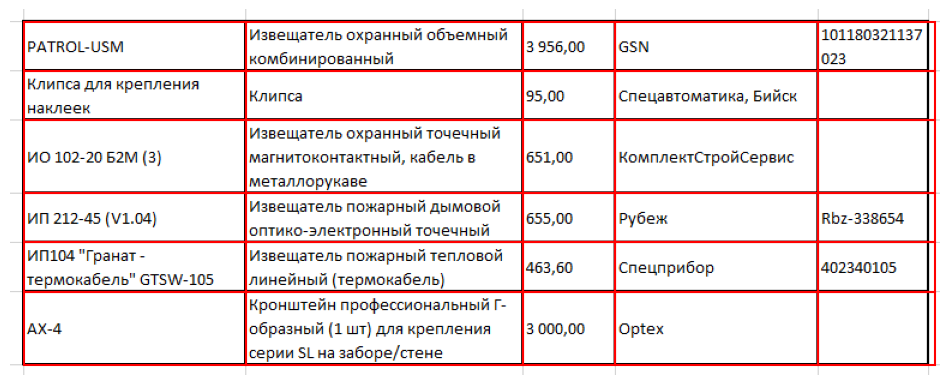

Изображение с найденными ограничивающими рамками:


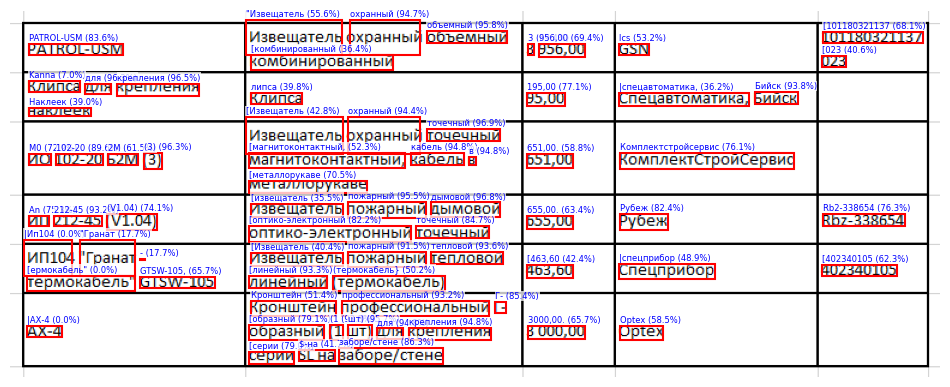

Распознанная таблица сохранена в ./results_3/table_3_base_contrast_070.xlsx
Затраченное время: 0.876 секунд
Всего ошибок: 54
Точность распознавания: 0.895


,0,1,2,3,4
0,PATROL-USM,"""Извещатель охранный объемный [комбинированный","3 956,00",lcs,[101180321137 [023
1,Kanna для крепления Наклеек,липса,"195,00","|спецавтоматика, Бийск",
2,M0 102-20 2M (3),"[Извещатель охранный точечный [магнитоконтактный, кабель в [металлорукаве","651,00.",Комплектстройсервис,
3,An 212-45 (V1.04),[извещатель пожарный дымовой [оптико-электронный точечный,"655,00.",Рубеж,Rb2-338654
4,"|Ип104 ""Гранат - [ермокабель"" GTSW-105,",[Извещатель пожарный тепловой [линейный (термокабель},"[463,60",|спецприбор,[402340105
5,|АХ-4,Кронштейн профессиональный Г- [образный (1 шт) для крепления [серии $-на заборе/стене,"3000,00.",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_160.png


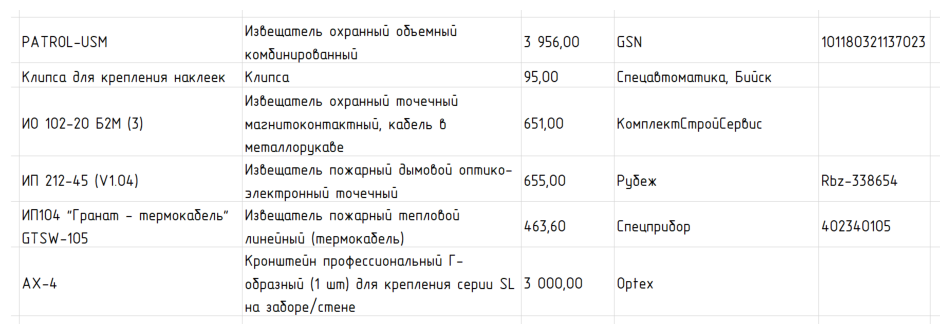

Изображение с обнаруженной таблицей (время: 0.103 секунд):


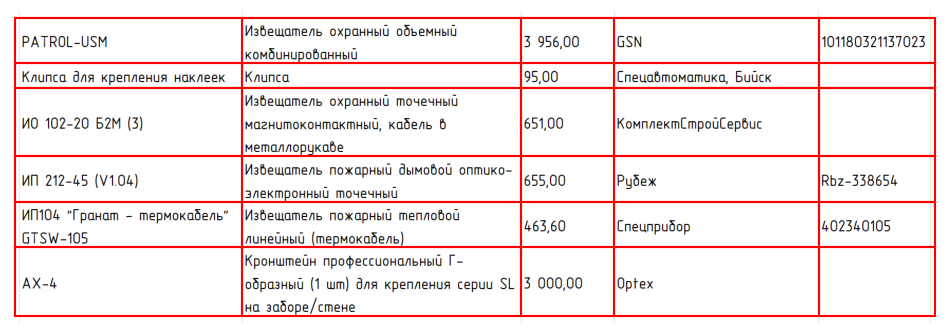

Изображение с найденными ограничивающими рамками:


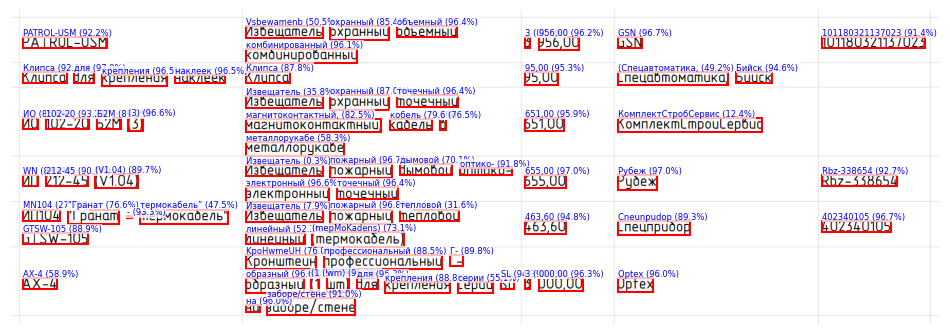

Распознанная таблица сохранена в ./results_3/table_3_gost_160.xlsx
Затраченное время: 1.175 секунд
Всего ошибок: 54
Точность распознавания: 0.895


,0,1,2,3,4
0,PATROL-USM,Vsbewamenb охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","(Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кобель 6 металлорукабе","651,00",КомплектСтробСервис,
3,WN 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
4,"MN104 ""Гранат - термокабель” GTSW-105",Извещатель пожарный тепловой линейный (mepMoKadens),"463,60",Cneunpudop,402340105
5,АХ-4,KpoHwmeUH профессиональный Г- образный (1 wm) для крепления серии SL на заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_130.png


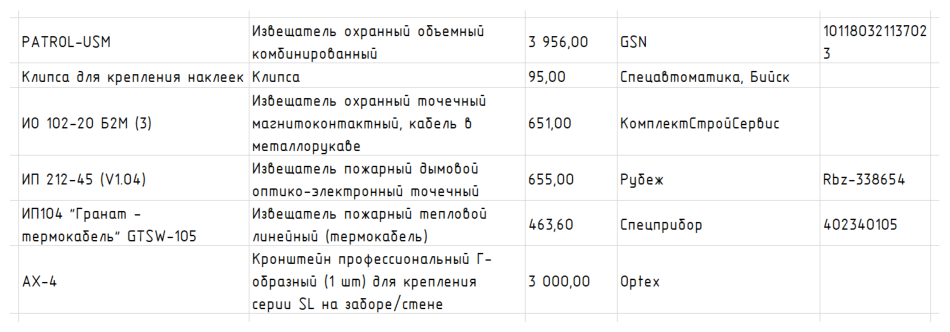

Изображение с обнаруженной таблицей (время: 0.080 секунд):


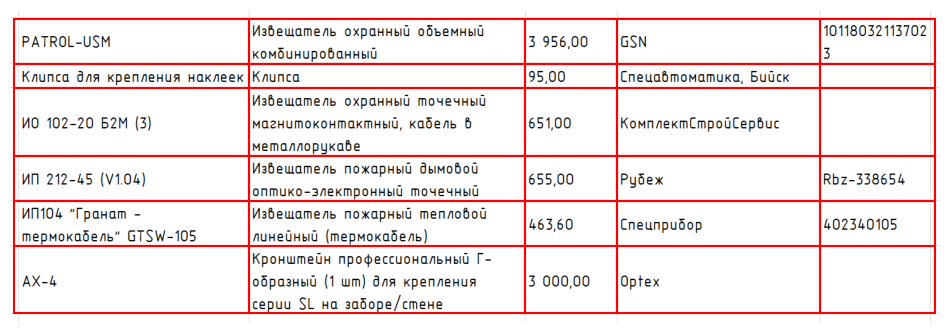

Изображение с найденными ограничивающими рамками:


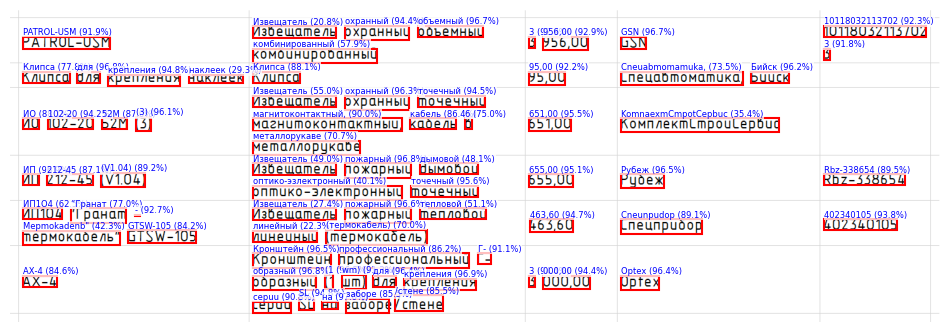

Распознанная таблица сохранена в ./results_3/table_3_gost_130.xlsx
Затраченное время: 1.185 секунд
Всего ошибок: 69
Точность распознавания: 0.866


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,10118032113702 3
1,Клипса для крепления наклеек,Клипса,"95,00","Cneuabmomamuka, Бийск",
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукаве","651,00",KomnaexmCmpotCepbuc,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-эзлектронный точечный,"655,00",Рубеж,Rbz-338654
4,"ИП1О4 “Гранат - Mepmokadenb"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Cneunpudop,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 wm) для крепления cepuu SL на заборе /стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_100.png


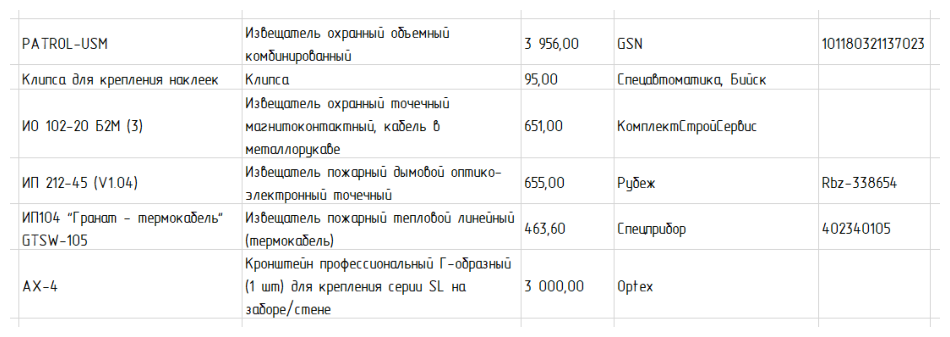

Изображение с обнаруженной таблицей (время: 0.054 секунд):


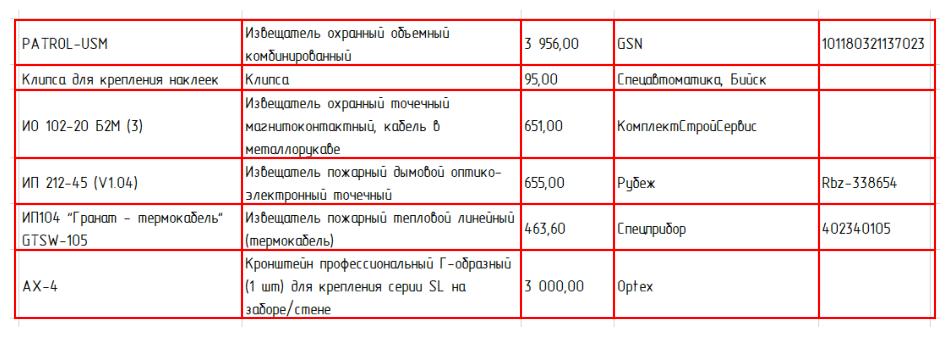

Изображение с найденными ограничивающими рамками:


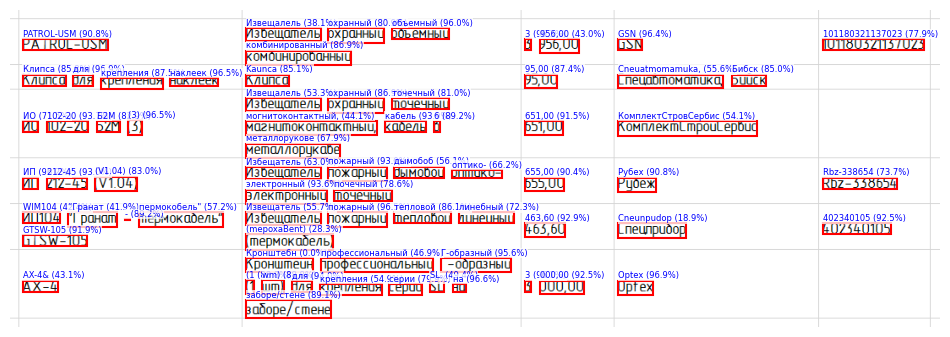

Распознанная таблица сохранена в ./results_3/table_3_gost_100.xlsx
Затраченное время: 0.909 секунд
Всего ошибок: 66
Точность распознавания: 0.872


,0,1,2,3,4
0,PATROL-USM,Извещалель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","Cneuatmomamuka, Бибск",
2,ИО 102-20 Б2М (3),"Извещалель охранный точечный могнитоконтактный, кабель 6 металлорукове","651,00",КомплектСтровСербис,
3,ИП 212-45 (V1.04),Избещатель пожарный дымобоб оптико- электронный почечный,"655,00",Рубех,Rbz-338654
4,"WIM104 “Гранат - пермокобель"" GTSW-105",Извещатель пожарный тепловой линебный (mepoxaBent),"463,60",Cneunpudop,402340105
5,AX-4&,Кронштебн профессиональный Г-образный (1 wm) для крепления серии SL. на заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_070.png


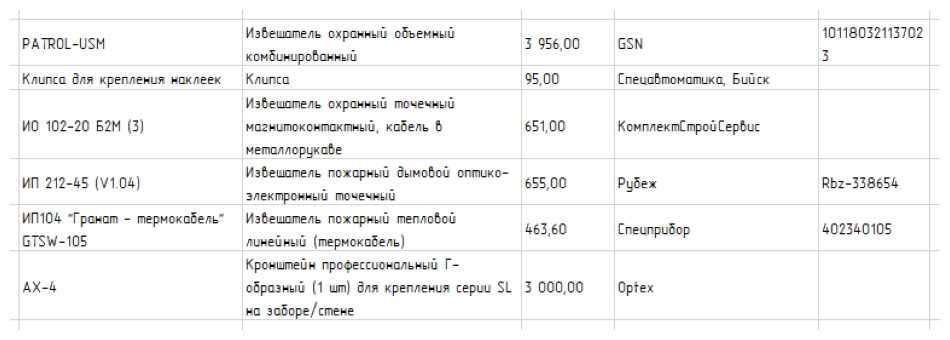

Изображение с обнаруженной таблицей (время: 0.019 секунд):


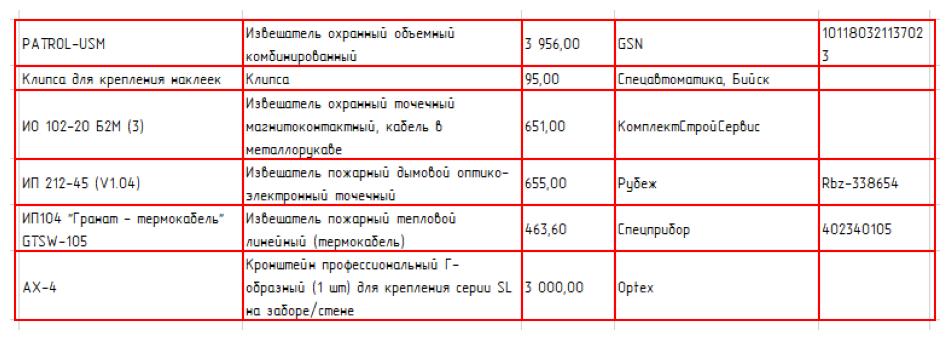

Изображение с найденными ограничивающими рамками:


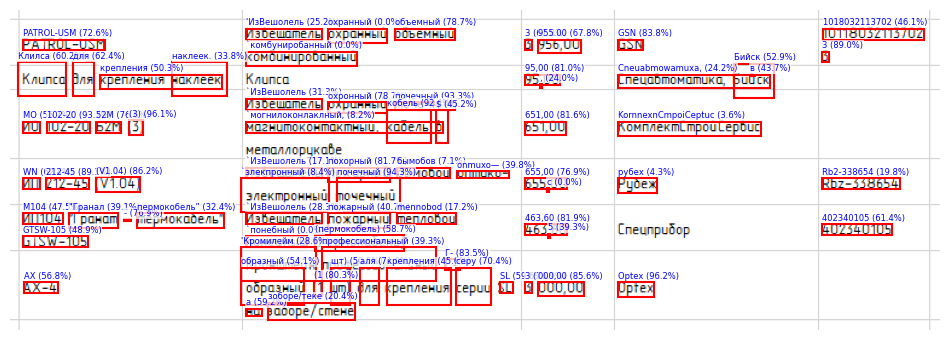

Распознанная таблица сохранена в ./results_3/table_3_gost_070.xlsx
Затраченное время: 0.768 секунд
Всего ошибок: 165
Точность распознавания: 0.680


,0,1,2,3,4
0,PATROL-USM,'ИзВешолель охранный объемный `комбуниробанный,3 955.00,GSN,1018032113702 3
1,Клилса для крепления наклеек.,,"95,00 ,","в Cneuabmowamuxa, Бийск",
2,MO 102-20 52M (3),"`ИзВешолель охронный почечный `могнилоконлаклный, кобель $","651,00",KornnexnCmpoiCeptuc,
3,WN 212-45 (V1.04),`ИзВешолель похорный бымобов onmuxo— `злекпронный почечный,"655,00 с",рубех,Rb2-338654
4,"M104 ""Гранал - пермокобель” GTSW-105",`ИзВешолель пожарный mennobod `понебный (пермокобель),"463,60 5",,402340105
5,АХ,'Кромилейм профессиональный Г- образный (1 шт) аля крепления серу SL a зоборе/теке,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_160.png


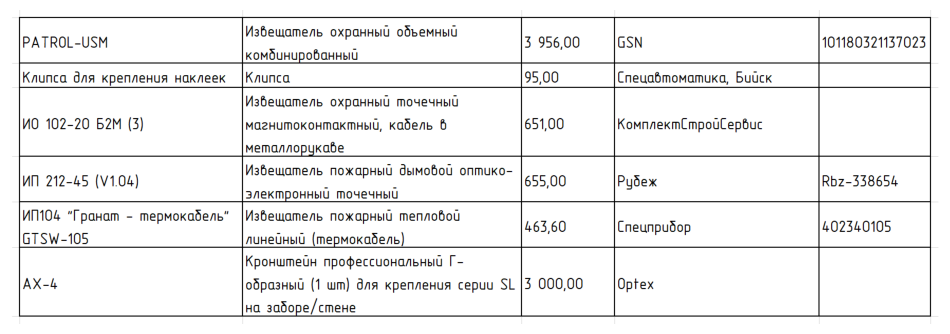

Изображение с обнаруженной таблицей (время: 0.106 секунд):


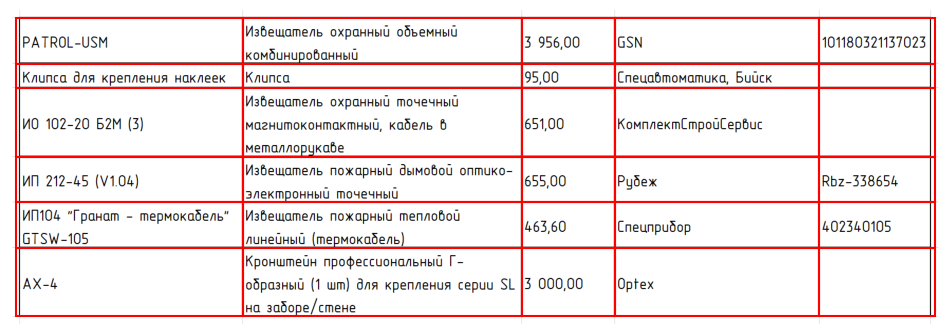

Изображение с найденными ограничивающими рамками:


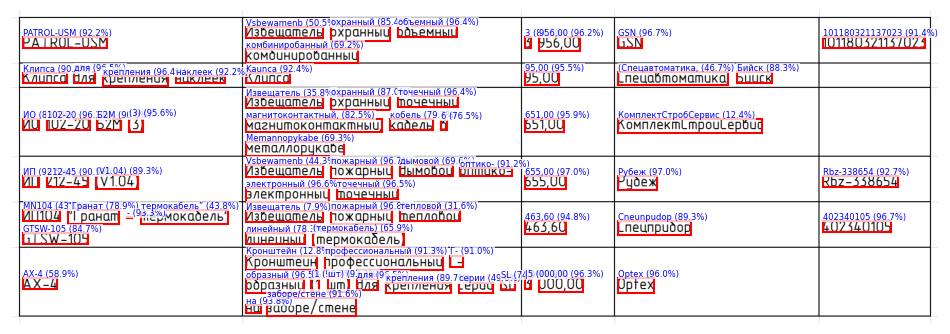

Распознанная таблица сохранена в ./results_3/table_3_gost_contrast_160.xlsx
Затраченное время: 1.014 секунд
Всего ошибок: 61
Точность распознавания: 0.882


,0,1,2,3,4
0,PATROL-USM,Vsbewamenb охранный объемный комбиниробанный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","(Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кобель 6 Memannopykabe","651,00",КомплектСтробСервис,
3,ИП 212-45 (V1.04),Vsbewamenb пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
4,"MN104 ""Гранат - термокабель” GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Cneunpudop,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 шт) для крепления серии SL на заборе/стене,"|5 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_130.png


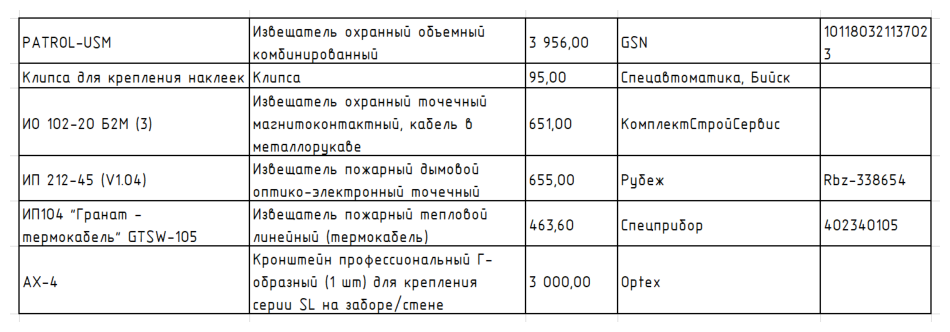

Изображение с обнаруженной таблицей (время: 0.081 секунд):


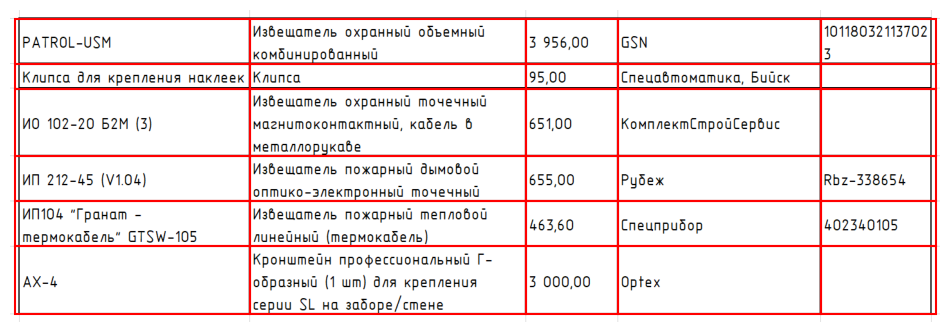

Изображение с найденными ограничивающими рамками:


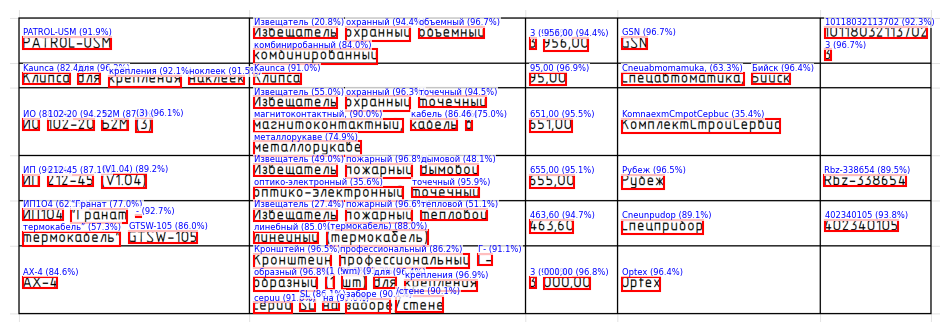

Распознанная таблица сохранена в ./results_3/table_3_gost_contrast_130.xlsx
Затраченное время: 1.167 секунд
Всего ошибок: 73
Точность распознавания: 0.859


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбиниробанный,"3 956,00",GSN,10118032113702 3
1,Kaunca для крепления ноклеек,Kaunca,"95,00","Cneuabmomamuka, Бийск",
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукаве","651,00",KomnaexmCmpotCepbuc,
3,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-электронный точечный,"655,00",Рубеж,Rbz-338654
4,ИП1О4 “Гранат - термокабель” GTSW-105,Извещатель пожарный тепловой линебный (термокабель),"463,60",Cneunpudop,402340105
5,АХ-4,Кронштейн профессиональный Г- образный (1 wm) для крепления cepuu SL на заборе /стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_100.png


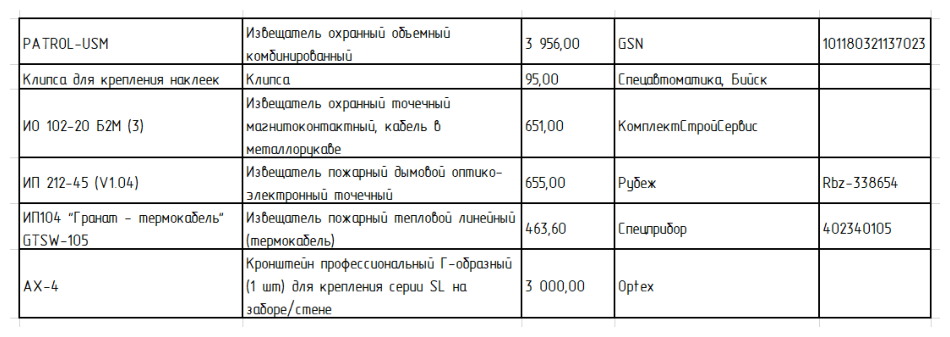

Изображение с обнаруженной таблицей (время: 0.057 секунд):


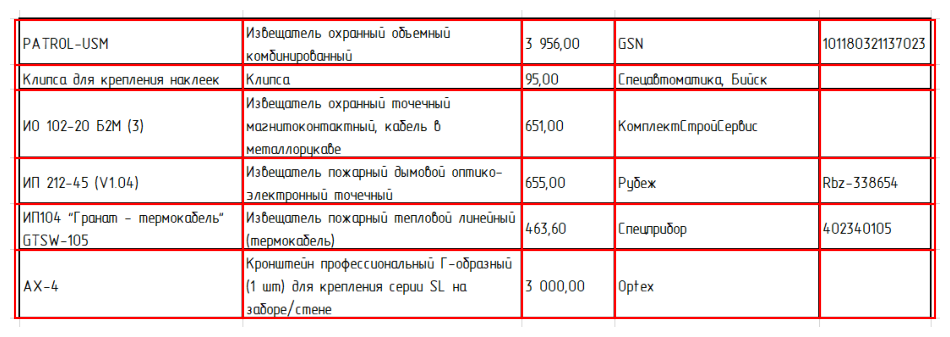

Изображение с найденными ограничивающими рамками:


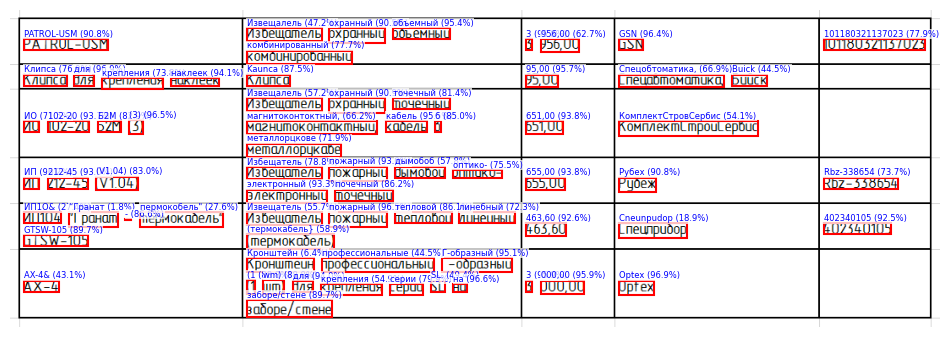

Распознанная таблица сохранена в ./results_3/table_3_gost_contrast_100.xlsx
Затраченное время: 0.814 секунд
Всего ошибок: 48
Точность распознавания: 0.907


,0,1,2,3,4
0,PATROL-USM,Извещалель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","Спецобтоматика, Buick",
2,ИО 102-20 Б2М (3),"Извещалель охранный точечный магнитоконтоктный, кабель 6 металлорцкове","651,00",КомплектСтровСербис,
3,ИП 212-45 (V1.04),Избещатель пожарный дымобоб оптико- электронный почечный,"655,00",Рубех,Rbz-338654
4,"ИП1О& “Гранат - пермокобель"" GTSW-105",Извещатель пожарный тепловой линебный (термокабель},"463,60",Cneunpudop,402340105
5,AX-4&,Кронштейн профессиональные Г-образный (1 wm) для крепления серии SL. на заборе/стене,"3 000,00",Optex,



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_3_gost_contrast_070.png


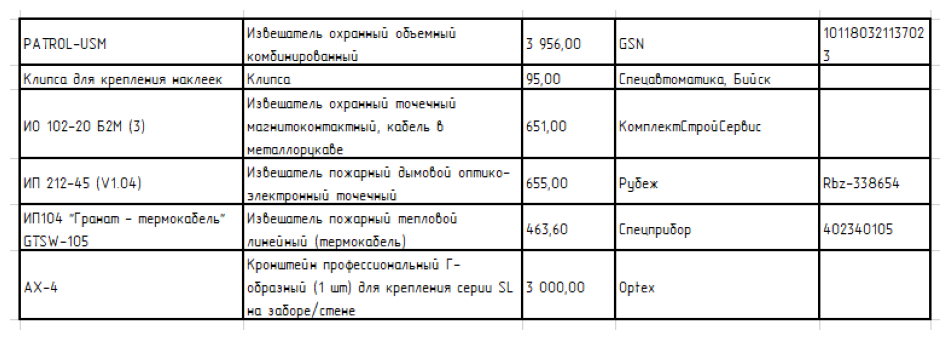

Изображение с обнаруженной таблицей (время: 0.035 секунд):


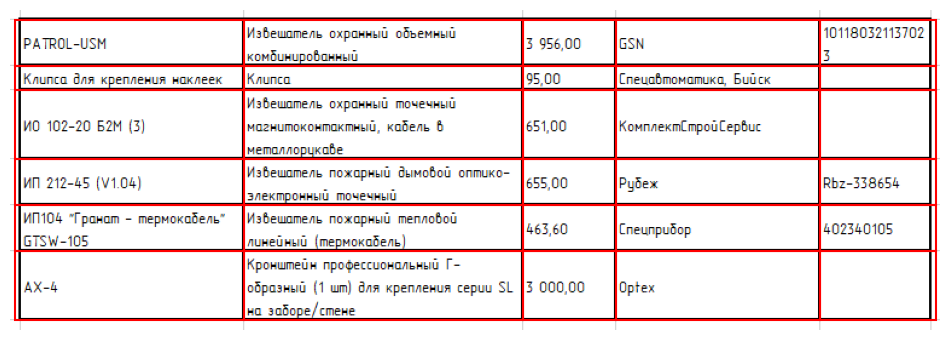

Изображение с найденными ограничивающими рамками:


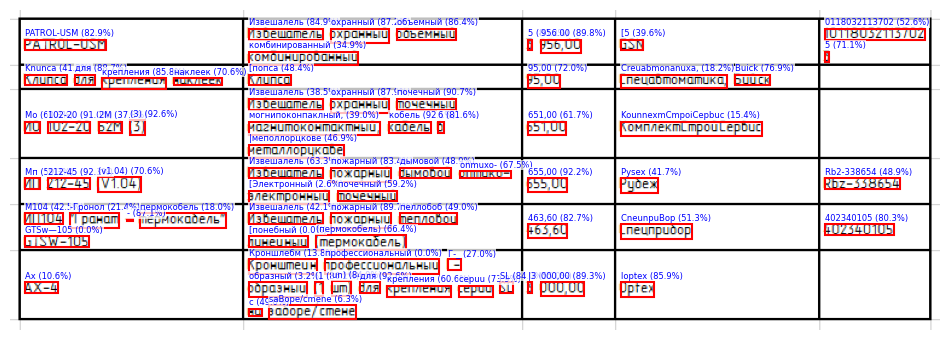

Распознанная таблица сохранена в ./results_3/table_3_gost_contrast_070.xlsx
Затраченное время: 0.803 секунд
Всего ошибок: 158
Точность распознавания: 0.694


,0,1,2,3,4
0,PATROL-USM,Извешалель охранный объемный комбинированный,5 956.00,[5,0118032113702 5
1,Knunca для крепления наклеек,[попса,"95,00","Creuabmonanuxa, Buick",
2,Мо 102-20 2M (3),"Извешалель охранный почечный могнипоконпаклный, кобель 6 |меполлорцкове","651,00",KounnexmCmpoiCepbuc,
3,Мп 212-45 (v1.04),Извешалель пожарный дымовой onmuxo- [Электронный почечный,"655,00",Pysex,Rb2-338654
4,M104 -Гронол - пермокобель GTSw—105,Извешалель пожарный пеллобоб [понебный (пермокобель),"463,60",CneunpuBop,402340105
5,Ах,Кроншлебм профессиональный Г-_ образный (1 un) для крепления cepuu SL с saBope/cmene,"|3 000,00",loptex,



----------------------------------------------------------------------------------------------------

Суммарное время распознавания 48 таблиц: 0:00:39


In [ ]:
test_on_grouped_images(
    image_paths[:48], group_size=4, reverse=True, threshold=0.5,
    verbose=1, draw_text=True, save_to_excel=True,
)

Изображение: ./screenshots/table_4_base_130.png


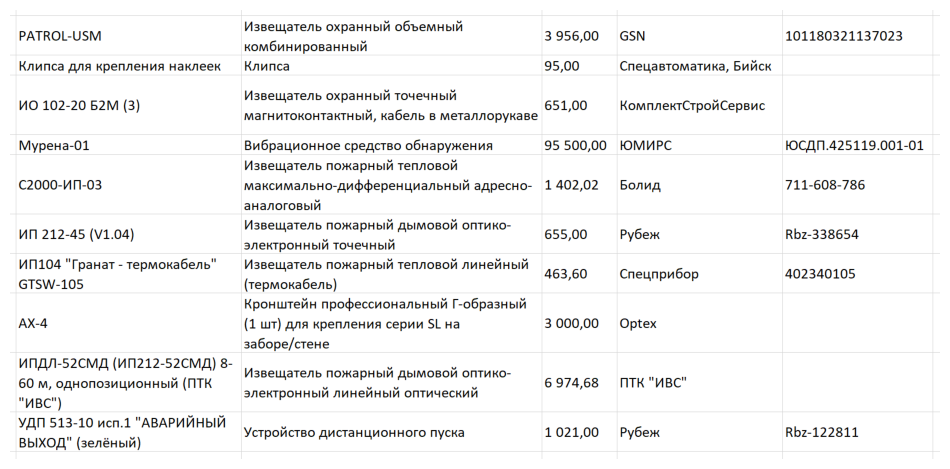

Изображение с обнаруженной таблицей (время: 0.151 секунд):


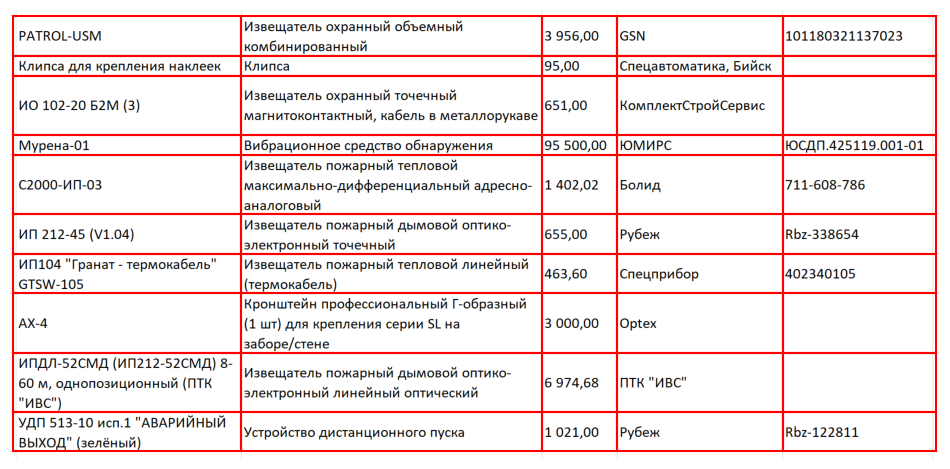

Изображение с найденными ограничивающими рамками:


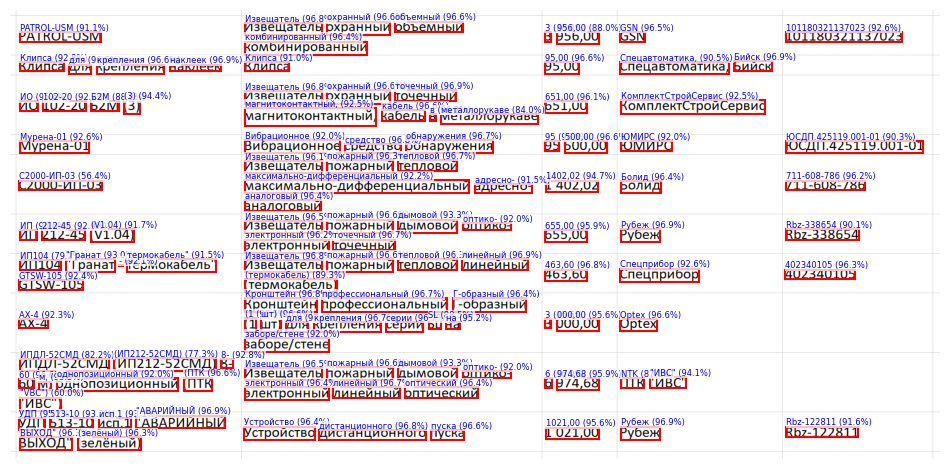

Распознанная таблица сохранена в ./results_3/table_4_base_130.xlsx
Затраченное время: 1.836 секунд
Всего ошибок: 8
Точность распознавания: 0.991


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой максимально-дифференциальный адресно- аналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
7,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8- 60 м, однопозиционный (ПТК ""VBC"")",Извещатель пожарный дымовой оптико- электронный линейный оптический,"6 974,68","NTK ""ИВС""",
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_100.png


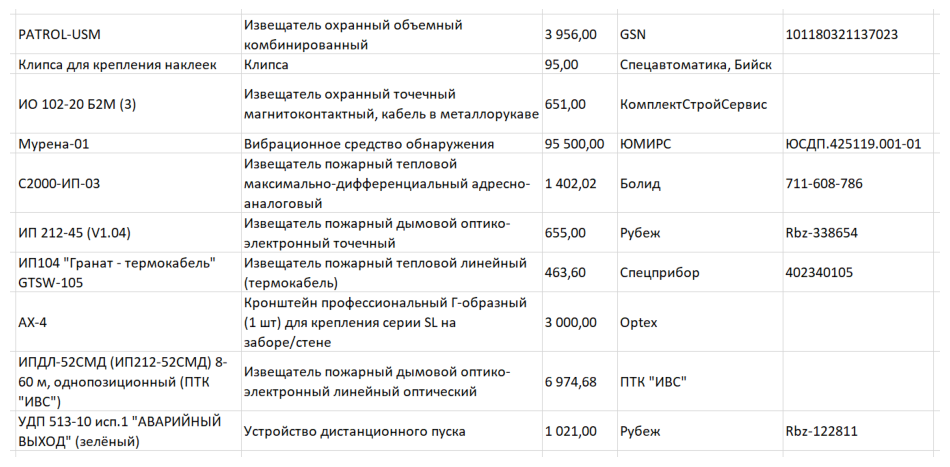

Изображение с обнаруженной таблицей (время: 0.097 секунд):


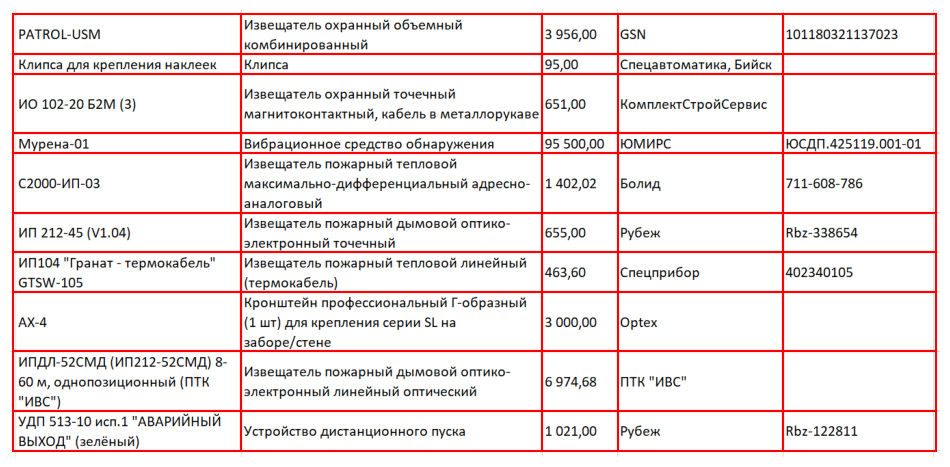

Изображение с найденными ограничивающими рамками:


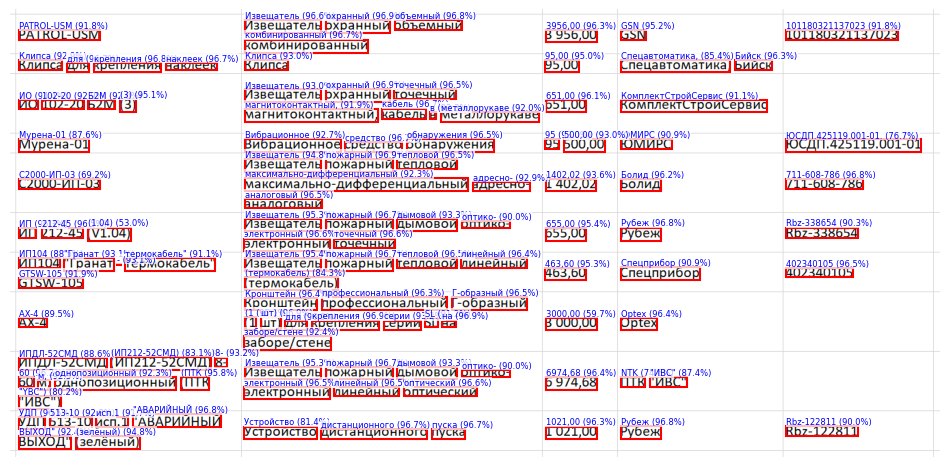

Распознанная таблица сохранена в ./results_3/table_4_base_100.xlsx
Затраченное время: 1.716 секунд
Всего ошибок: 8
Точность распознавания: 0.991


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01.
4,С2000-ИП-03,Извещатель пожарный тепловой максимально-дифференциальный адресно- аналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
7,AX-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8- 60 м, однопозиционный (ПТК ""YBC"")",Извещатель пожарный дымовой оптико- электронный линейный оптический,"6974,68","NTK ""ИВС""",
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_070.png


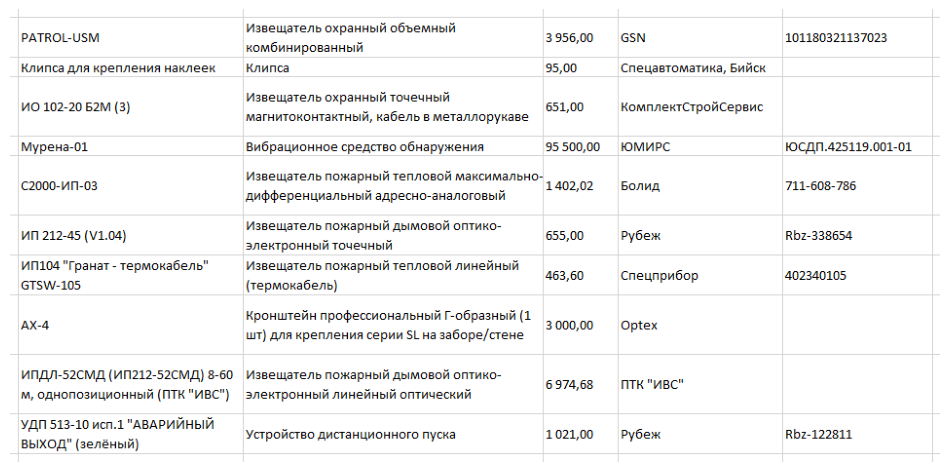

Изображение с обнаруженной таблицей (время: 0.058 секунд):


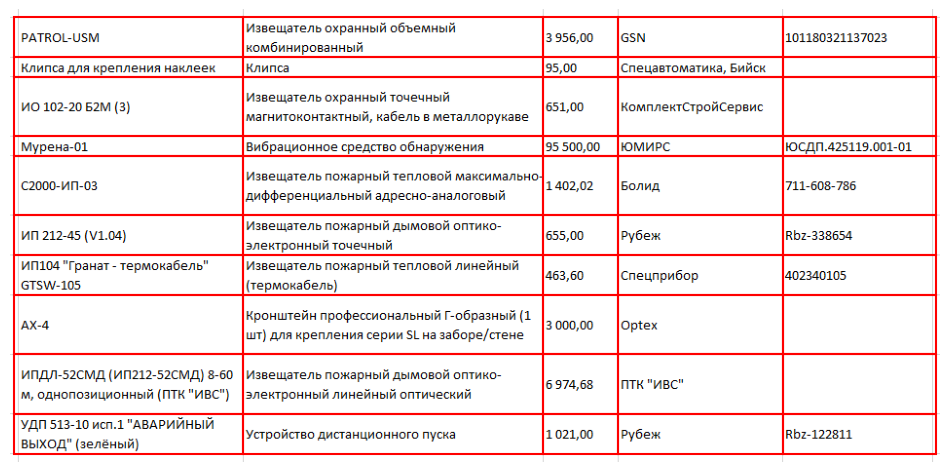

Изображение с найденными ограничивающими рамками:


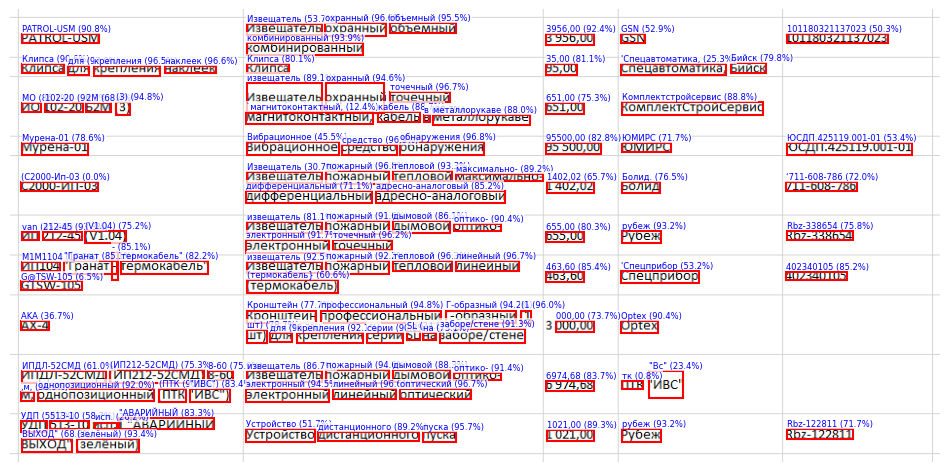

Распознанная таблица сохранена в ./results_3/table_4_base_070.xlsx
Затраченное время: 1.545 секунд
Всего ошибок: 41
Точность распознавания: 0.955


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"35,00","'Спецавтоматика, Бийск",
2,MO 102-20 2M (3),"извещатель охранный точечный `магнитоконтактный, кабель в металлорукаве","651,00",Комплектстройсервис,
3,Мурена-01,Вибрационное средство обнаружения,"95500,00",ЮМИРС,ЮСДП.425119.001-01
4,(С2000-Ип-03,Извещатель пожарный тепловой максимально- дифференциальный адресно-аналоговый,"1402,02",Болид.,‘711-608-786
5,van 212-45 (V1.04),извещатель пожарный дымовой оптико- электронный точечный,"655,00",рубеж,Rbz-338654
6,"M1M1104 ""Гранат - термокабель"" G@TSW-105",извещатель пожарный тепловой линейный (термокабель},"463,60",'Спецприбор,402340105
7,AKA,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 ‚м, однопозиционный (ПТК ""ИВС"")",извещатель пожарный дымовой оптико- электронный линейный оптический,"6974,68","тк ""Bc""",
9,"УДП 513-10 исп. ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_contrast_130.png


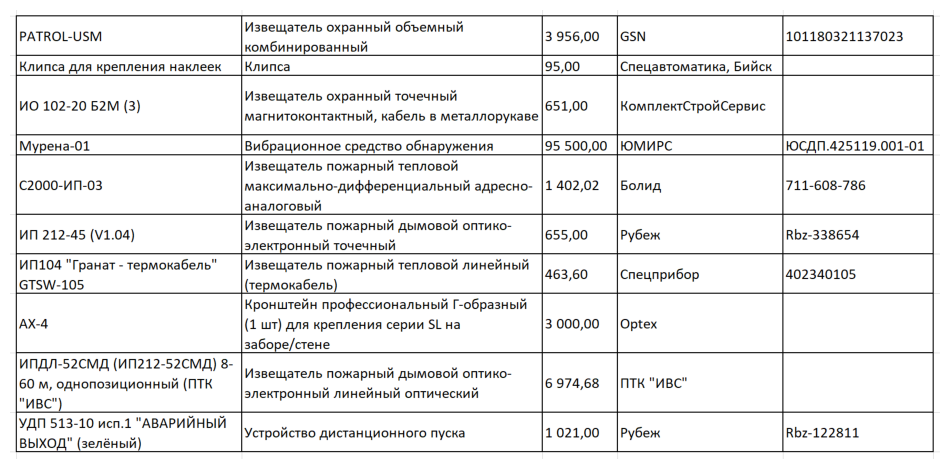

Изображение с обнаруженной таблицей (время: 0.143 секунд):


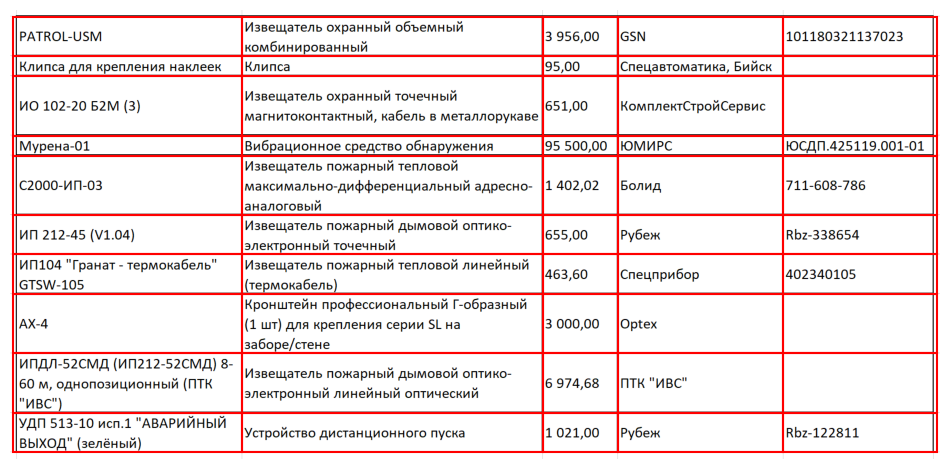

Изображение с найденными ограничивающими рамками:


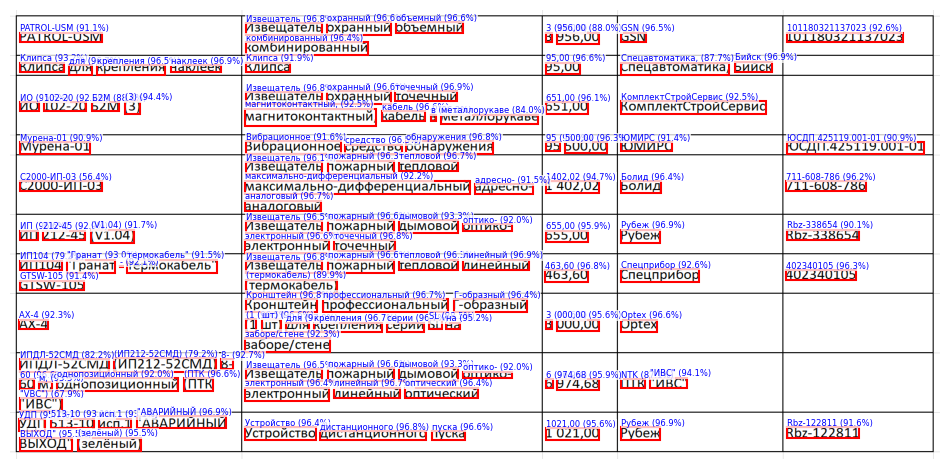

Распознанная таблица сохранена в ./results_3/table_4_base_contrast_130.xlsx
Затраченное время: 1.741 секунд
Всего ошибок: 8
Точность распознавания: 0.991


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой максимально-дифференциальный адресно- аналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
7,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3 000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8- 60 м, однопозиционный (ПТК ""VBC"")",Извещатель пожарный дымовой оптико- электронный линейный оптический,"6 974,68","NTK ""ИВС""",
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_contrast_100.png


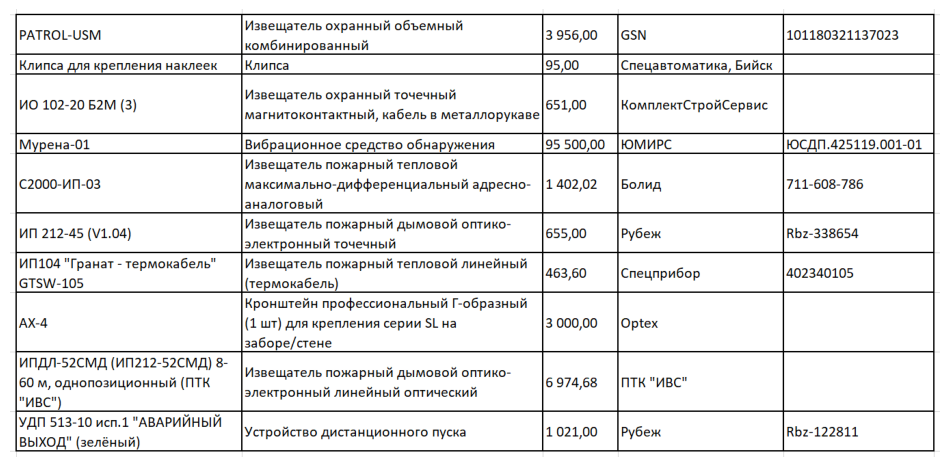

Изображение с обнаруженной таблицей (время: 0.101 секунд):


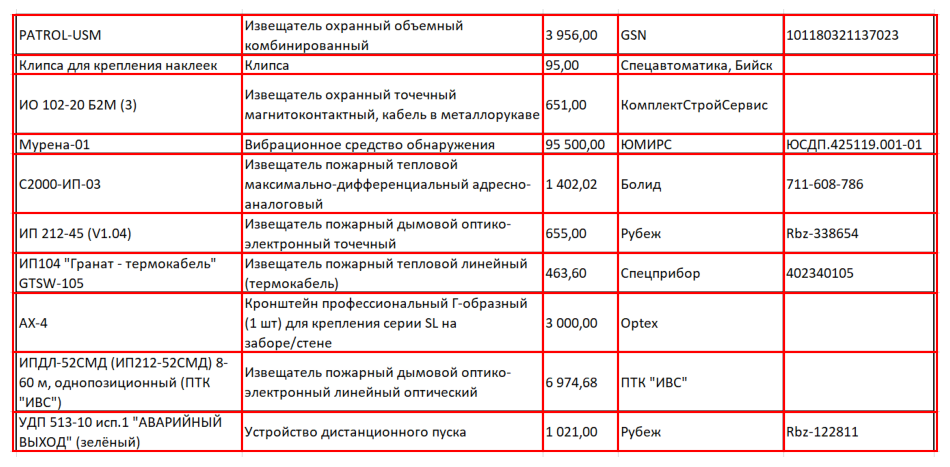

Изображение с найденными ограничивающими рамками:


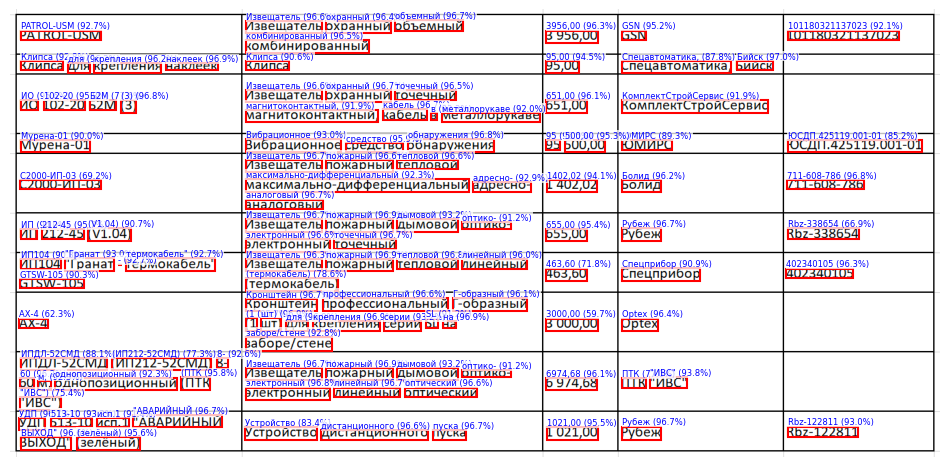

Распознанная таблица сохранена в ./results_3/table_4_base_contrast_100.xlsx
Затраченное время: 1.605 секунд
Всего ошибок: 2
Точность распознавания: 0.998


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Клипса,"95,00","Спецавтоматика, Бийск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00",КомплектСтройСервис,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП.425119.001-01
4,С2000-ИП-03,Извещатель пожарный тепловой максимально-дифференциальный адресно- аналоговый,"1402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП104 ""Гранат - термокабель"" GTSW-105",Извещатель пожарный тепловой линейный (термокабель),"463,60",Спецприбор,402340105
7,АХ-4,Кронштейн профессиональный Г-образный (1 шт) для крепления серии SL на заборе/стене,"3000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8- 60 м, однопозиционный (ПТК ""ИВС"")",Извещатель пожарный дымовой оптико- электронный линейный оптический,"6974,68","ПТК ""ИВС""",
9,"УДП 513-10 исп.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_base_contrast_070.png


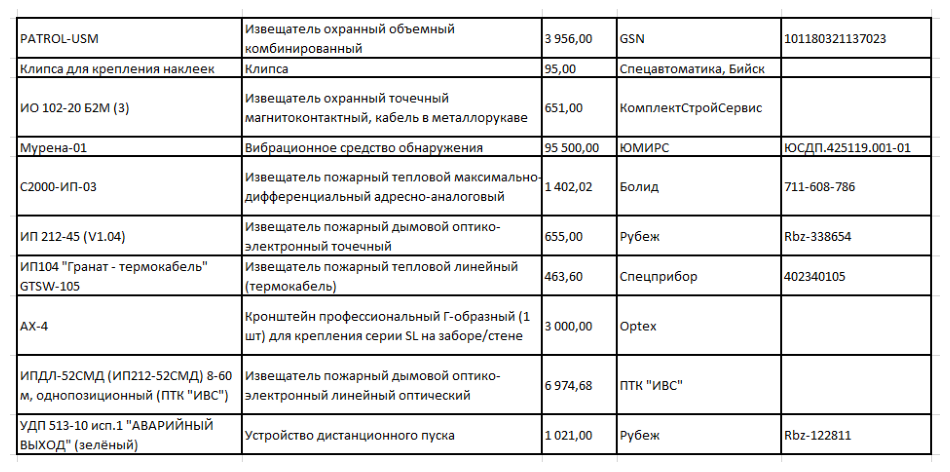

Изображение с обнаруженной таблицей (время: 0.058 секунд):


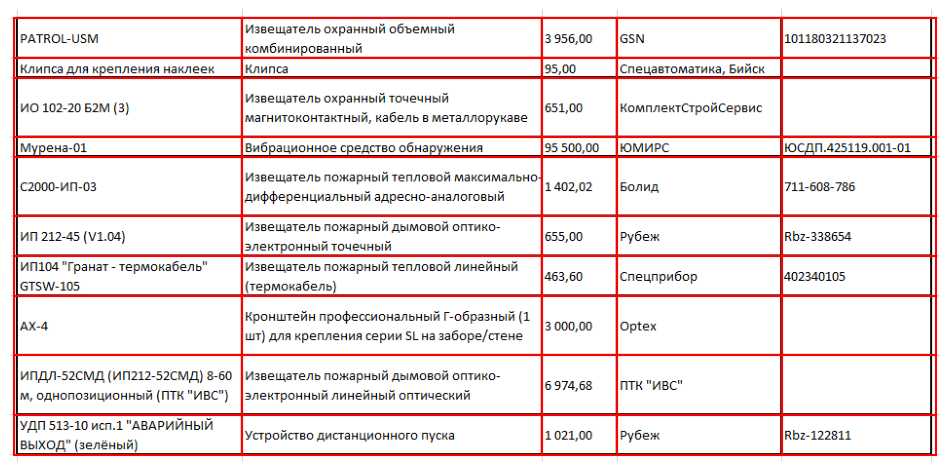

Изображение с найденными ограничивающими рамками:


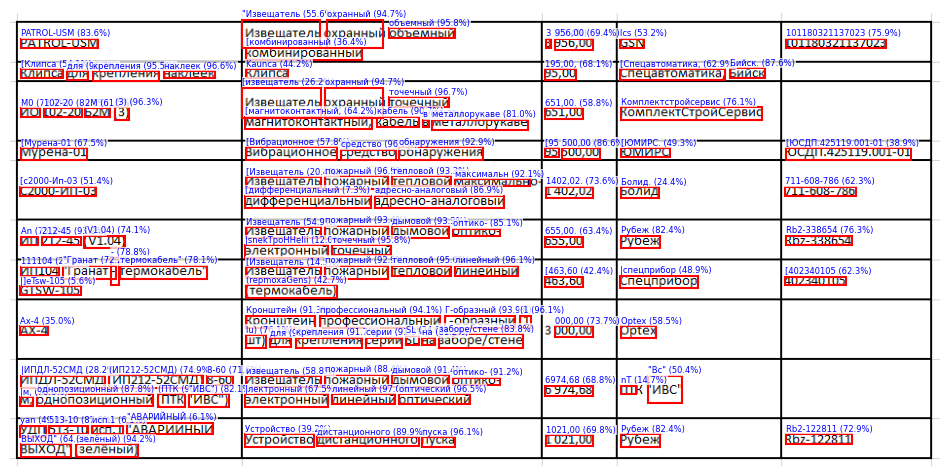

Распознанная таблица сохранена в ./results_3/table_4_base_contrast_070.xlsx
Затраченное время: 1.795 секунд
Всего ошибок: 100
Точность распознавания: 0.890


,0,1,2,3,4
0,PATROL-USM,"""Извещатель охранный объемный [комбинированный","3 956,00",lcs,101180321137023
1,[Клипса для крепления наклеек,Kaunca,"195,00,","[Спецавтоматика, Бийск.",
2,M0 102-20 2M (3),"[извещатель охранный точечный [магнитоконтактный, кабель в металлорукаве","651,00.",Комплектстройсервис,
3,[Мурена-01,[Вибрационное средство обнаружения,"[95 500,00",[ЮМИРС.,[ЮСДП.425119.001-01
4,[с2000-Ип-03,[Извещатель пожарный тепловой максимальн [дифференциальный адресно-аналоговый,"1402,02.",Болид.,711-608-786
5,An 212-45 (V1.04),Извещатель пожарный дымовой оптико- |snekTpoHHeIii точечный,"655,00.",Рубеж,Rb2-338654
6,"111104 ""Гранат - термокабель"" |]eTsw-105",[Извещатель пожарный тепловой линейный (repmoxaGens),"[463,60",|спецприбор,[402340105
7,Ax-4,Кронштейн профессиональный Г-образный (1 lu) для крепления серии SL на заборе/стене,"000,00",Optex,
8,"|ИПДЛ-52СМД (ИП212-52СМД) 8-60 |м, однопозиционный (ПТК ""ИВС"")",извещатель пожарный дымовой оптико- |лектронный линейный оптический,"6974,68","nT ""Bc""",
9,"yan 513-10 исп.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1021,00",Рубеж,Rb2-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_130.png


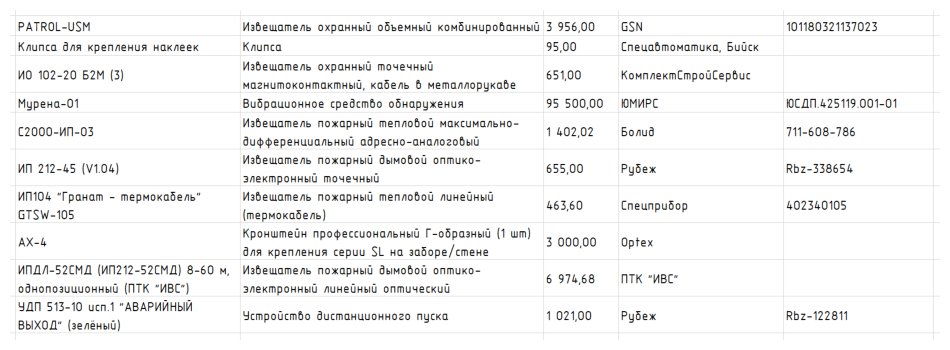

Изображение с обнаруженной таблицей (время: 0.125 секунд):


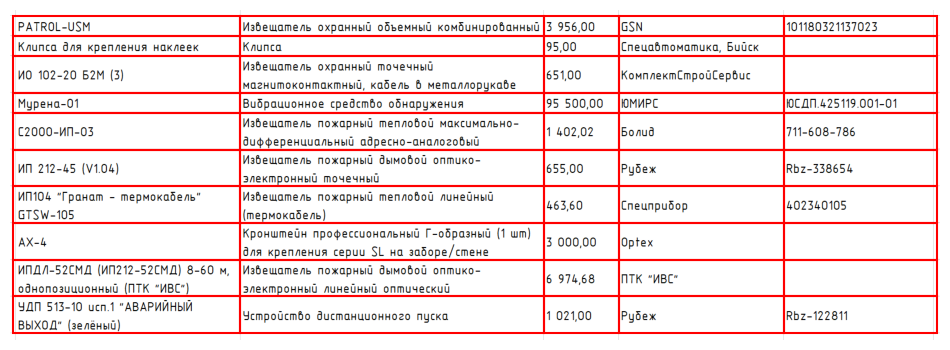

Изображение с найденными ограничивающими рамками:


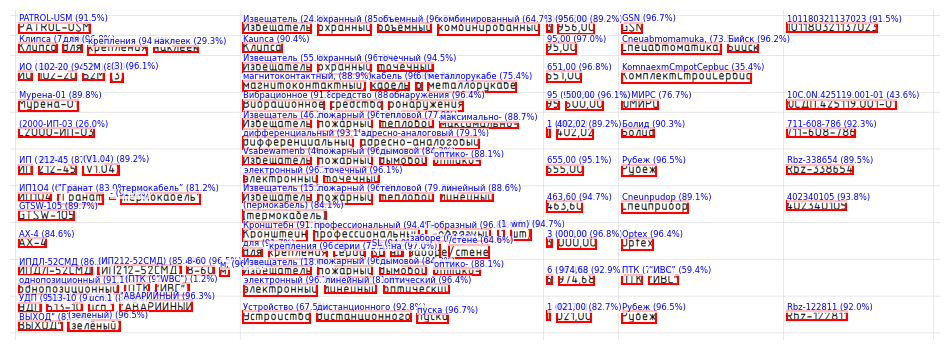

Распознанная таблица сохранена в ./results_3/table_4_gost_130.xlsx
Затраченное время: 2.182 секунд
Всего ошибок: 88
Точность распознавания: 0.904


,0,1,2,3,4
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","Cneuabmomamuka, Бийск",
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00",KomnaexmCmpotCepbuc,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,10C.0N.425119.001-01
4,(2000-ИП-03,Извещатель пожарный тепловой максимально- дифференциальный адресно-аналоговый,"1 402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Vsabewamenb пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП1О4 ""Гранат - термокабель” GTSW-105",Извещатель пожарный тепловой линейный (пермокабель),"463,60",Cneunpudop,402340105
7,АХ-4,Кронштебн профессиональный Г-образный (1 wm) для крепления серии SL на заборе /стене,"3 000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м, однопозиционный (ПТК “WBC"")",Извещатель пожарный дымовой оптико- электронный линейный оптический,"6 974,68",ПТК “ИВС”,
9,"УДП 513-10 ucn.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1 021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_100.png


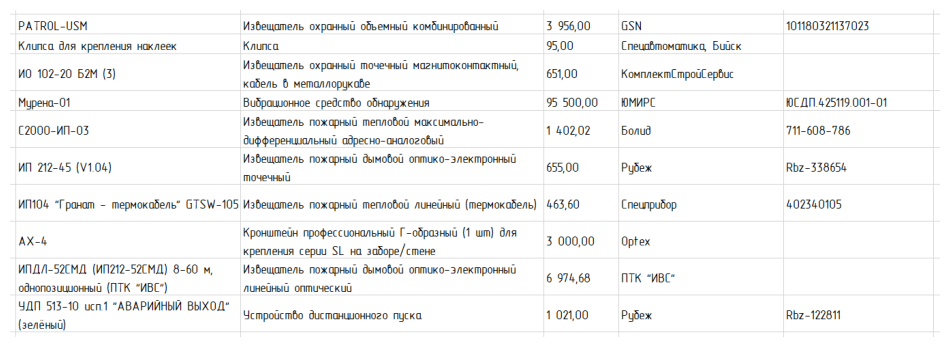

Изображение с обнаруженной таблицей (время: 0.085 секунд):


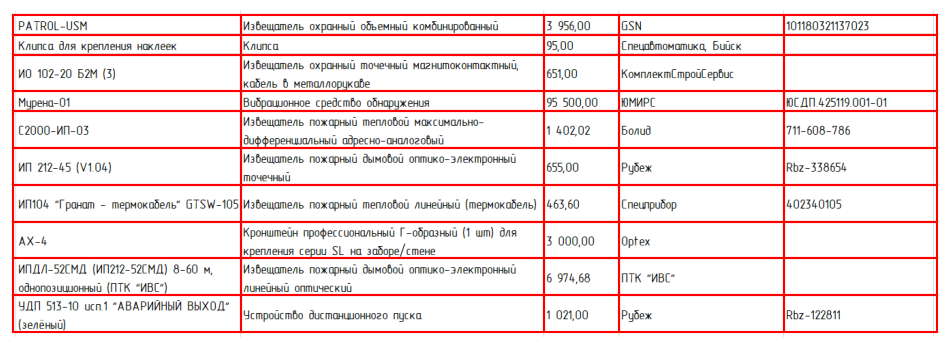

Изображение с найденными ограничивающими рамками:


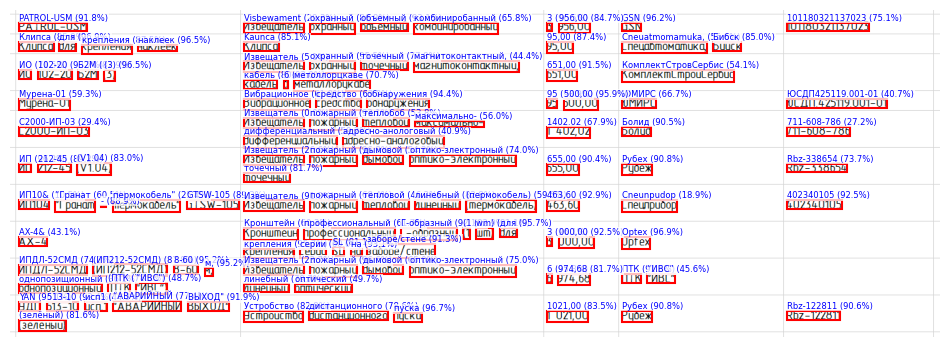

Распознанная таблица сохранена в ./results_3/table_4_gost_100.xlsx
Затраченное время: 1.528 секунд
Всего ошибок: 78
Точность распознавания: 0.915


,0,1,2,3,4
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","Cneuatmomamuka, Бибск",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 метоллорцкаве","651,00",КомплектСтровСербис,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП425119.001-01
4,С2000-ИП-03,Извещатель пожарный теплобоб максимально- дифференциальный адресно-анологовый,1402.02,Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-злектронный точечный,"655,00",Рубех,Rbz-338654
6,"ИП10& “Гранат - пермокобель"" GTSW-105",Извещатель пожарный тепловой линебный (пермокобель),"463,60",Cneunpudop,402340105
7,AX-4&,Кронштейн профессиональный Г-образный (1 wm) для крепления серии SL на заборе/стене,"3 000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м, однопозищионный (ПТК “ИВС"")",Извещатель пожарный дымовой оптико-злектронный линебный оптический,"6 974,68",ПТК “ИВС”,
9,"YAN 513-10 исп1 “АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устробство дистанционного пуска,"1021,00",Рубех,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_070.png


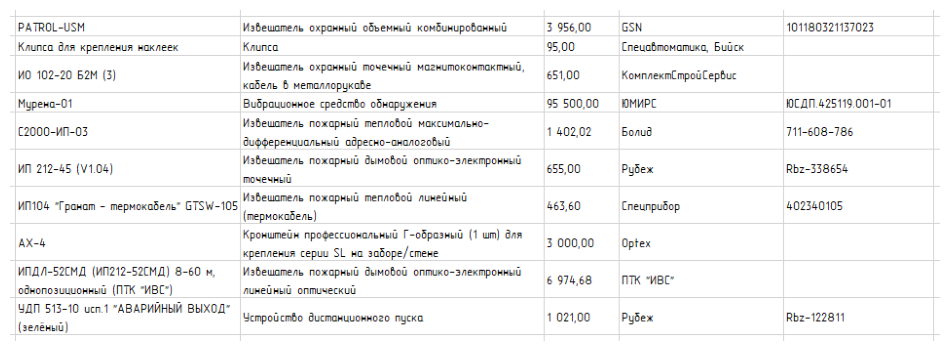

Изображение с обнаруженной таблицей (время: 0.049 секунд):


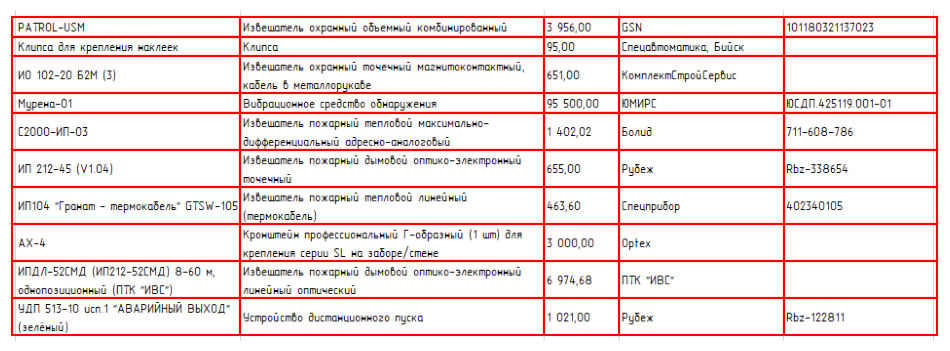

Изображение с найденными ограничивающими рамками:


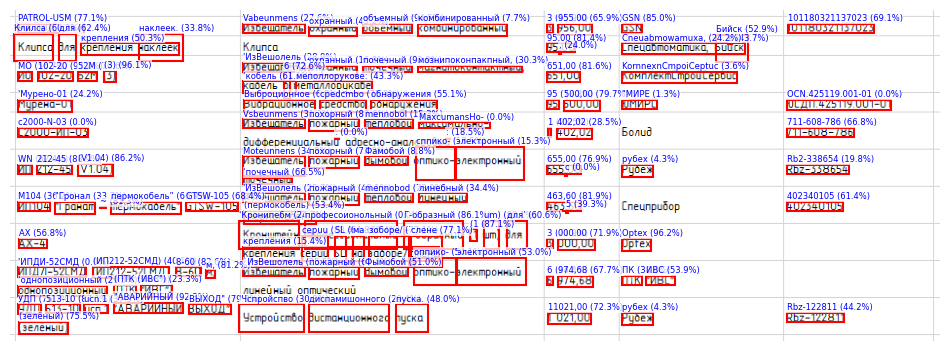

Распознанная таблица сохранена в ./results_3/table_4_gost_070.xlsx
Затраченное время: 1.359 секунд
Всего ошибок: 299
Точность распознавания: 0.673


,0,1,2,3,4
0,PATROL-USM,Vabeunmens охранный объемный комбинированный,3 955.00,GSN,101180321137023
1,Клилса для крепления наклеек.,,"95,00 ,","в Cneuabmowamuxa, Бийск",
2,MO 102-20 52M (3),"'ИзВешолель охранный почечный мознипоконпакпный, ‘кобель 6 меполлорукове:","651,00",KornnexnCmpoiCeptuc,
3,'Мурено-01,Выброционное cpedcmbo обнаружения,"95 500,00","""МИРЕ",OCN.425119.001-01
4,c2000-N-03,Vsbeunmens похорный mennobol MaxcumansHo- . :,"1 402,02",,711-608-786
5,WN 212-45 (V1.04),Moteunnens похорный Фамобой сппико- электронный ‘почечный,"655,00 с",рубех,Rb2-338654
6,"M104 ""Гронал ~ пермокобель” GTSW-105",'ИзВешолель пожарный mennobod линебный (пермокобель),"463,60 5",,402340105
7,АХ,'Кронипебм професоионольный Г-образный (1 um) для’ крепления cepuu SL ма зоборе/ слене,3 000.00,Optex,
8,"'ИПДИ-52СМД (ИП212-52СМД) 8-60 м, ‘однопозиционный (ПТК ИВС"")",`ИзВешолель пожарный Фымобой оппико- электронный,"6 974,68",ПК ИВС,
9,"УДП 513-10 ucn.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",'Чспройспво диспамишонного пуска.,"11021,00",рубех,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_contrast_130.png


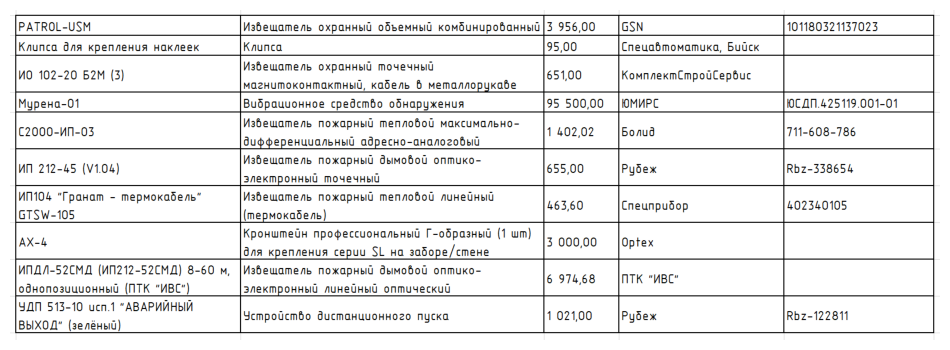

Изображение с обнаруженной таблицей (время: 0.145 секунд):


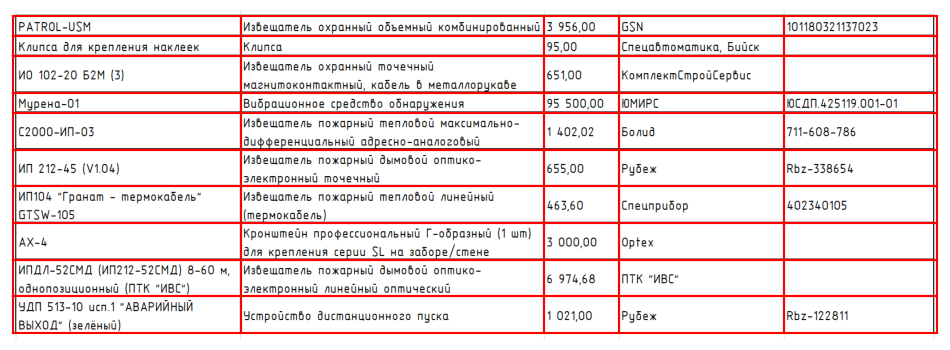

Изображение с найденными ограничивающими рамками:


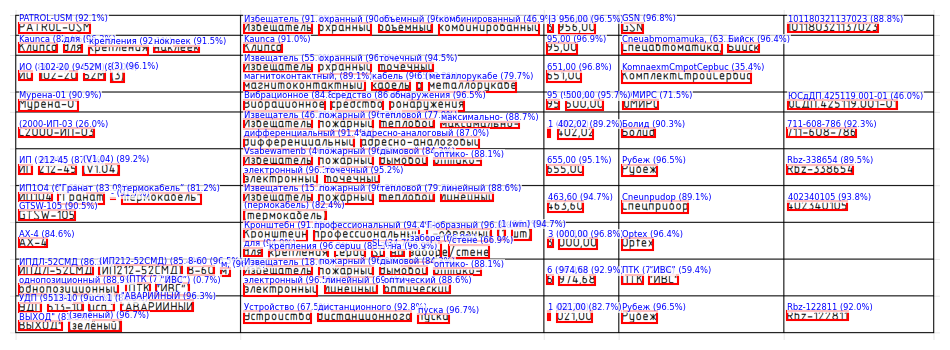

Распознанная таблица сохранена в ./results_3/table_4_gost_contrast_130.xlsx
Затраченное время: 2.154 секунд
Всего ошибок: 96
Точность распознавания: 0.895


,0,1,2,3,4
0,PATROL-USM,Избещатель охранный объемный комбинированный,"|3 956,00",GSN,101180321137023
1,Kaunca для крепления ноклеек,Kaunca,"95,00","Cneuabmomamuka, Бийск",
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00",KomnaexmCmpotCepbuc,
3,Мурена-01,Вибрационное средство обнаружения,"95 500,00",ЮМИРС,ЮСдДП.425119.001-01
4,(2000-ИП-03,Извещатель пожарный тепловой максимально- дифференциальный адресно-аналоговый,"1 402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Vsabewamenb пожарный дымовой оптико- электронный точечный,"655,00",Рубеж,Rbz-338654
6,"ИП1О4 ""Гранат - термокабель” GTSW-105",Извещатель пожарный тепловой линейный (пермокабель),"463,60",Cneunpudop,402340105
7,АХ-4,Кронштебн профессиональный Г-образный (1 wm) для крепления cepuu SL на заборе /стене,"3 000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м, однопозиционный (ПТК _“ИВС”)",Извещатель пожарный дымовой оптико- электронный линейный оптический,"6 974,68",ПТК “ИВС”,
9,"УДП 513-10 ucn.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устройство дистанционного пуска,"1 021,00",Рубеж,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_contrast_100.png


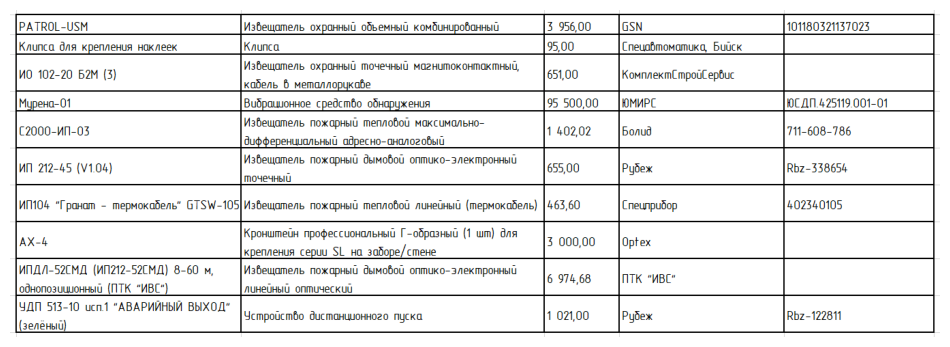

Изображение с обнаруженной таблицей (время: 0.126 секунд):


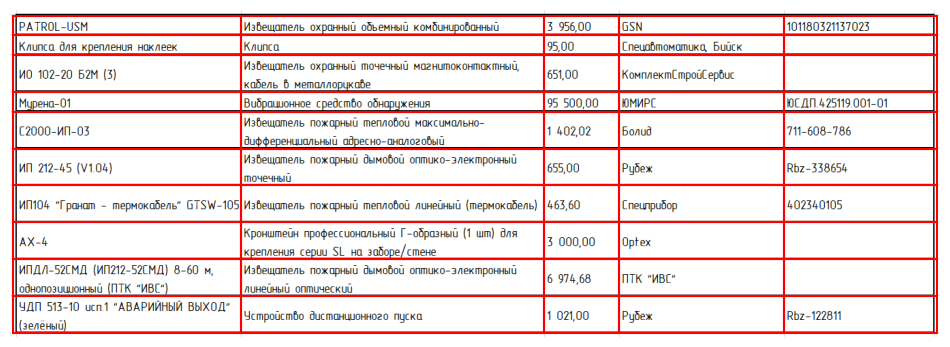

Изображение с найденными ограничивающими рамками:


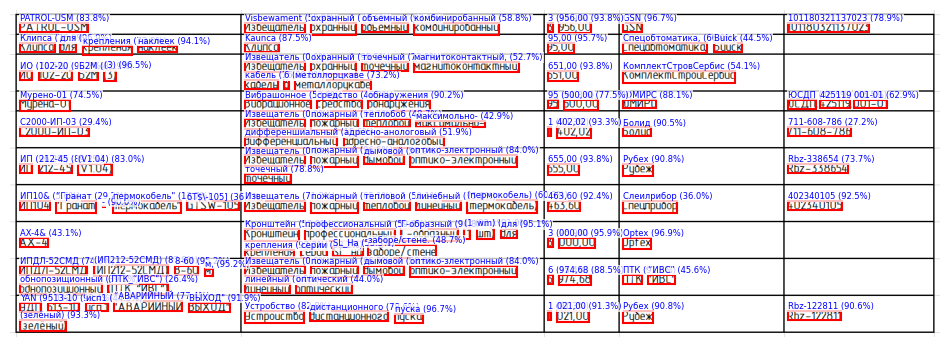

Распознанная таблица сохранена в ./results_3/table_4_gost_contrast_100.xlsx
Затраченное время: 1.754 секунд
Всего ошибок: 78
Точность распознавания: 0.915


,0,1,2,3,4
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00",GSN,101180321137023
1,Клипса для крепления наклеек,Kaunca,"95,00","Спецобтоматика, Buick",
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 метоллорцкаве","651,00",КомплектСтровСербис,
3,Мурено-01,Вибрашонное средство обнаружения,"95 500,00",ЮМИРС,ЮСДП 425119 001-01
4,С2000-ИП-03,Извещатель пожарный теплобоб максимольно- дифференшиальный адресно-анологовый,"1 402,02",Болид,711-608-786
5,ИП 212-45 (V1.04),Извещатель пожарный дымовой оптико-злектронный точечный,"655,00",Рубех,Rbz-338654
6,"ИП10& “Гранат - пермокобель"" бТ$\-105]",Извещатель пожарный тепловой линебный (пермокобель),"463,60",Слеилрибор,402340105
7,AX-4&,Кронштейн профессиональный Г-образный (1 wm) для крепления серии SL_Ha заборе/стене.,"3 000,00",Optex,
8,"ИПДЛ-52СМД (ИП212-52СМД) 8-60 м, обнопозищионный (ПТК_“ИВС"")",Извещатель пожарный дымовой оптико-злектронный линейный оптический,"6 974,68",ПТК “ИВС”,
9,"YAN 513-10 исп1 “АВАРИЙНЫЙ ВЫХОД"" (зелёный)",Устробство дистанционного пуска,"1 021,00",Рубех,Rbz-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_4_gost_contrast_070.png


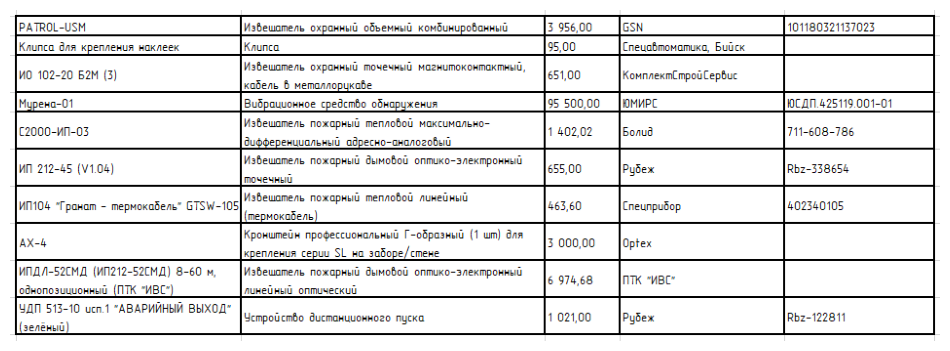

Изображение с обнаруженной таблицей (время: 0.061 секунд):


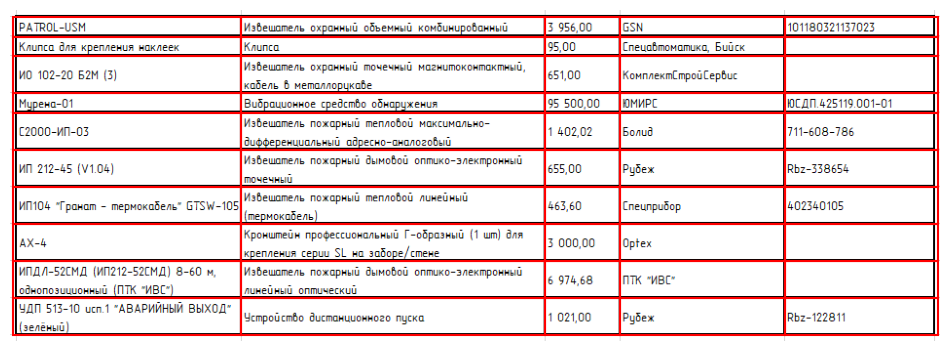

Изображение с найденными ограничивающими рамками:


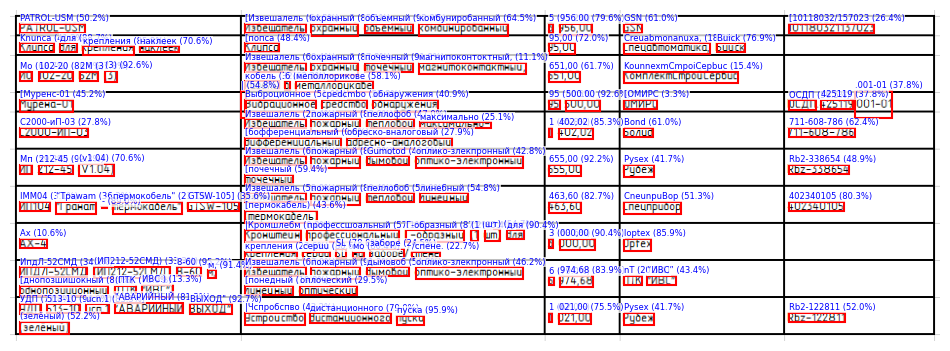

Распознанная таблица сохранена в ./results_3/table_4_gost_contrast_070.xlsx
Затраченное время: 1.558 секунд
Всего ошибок: 226
Точность распознавания: 0.752


,0,1,2,3,4
0,PATROL-USM,[Извешалель охранный объемный комбуниробанный,5 956.00,GSN,[10118032/157023
1,Knunca для крепления наклеек,[попса,"95,00","Creuabmonanuxa, Buick",
2,Mo 102-20 2M (3),"Извешалель охранный почечный магнипоконтоктный, кобель 6 меполлорикове","651,00",KounnexmCmpoiCepbuc,
3,[Муренс-01,| Выброционное cpedcmbo обнаружения,95 500.00,[ОМИРС,ОСДП 425119 .001-01
4,С2000-иП-03,Извешалель пожарный пеллофоб максимально [бофференциальный обреско-вналоговый,"1 402,02",Bond,711-608-786
5,Мп 212-45 (v1.04),Извешалель пожарный Gumotod оплико-злекпронный [почечный,"655,00",Pysex,Rb2-338654
6,"IMM04 “Tpawam - пермокобель"" GTSW-105]",Извешалель пожарный пеллобоб линебный [пермокабель),"463,60",CneunpuBop,402340105
7,Ах,|Кромшлебм профессшоальный Г-образный (1 шт) для крепления cepuu SL мо заборе /спене.,"3 000,00",loptex,
8,"ИпдЛ-52СМД (ИП212-52СМД) 8-60 м, [днопозшишокный (ПТК ИВС.)",Извешалель пожарный дымовоб оплико-злекпронный [понедный оплоческий,"6 974,68",nT “ИВС”,
9,"УДП 513-10 ucn.1 ""АВАРИЙНЫЙ ВЫХОД"" (зелёный)",|Чспробспво дистанционного пуска,"1 021,00",Pysex,Rb2-122811



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_130.png


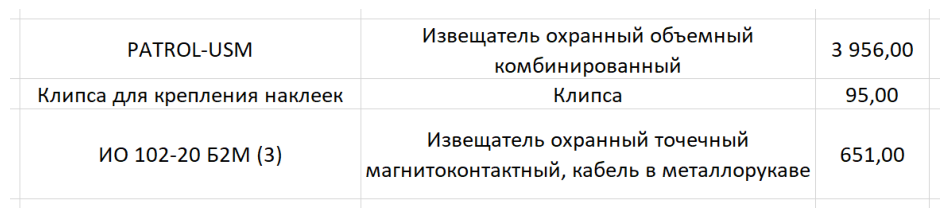

Изображение с обнаруженной таблицей (время: 0.036 секунд):


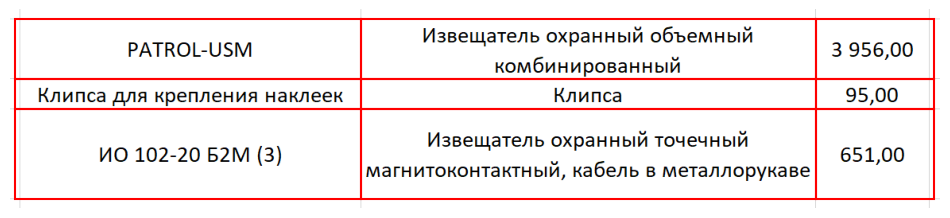

Изображение с найденными ограничивающими рамками:


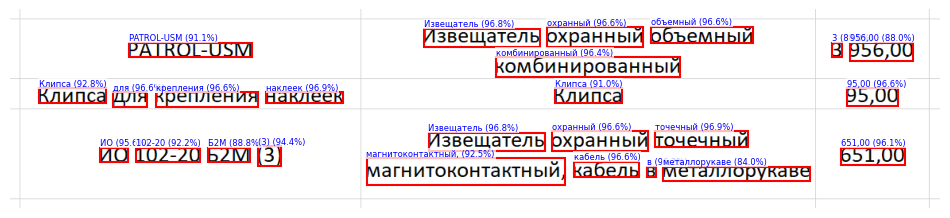

Распознанная таблица сохранена в ./results_3/table_5_base_130.xlsx
Затраченное время: 0.383 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_100.png


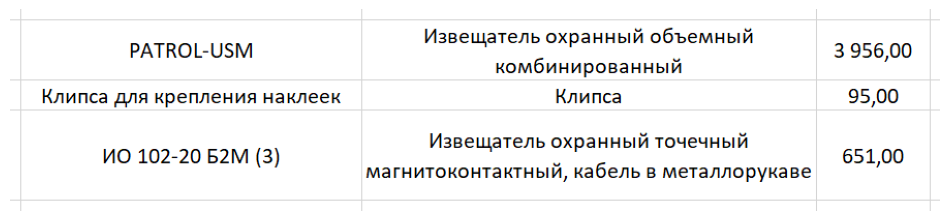

Изображение с обнаруженной таблицей (время: 0.022 секунд):


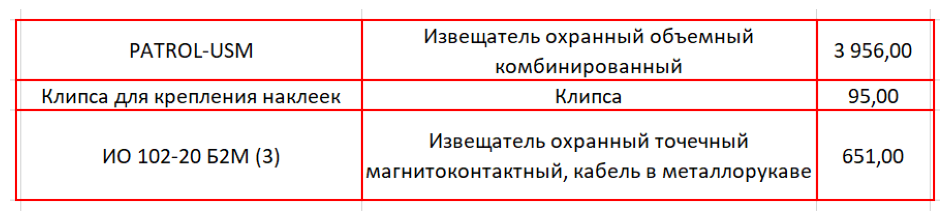

Изображение с найденными ограничивающими рамками:


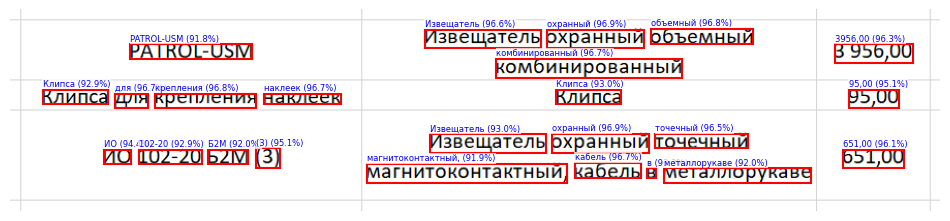

Распознанная таблица сохранена в ./results_3/table_5_base_100.xlsx
Затраченное время: 0.396 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_070.png


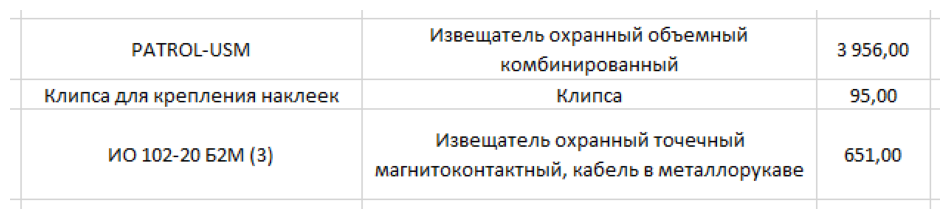

Изображение с обнаруженной таблицей (время: 0.020 секунд):


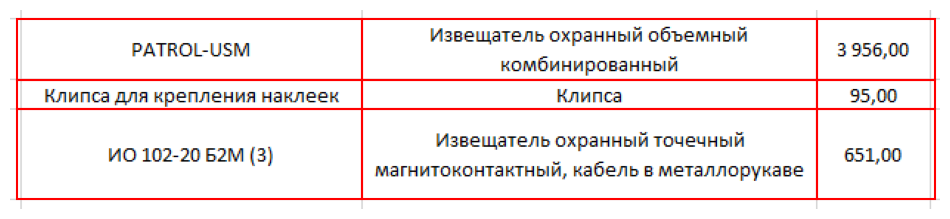

Изображение с найденными ограничивающими рамками:


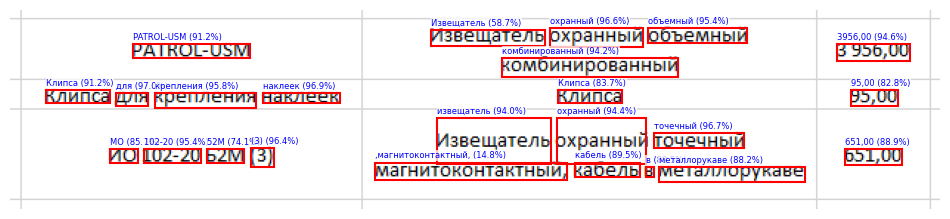

Распознанная таблица сохранена в ./results_3/table_5_base_070.xlsx
Затраченное время: 0.318 секунд
Всего ошибок: 6
Точность распознавания: 0.966


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,MO 102-20 52M (3),"извещатель охранный точечный ‚магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_contrast_130.png


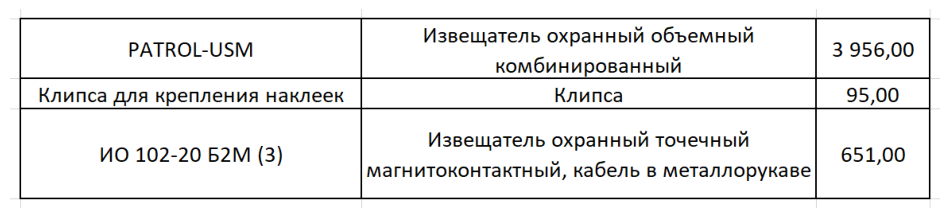

Изображение с обнаруженной таблицей (время: 0.041 секунд):


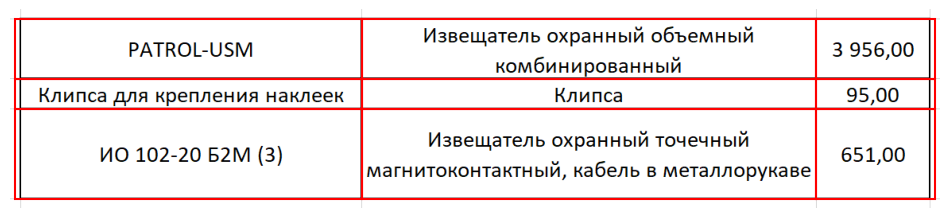

Изображение с найденными ограничивающими рамками:


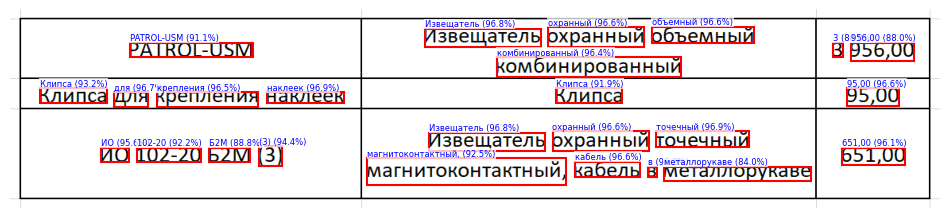

Распознанная таблица сохранена в ./results_3/table_5_base_contrast_130.xlsx
Затраченное время: 0.410 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_contrast_100.png


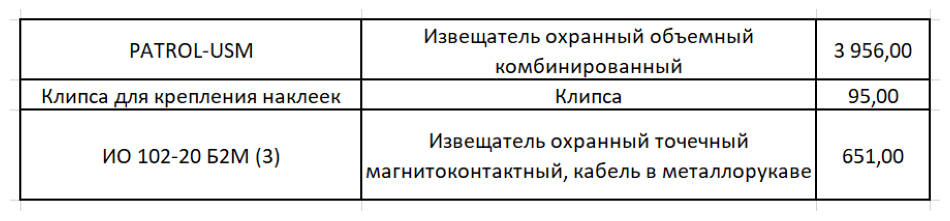

Изображение с обнаруженной таблицей (время: 0.034 секунд):


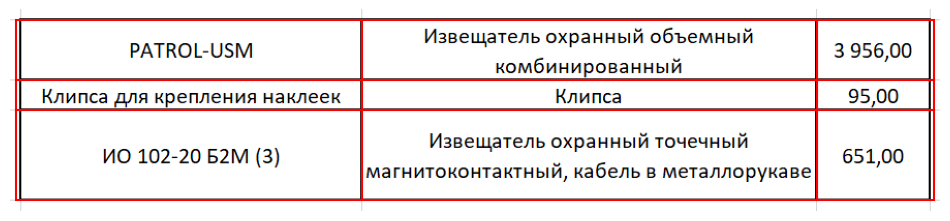

Изображение с найденными ограничивающими рамками:


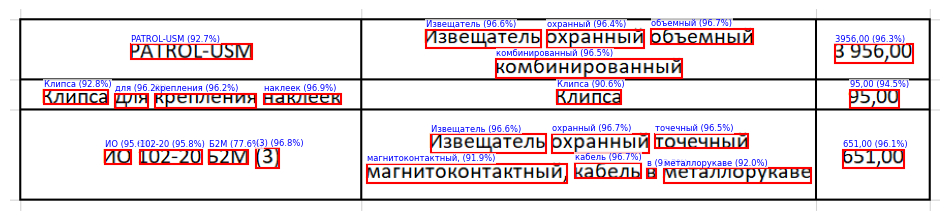

Распознанная таблица сохранена в ./results_3/table_5_base_contrast_100.xlsx
Затраченное время: 0.402 секунд
Всего ошибок: 0
Точность распознавания: 1.000


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель в металлорукаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_base_contrast_070.png


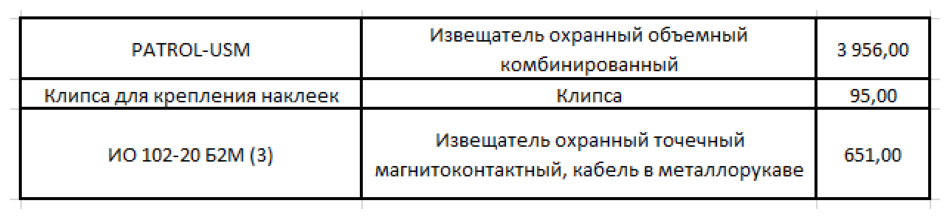

Изображение с обнаруженной таблицей (время: 0.018 секунд):


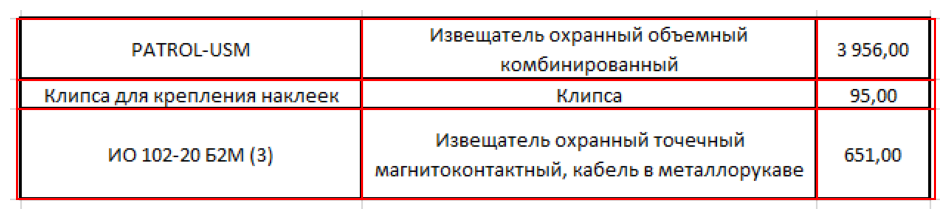

Изображение с найденными ограничивающими рамками:


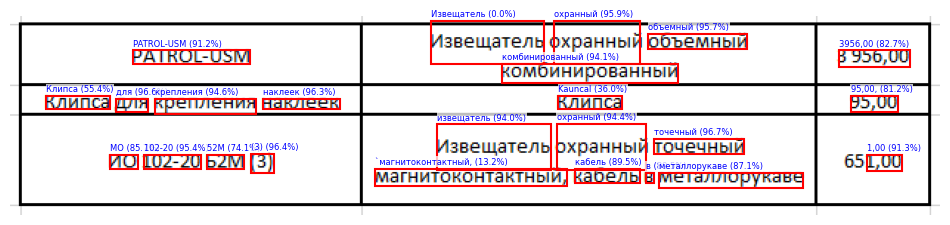

Распознанная таблица сохранена в ./results_3/table_5_base_contrast_070.xlsx
Затраченное время: 0.374 секунд
Всего ошибок: 16
Точность распознавания: 0.910


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3956,00"
1,Клипса для крепления наклеек,Kauncal,"95,00,"
2,MO 102-20 52M (3),"извещатель охранный точечный `магнитоконтактный, кабель в металлорукаве","1,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_130.png


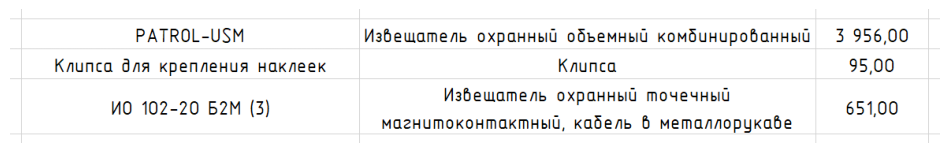

Изображение с обнаруженной таблицей (время: 0.045 секунд):


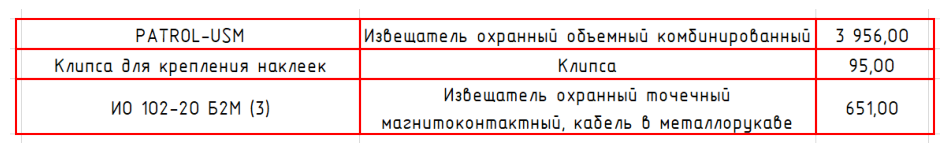

Изображение с найденными ограничивающими рамками:


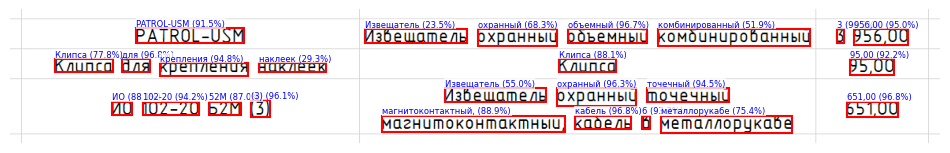

Распознанная таблица сохранена в ./results_3/table_5_gost_130.xlsx
Затраченное время: 0.412 секунд
Всего ошибок: 4
Точность распознавания: 0.978


,0,1,2
0,PATROL-USM,Извещатель охранный объемный комбинированный,"3 956,00"
1,Клипса для крепления наклеек,Клипса,"95,00"
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_100.png


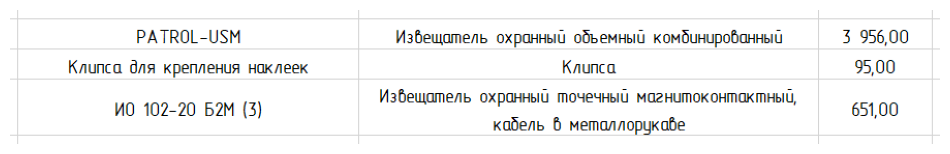

Изображение с обнаруженной таблицей (время: 0.016 секунд):


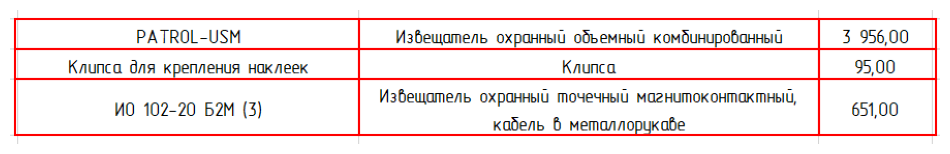

Изображение с найденными ограничивающими рамками:


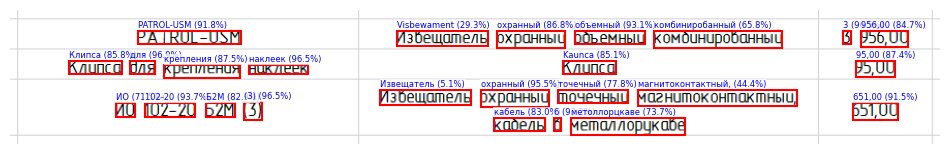

Распознанная таблица сохранена в ./results_3/table_5_gost_100.xlsx
Затраченное время: 0.358 секунд
Всего ошибок: 21
Точность распознавания: 0.882


,0,1,2
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 метоллорцкаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_070.png


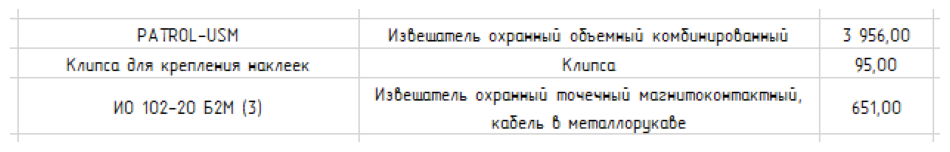

Изображение с обнаруженной таблицей (время: 0.017 секунд):


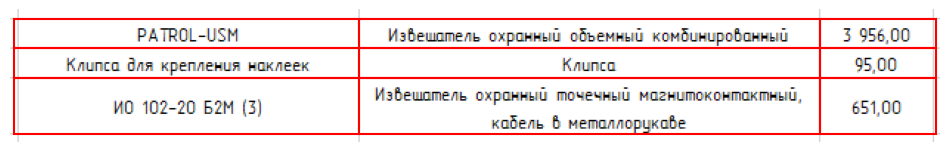

Изображение с найденными ограничивающими рамками:


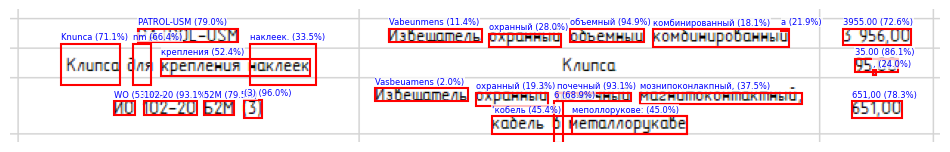

Распознанная таблица сохранена в ./results_3/table_5_gost_070.xlsx
Затраченное время: 0.355 секунд
Всего ошибок: 60
Точность распознавания: 0.663


,0,1,2
0,PATROL-USM,a Vabeunmens охранный объемный комбинированный,3955.00
1,Knunca nm крепления наклеек.,,"35.00 ,"
2,WO 102-20 52M (3),"Vasbeuamens охранный почечный мознипоконлакпный, ‘кобель 6 меполлорукове:","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_contrast_130.png


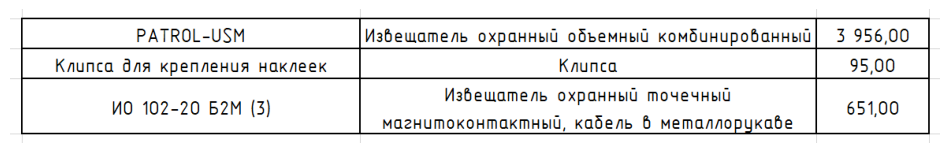

Изображение с обнаруженной таблицей (время: 0.027 секунд):


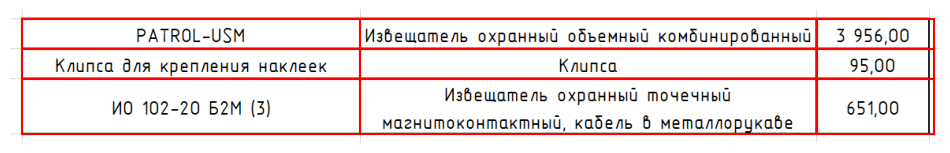

Изображение с найденными ограничивающими рамками:


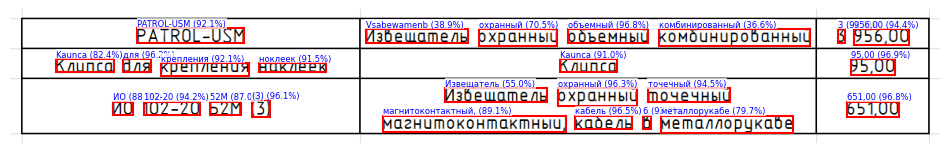

Распознанная таблица сохранена в ./results_3/table_5_gost_contrast_130.xlsx
Затраченное время: 0.451 секунд
Всего ошибок: 28
Точность распознавания: 0.843


,0,1,2
0,PATROL-USM,Vsabewamenb охранный объемный комбинированный,"3 956,00"
1,Kaunca для крепления ноклеек,Kaunca,"95,00"
2,ИО 102-20 52M (3),"Извещатель охранный точечный магнитоконтактный, кабель 6 металлорукабе","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_contrast_100.png


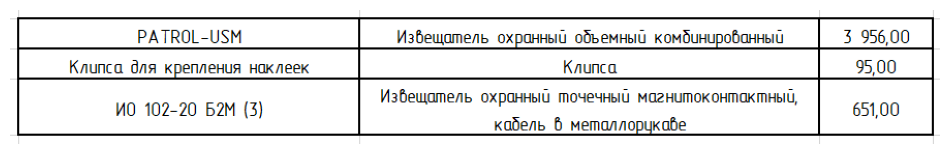

Изображение с обнаруженной таблицей (время: 0.020 секунд):


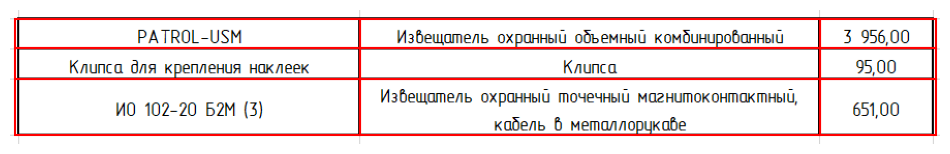

Изображение с найденными ограничивающими рамками:


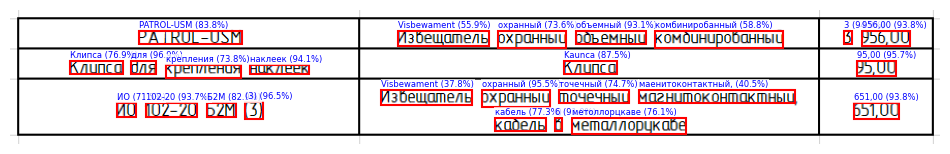

Распознанная таблица сохранена в ./results_3/table_5_gost_contrast_100.xlsx
Затраченное время: 0.366 секунд
Всего ошибок: 33
Точность распознавания: 0.815


,0,1,2
0,PATROL-USM,Visbewament охранный объемный комбиниробанный,"3 956,00"
1,Клипса для крепления наклеек,Kaunca,"95,00"
2,ИО 102-20 Б2М (3),"Visbewament охранный точечный маенитоконтактный, кабель 6 метоллорцкаве","651,00"



----------------------------------------------------------------------------------------------------

Изображение: ./screenshots/table_5_gost_contrast_070.png


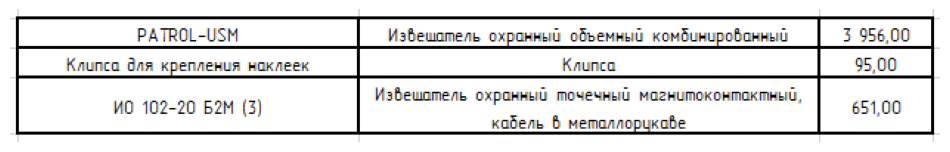

Изображение с обнаруженной таблицей (время: 0.012 секунд):


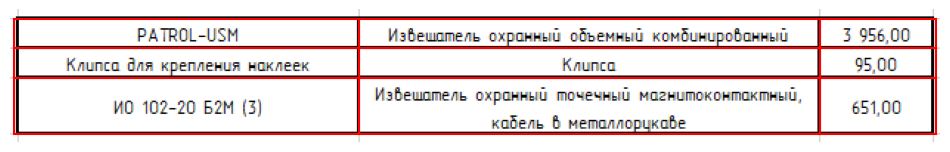

Изображение с найденными ограничивающими рамками:


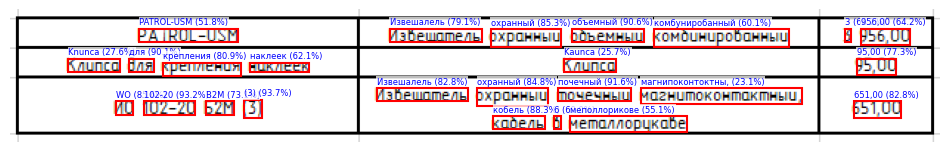

Распознанная таблица сохранена в ./results_3/table_5_gost_contrast_070.xlsx
Затраченное время: 0.431 секунд
Всего ошибок: 32
Точность распознавания: 0.820


,0,1,2
0,PATROL-USM,Извешалель охранный объемный комбуниробанный,"3 956,00"
1,Knunca для крепления наклеек,Kaunca,"95,00"
2,WO 102-20 B2M (3),"Извешалель охранный почечный магнипоконтоктны, кобель 6 меполлорикове","651,00"



----------------------------------------------------------------------------------------------------

Суммарное время распознавания 24 таблиц: 0:00:27


In [ ]:
test_on_grouped_images(
    image_paths[48:72], group_size=3, reverse=True, threshold=0.5,
    verbose=1, draw_text=True, save_to_excel=True,
)